# Evolución de la calidad del aire entre diferentes estaciones de Madrid

**Asignatura:** Aprendizaje Automático en Series Temporales y Flujos de Datos

**Máster:** Inteligencia Artificial Aplicada — UC3M

**Grupo:** Santiago Herron Mulet, Javier Ramírez Zarzoso, Javier Aceituno Monja

## Índice

1. Introducción y contexto
2. Objetivos
3. Conjunto de datos
4. Metodología
5. Carga y preparación de los datos
6. Análisis exploratorio (EDA)
7. Evaluación: partición temporal y baselines
8. Modelado
9. Aplicacin: Alertas y Comparación de zonas.
10. Resultados y conclusiones

## 1. Introducción y contexto

La calidad del aire es algo que afecta en gran medida a la salud de las personas y esto se ve claramente en las grandes ciudades. Madrid lleva más de 25 años midiéndola en muchas estaciones y muchos compuestos diferentes para observarla de manera objetiva y mejorar esta calidad de la aire con diferentes medidas (zonas verdes, zona cero emisiones).

Este proyecto recoge esos datos públicos y se centra en el NO2 como compuesto contaminante objetivo para observar estas dos cuestiones:

- Cómo ha ido cambiando el NO2 en la ciudad en general, con la idea de poder predecir a corto plazo si se acerca un día con niveles altos de contaminación.
- Si hay diferencias claras entre zonas con más vegetación y zonas más urbanas, comparando varias estaciones agrupadas de cada tipo en lugar de fijarnos en una sola estación de cada.

## 2. Objetivos

El objetivo principal es entender cómo evoluciona el NO2 en Madrid y ver si es posible predecirlo con cierta antelación, y si esa predicción sirve para algo concreto. En particular, nos proponemos:

- Construir un indicador que resuma cómo se comporta el NO2 en toda la ciudad, y otro que compare zonas verdes frente a zonas más urbanas.
- Analizar si existen patrones claros (por estación del año, por día de la semana, etc.) que ayuden a entender mejor los datos antes de modelar nada.
- Predecir el NO2 a corto plazo (1 día) y usarlo como aviso temprano ante posibles episodios de contaminación, y a medio plazo (el mes siguiente) para anticipar si se acerca un periodo de concentración alta, con margen para tomar medidas.
- Comparar si las zonas verdes y las urbanas se comportan de forma distinta a lo largo del tiempo, sin afirmar que una cosa cause la otra —apoyándonos en el confinamiento de 2020 como un experimento natural, ya que hay más factores (tráfico, meteorología) de por medio—, y situar esa comparación frente a los límites legales de NO2 vigentes y los ya aprobados para 2030.

## 3. Conjunto de datos

Los datos vienen del portal de datos abiertos del Ayuntamiento de Madrid (datos.madrid.es), dentro del dataset de calidad del aire. Concretamente usamos:

- **Datos de mediciones diarias** (2001-2026): un fichero por año con la concentración media diaria de distintos contaminantes en cada estación de la ciudad. Nos quedamos solo con el NO2.
- **Ficha de estaciones**: un fichero aparte con información de cada estación de medición (nombre, ubicación y tipo: tráfico, fondo urbano o suburbana), que usamos para clasificar las estaciones en "zona verde" o "zona urbana".

De las 24 estaciones de la red, usamos las 3 clasificadas como suburbanas (situadas junto a las grandes zonas verdes de la ciudad: Casa de Campo, El Pardo y Parque Juan Carlos I) como grupo "verde", y las 9 clasificadas como urbanas de tráfico como grupo "urbano".

## 4. Metodología

Antes de entrenar ningún modelo, definimos cómo vamos a evaluar todo, para evitar caer en fugas de información (usar datos del futuro para predecir el pasado, algo muy fácil de hacer por error en series temporales).

- **Horizontes de predicción:** vamos a probar con tres horizontes distintos: 1 día, 1 semana y 1 mes. La idea es comparar cómo cambia la capacidad de predicción según nos alejamos en el tiempo: a corto plazo (1 día) el objetivo es servir de alerta temprana ante posibles picos de contaminación, mientras que a más largo plazo (1 semana y 1 mes) lo que buscamos es más bien capturar la tendencia general. En toda la sección 8, «1 mes» es siempre el valor de un día concreto, 30 días vista, para tratar los tres horizontes de forma homogénea; en la sección 9 lo redefinimos como la media de los 30 días siguientes, una vez vistos los resultados, para una pregunta distinta (si se acerca un mes de concentración alta) que ya no necesita esa homogeneidad.
- **Partición de los datos:** dividimos la serie de forma cronológica: entrenamiento hasta finales de 2024 y test desde 2025 (nunca de forma aleatoria, porque eso rompería el orden temporal y daría resultados poco realistas). Cuando un modelo necesite ajustar hiperparámetros (sección 8.2), se reservará además un tramo de validación anterior al test, sin tocar este último.
- **Modelos de referencia (baseline):** antes de probar nada complejo, comparamos contra dos baselines sencillos: predecir que mañana será igual que hoy, y predecir que mañana será igual que hace una semana. Además, los modelos clásicos de series temporales de la sección 8.1 (AR, MA, ARMA, ARIMA, SARIMA y SARIMAX) se usan como una segunda referencia, algo más elaborada: no son el objetivo del proyecto, pero sirven para ver si los modelos de aprendizaje automático aportan algo más.
- **Métricas:** usamos MAE y RMSE para medir el error de las predicciones, ya que son fáciles de interpretar en las mismas unidades que el NO2.

Esta misma metodología se aplica igual a las tres series que vamos a construir (indicador general, grupo verde y grupo urbano), para que los resultados sean comparables entre sí.

## 5. Carga y preparación de los datos

Empezamos preparando el entorno de trabajo: importamos las librerías necesarias y montamos Google Drive, donde tenemos guardados los ficheros de datos (las mediciones diarias de cada año y la ficha de estaciones). Después cargamos los datos, leemos cada fichero y nos quedamos solo con el NO2. A continuación unimos los diferentes ficheros.

In [1]:
import pathlib

import matplotlib.pyplot as plt
import numpy as np
import pandas as pd

pd.set_option("display.max_columns", 20)

from google.colab import drive

drive.mount('/content/drive')

CARPETA_DATOS = pathlib.Path('/content/drive/MyDrive/AireMadrid')

ficheros_encontrados = sorted(CARPETA_DATOS.glob('aire*.csv'))
assert ficheros_encontrados, (
    f"No se ha encontrado ningún fichero aire*.csv dentro de {CARPETA_DATOS}. "
    "Revisad el nombre de la carpeta en vuestro Drive."
)
print(f"Ficheros de mediciones encontrados: {len(ficheros_encontrados)}")

FICHERO_ESTACIONES = CARPETA_DATOS / 'estaciones_control.csv'
if not FICHERO_ESTACIONES.exists():
    print(
        "AVISO: no se encuentra estaciones_control.csv en la carpeta. "
        "Hace falta para clasificar las estaciones en verde/urbana."
    )
else:
    print("Fichero de metadatos de estaciones encontrado.")

MAGNITUD_NO2 = "8"


def cargar_un_fichero(ruta):
    df = pd.read_csv(ruta, sep=";", encoding="utf-8-sig", dtype=str)
    df.columns = [c.strip('"') for c in df.columns]
    for col in df.columns:
        df[col] = df[col].astype(str).str.strip('"')
    return df


def procesar_un_fichero_no2(df):
    df = df[df["MAGNITUD"].astype(str).str.strip() == MAGNITUD_NO2].copy()
    if df.empty:
        return pd.DataFrame(columns=["fecha", "estacion", "valor", "valido"])

    df = df.reset_index(drop=True)
    df["fila_id"] = df.index

    largo = pd.wide_to_long(df, stubnames=["D", "V"], i="fila_id", j="dia")
    largo = largo.reset_index()

    largo["valor"] = pd.to_numeric(largo["D"], errors="coerce")
    anio = pd.to_numeric(largo["ANO"], errors="coerce")
    mes = pd.to_numeric(largo["MES"], errors="coerce")

    largo["fecha"] = pd.to_datetime(dict(year=anio, month=mes, day=largo["dia"]), errors="coerce")
    largo = largo.dropna(subset=["fecha"])

    largo["valido"] = largo["V"] == "V"
    largo["estacion"] = pd.to_numeric(largo["ESTACION"], errors="coerce").astype("Int64")

    return largo[["fecha", "estacion", "valor", "valido"]]

partes = []
for f in ficheros_encontrados:
    print(f"Procesando {f.name}...")
    df_bruto = cargar_un_fichero(f)
    partes.append(procesar_un_fichero_no2(df_bruto))

no2_largo = pd.concat(partes, ignore_index=True)
no2_largo = no2_largo.sort_values(["estacion", "fecha"]).reset_index(drop=True)

print(f"\nFilas NO2 totales: {len(no2_largo):,}")
print(f"Rango de fechas: {no2_largo['fecha'].min().date()} a {no2_largo['fecha'].max().date()}")
print(f"Estaciones con NO2: {no2_largo['estacion'].nunique()}")
print(f"Proporción de lecturas válidas: {no2_largo['valido'].mean():.2%}")

Mounted at /content/drive
Ficheros de mediciones encontrados: 25
Fichero de metadatos de estaciones encontrado.
Procesando aire2001.csv...
Procesando aire2002.csv...
Procesando aire2003.csv...
Procesando aire2004.csv...
Procesando aire2005.csv...
Procesando aire2006.csv...
Procesando aire2007.csv...
Procesando aire2008.csv...
Procesando aire2009.csv...
Procesando aire2010.csv...
Procesando aire2011.csv...
Procesando aire2012.csv...
Procesando aire2013.csv...
Procesando aire2014.csv...
Procesando aire2015.csv...
Procesando aire2016.csv...
Procesando aire2017.csv...
Procesando aire2018.csv...
Procesando aire2019.csv...
Procesando aire2020.csv...
Procesando aire2021.csv...
Procesando aire2022.csv...
Procesando aire2023.csv...
Procesando aire2024.csv...
Procesando aire2025.csv...

Filas NO2 totales: 184,430
Rango de fechas: 2001-01-01 a 2026-08-31
Estaciones con NO2: 24
Proporción de lecturas válidas: 98.91%


Cargamos la ficha de estaciones y clasificamos cada una en "verde" (suburbana) o "urbana" (tráfico).

In [2]:
estaciones_meta = pd.read_csv(FICHERO_ESTACIONES, sep=";", encoding="utf-8-sig", dtype=str)
estaciones_meta.columns = [c.strip().upper() for c in estaciones_meta.columns]

COLUMNA_CODIGO = "CODIGO_CORTO"
COLUMNA_NOMBRE = "ESTACION"
COLUMNA_TIPO = "NOM_TIPO"

estaciones_meta["_codigo"] = pd.to_numeric(estaciones_meta[COLUMNA_CODIGO], errors="coerce").astype("Int64")

tipo_norm = (
    estaciones_meta[COLUMNA_TIPO]
    .astype(str)
    .str.lower()
    .str.normalize("NFKD")
    .str.encode("ascii", errors="ignore")
    .str.decode("ascii")
)

es_suburbana = tipo_norm.str.contains("suburbana")
es_trafico = tipo_norm.str.contains("trafico")

estaciones_meta["grupo"] = np.select(
    [es_suburbana, es_trafico],
    ["verde", "urbana"],
    default="fondo_urbano_no_usado",
)

codigos_verde = estaciones_meta.loc[estaciones_meta["grupo"] == "verde", "_codigo"].dropna().astype(int).tolist()
codigos_urbana = estaciones_meta.loc[estaciones_meta["grupo"] == "urbana", "_codigo"].dropna().astype(int).tolist()

print(f"Verde: {codigos_verde}")
print(f"Urbana: {codigos_urbana}")

Verde: [24, 58, 59]
Urbana: [4, 8, 11, 36, 38, 39, 48, 50, 56]


Con NO2 filtrado y las estaciones clasificadas, construimos las tres series: media diaria de todas las estaciones, del grupo verde y del grupo urbano.

In [3]:
def serie_agregada(df_largo, codigos_estacion=None):
    datos = df_largo[df_largo["valido"]]
    if codigos_estacion is not None:
        datos = datos[datos["estacion"].isin(codigos_estacion)]
    return datos.groupby("fecha")["valor"].mean().rename("no2")


serie_general = serie_agregada(no2_largo)
serie_verde = serie_agregada(no2_largo, codigos_verde)
serie_urbana = serie_agregada(no2_largo, codigos_urbana)

series = pd.DataFrame({
    "general": serie_general,
    "verde": serie_verde,
    "urbana": serie_urbana,
})

print(series.describe())
series.tail()

           general        verde       urbana
count  9341.000000  9277.000000  9341.000000
mean     40.085545    24.354766    45.708080
std      19.552803    16.042933    21.146327
min       3.000000     1.333333     3.333333
25%      25.086957    12.333333    29.777778
50%      37.818182    20.000000    43.875000
75%      52.166667    32.000000    58.666667
max     133.923077   119.000000   150.833333


,general,verde,urbana
fecha,,,
2026-08-27,6.565217,4.333333,7.000000
2026-08-28,11.260870,10.666667,10.111111
2026-08-29,15.782609,10.000000,15.111111
2026-08-30,21.739130,13.333333,20.222222
2026-08-31,19.086957,11.666667,19.333333


## 6. Análisis exploratorio de datos (EDA)

Antes de modelar, miramos las tres series con calma: cómo evolucionan, si tienen tendencia, estacionalidad, y si son estacionarias (algo clave para los modelos clásicos que veremos en la sección 8.1).

Lo primero será observar a simple vista nuestras series:

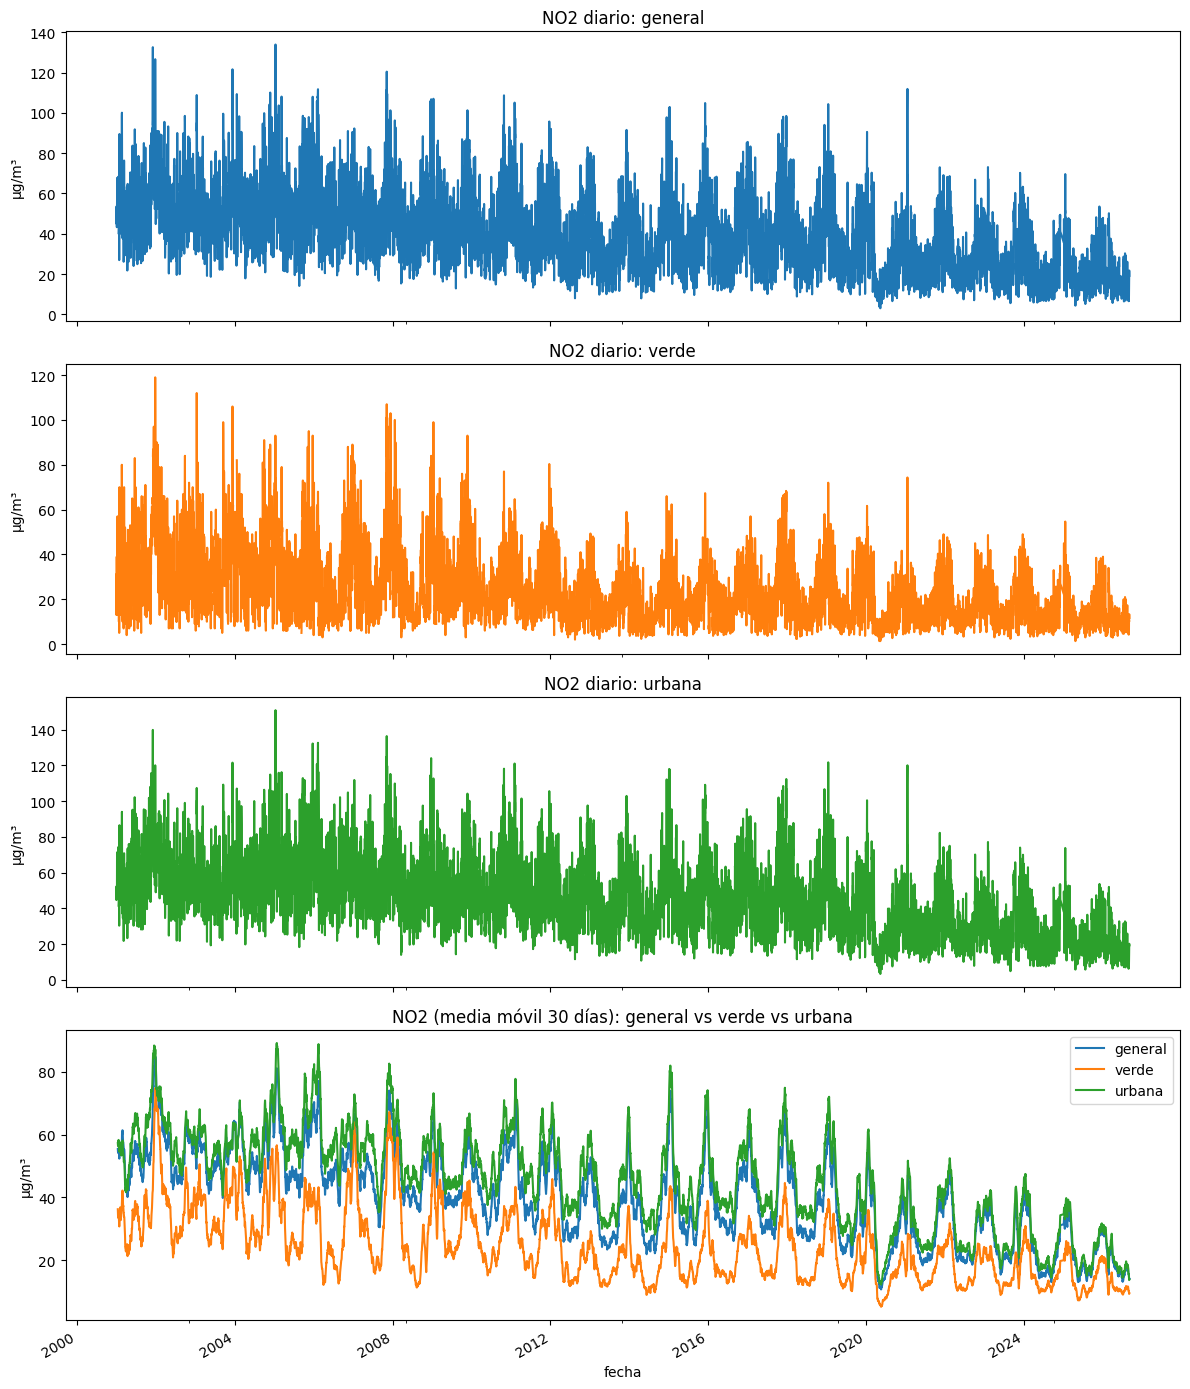

In [4]:
colores = {"general": "tab:blue", "verde": "tab:orange", "urbana": "tab:green"}

fig, axes = plt.subplots(4, 1, figsize=(12, 14), sharex=True)

for ax, col in zip(axes[:3], ["general", "verde", "urbana"]):
    series[col].plot(ax=ax, color=colores[col])
    ax.set_title(f"NO2 diario: {col}")
    ax.set_ylabel("µg/m³")

suavizado = series.rolling(30, min_periods=15).mean()
for col in ["general", "verde", "urbana"]:
    suavizado[col].plot(ax=axes[3], color=colores[col], label=col)
axes[3].set_title("NO2 (media móvil 30 días): general vs verde vs urbana")
axes[3].set_ylabel("µg/m³")
axes[3].legend()

plt.tight_layout()
plt.show()

Lo primero que se observa, común a las tres series, es que al tratarse de casi 26 años de datos diarios, la serie completa es visualmente muy ruidosa y no permite distinguir patrones a simple vista. Por eso se ha usado también su media móvil de 30 días para poder compararlas entre sí.

En esa vista suavizada se aprecia una tendencia levemente descendente en las tres series. Las tres tienen una forma muy similar entre sí, pero en escalas distintas: la serie urbana es la más alta, la general queda ligeramente por debajo, y la verde se sitúa un buen trecho por debajo de ambas. Este orden (urbana > general > verde) es el esperado, dado que el indicador general es una media de todas las estaciones (incluidas las de tráfico, que tiran el promedio hacia arriba) y las estaciones verdes están en zonas con menor densidad de tráfico.

A continuación se analiza cada una de las características restantes de la serie con mayor detalle.

### 6.1 Estacionalidad

La estacionalidad hace referencia a patrones que se repiten con un periodo fijo y conocido. En una serie de calidad del aire tiene sentido esperar dos tipos: estacionalidad anual (por meses, ligada a calefacción, meteorología y menor dispersión atmosférica en invierno) y estacionalidad semanal (laborables vs fin de semana, ligada al tráfico).

Dado que las tres series comparten la misma forma general y solo difieren en escala (como se vio en la sección anterior), a partir de aquí se analiza únicamente la serie general como representativa del patrón común; cuando alguna característica difiera entre grupos, se señalará explícitamente.

Estacionalidad anual:

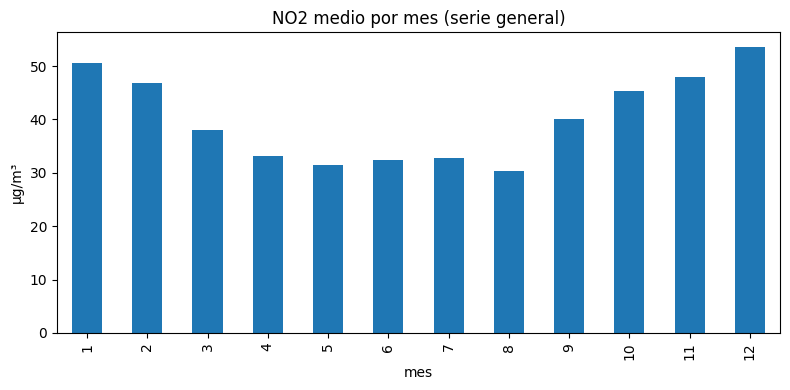

In [5]:
fig, ax = plt.subplots(figsize=(8, 4))
series["general"].groupby(series.index.month).mean().plot(kind="bar", ax=ax, color=colores["general"])
ax.set_title("NO2 medio por mes (serie general)")
ax.set_xlabel("mes")
ax.set_ylabel("µg/m³")
plt.tight_layout()
plt.show()

Se observa una estacionalidad anual clara: los meses de invierno (diciembre, enero, febrero) muestran los niveles más altos de NO2, mientras que los meses de verano (junio, julio, agosto) son los más bajos, con una diferencia notable entre ambos extremos.

Esto tiene una explicación principalmente meteorológica: en invierno, el aire frío cerca del suelo queda "atrapado" bajo una capa de aire más cálido por encima, lo que impide que los contaminantes se dispersen hacia arriba y hace que se acumulen cerca de donde se emiten. En verano ocurre lo contrario: con más calor, el aire se mezcla mejor en altura y los contaminantes se dispersan con más facilidad. Además, el sol fuerte del verano acelera la descomposición química del NO2 en la atmósfera, lo que también ayuda a que sus niveles bajen.

A esto se suman otros factores propios de Madrid: en invierno aumenta el consumo de calefacción, una fuente adicional de emisiones, mientras que en verano buena parte de la población abandona la ciudad por vacaciones, lo que reduce el tráfico y la actividad general.

Estacionalidad semanal:

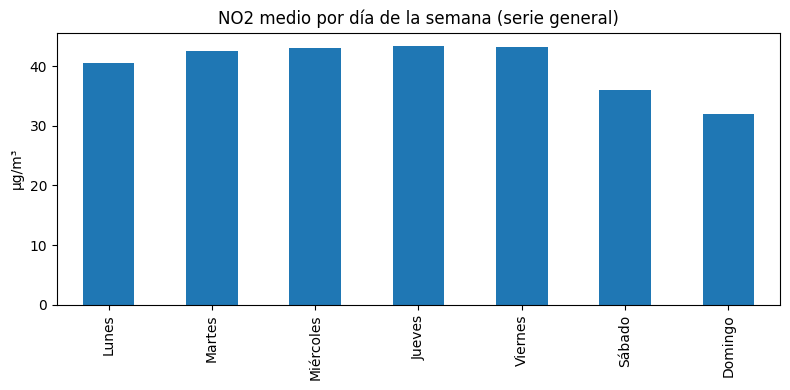

In [6]:
dias_semana = ["Lunes", "Martes", "Miércoles", "Jueves", "Viernes", "Sábado", "Domingo"]

fig, ax = plt.subplots(figsize=(8, 4))
medias_semana = series["general"].groupby(series.index.dayofweek).mean()
medias_semana.index = dias_semana
medias_semana.plot(kind="bar", ax=ax, color=colores["general"])
ax.set_title("NO2 medio por día de la semana (serie general)")
ax.set_ylabel("µg/m³")
plt.tight_layout()
plt.show()

La estacionalidad semanal es mucho más suave que la anual: los cinco días laborables presentan niveles de NO2 similares entre sí, y solo se aprecia un descenso en el fin de semana, algo más marcado el domingo que el sábado. Esto es coherente con el origen del NO2 como contaminante ligado sobre todo al tráfico: entre semana la actividad laboral se mantiene estable día a día, mientras que el fin de semana baja de forma progresiva (el sábado aún hay actividad comercial y de ocio; el domingo es cuando realmente cae el tráfico asociado al trabajo).

### 6.2 Variaciones cíclicas

A diferencia de la estacionalidad, que sigue un calendario fijo y se repite año tras año de forma predecible, las variaciones cíclicas son episodios que rompen el patrón habitual sin un periodo regular. Para detectarlas, comparamos el perfil suavizado de cada año por separado, superponiendo todos los años por día del año: si todos siguen el mismo patrón estacional, las líneas deberían quedar agrupadas entre sí sumando la tendencia descendente; si algún año se sale del patrón, debería destacar del resto.

Una hipótesis razonable es que el año 2020, marcado por la pandemia de COVID-19 y el confinamiento, presente una estructura anómala respecto al resto de años, especialmente en los meses de confinamiento estricto (marzo-junio). Se comprueba esta hipótesis a continuación sobre las gráficas.

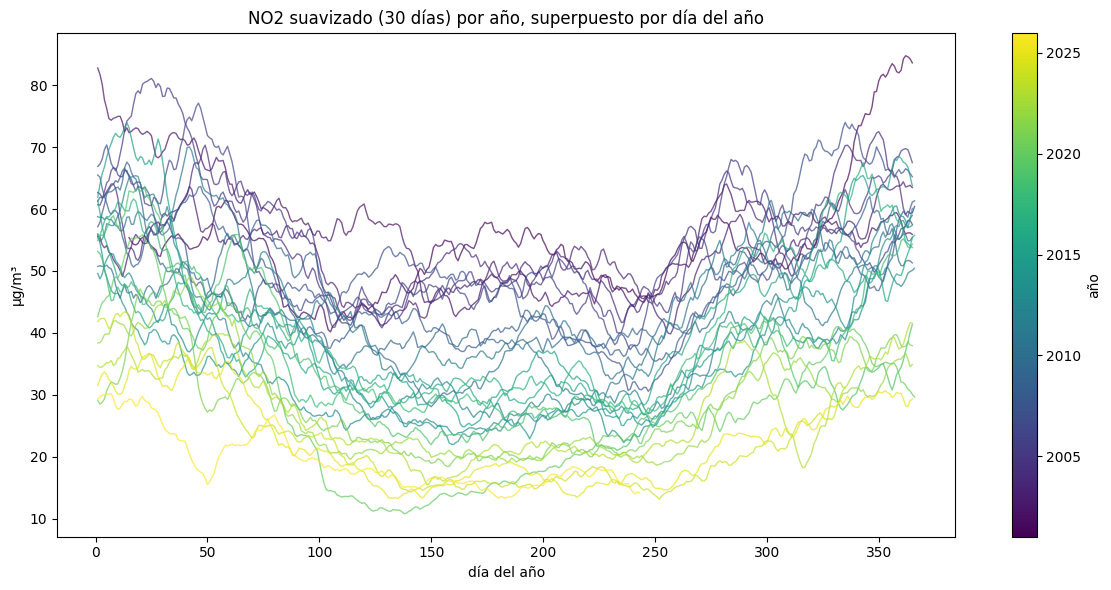

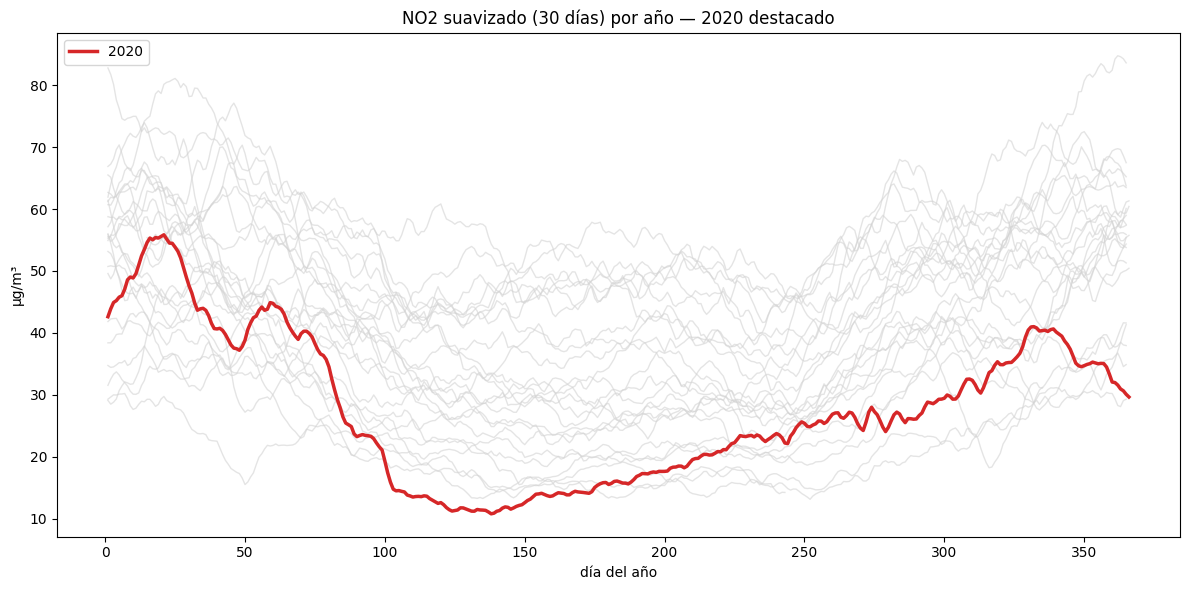

In [7]:
import matplotlib.cm as cm

serie_suave = series["general"].rolling(30, min_periods=15).mean()
anios = serie_suave.index.year.unique()
colores_anio = cm.viridis((anios - anios.min()) / (anios.max() - anios.min()))

fig, ax = plt.subplots(figsize=(12, 6))
for anio, color in zip(anios, colores_anio):
    datos_anio = serie_suave[serie_suave.index.year == anio]
    ax.plot(datos_anio.index.dayofyear, datos_anio.values, color=color, alpha=0.7, linewidth=1)

ax.set_title("NO2 suavizado (30 días) por año, superpuesto por día del año")
ax.set_xlabel("día del año")
ax.set_ylabel("µg/m³")
sm = cm.ScalarMappable(cmap="viridis", norm=plt.Normalize(anios.min(), anios.max()))
fig.colorbar(sm, ax=ax, label="año")
plt.tight_layout()
plt.show()

fig, ax = plt.subplots(figsize=(12, 6))

for anio in anios:
    datos_anio = serie_suave[serie_suave.index.year == anio]
    if anio == 2020:
        continue  # lo pintamos después, encima de todo
    ax.plot(datos_anio.index.dayofyear, datos_anio.values, color="lightgray", alpha=0.6, linewidth=1)

datos_2020 = serie_suave[serie_suave.index.year == 2020]
ax.plot(datos_2020.index.dayofyear, datos_2020.values, color="tab:red", linewidth=2.5, label="2020")

ax.set_title("NO2 suavizado (30 días) por año — 2020 destacado")
ax.set_xlabel("día del año")
ax.set_ylabel("µg/m³")
ax.legend()
plt.tight_layout()
plt.show()

Efectivamente, al superponer los perfiles de todos los años se observa que 2020 se separa claramente del resto justo en la franja de marzo a junio, coincidiendo con el periodo de confinamiento estricto por el COVID-19: mientras el resto de años se mantienen agrupados en el descenso hacia los valores mínimos de primavera-verano, la línea de 2020 cae muy por debajo de todo el haz en esa misma zona. Fuera de ese periodo, sin embargo, 2020 vuelve a converger con el resto de años, lo que confirma que se trata de una ruptura puntual y localizada en el tiempo (una variación cíclica), y no de un cambio en la tendencia general de la serie.

Esto es coherente con la reducción drástica del tráfico y la actividad económica durante el confinamiento, principal fuente de emisiones de NO2 en la ciudad.

### 6.3 Fluctuaciones aleatorias/irregulares

Una vez identificados la tendencia, la estacionalidad y las variaciones cíclicas (el episodio de 2020), lo que queda en la serie es el componente irregular: variación día a día que no sigue ningún patrón conocido y que, en principio, no debería ser predecible. Para aislarlo, se descompone la serie en tendencia + estacionalidad + residuo mediante STL, y se analiza este último componente: si de verdad es ruido, debería comportarse como una variable centrada en torno a cero y sin estructura visible.

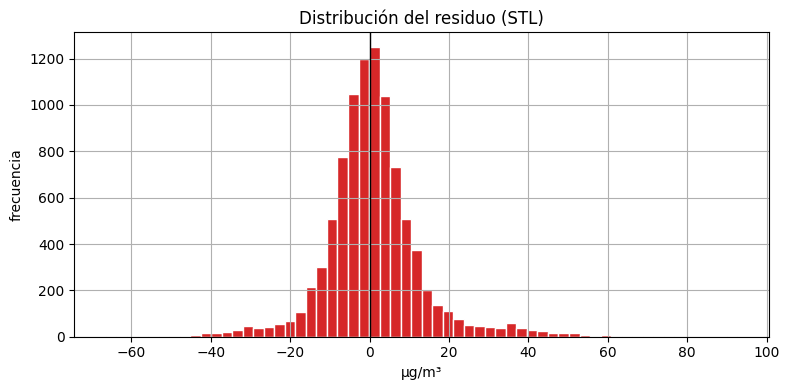

Media del residuo: 0.941
Desviación típica del residuo: 12.496


In [8]:
from statsmodels.tsa.seasonal import STL

serie_diaria = series["general"].interpolate(limit=7)
resultado_stl = STL(serie_diaria, period=365, robust=True).fit()

fig, ax = plt.subplots(figsize=(8, 4))
resultado_stl.resid.hist(bins=60, ax=ax, color="tab:red", edgecolor="white")
ax.axvline(0, color="black", linewidth=1)
ax.set_title("Distribución del residuo (STL)")
ax.set_xlabel("µg/m³")
ax.set_ylabel("frecuencia")
plt.tight_layout()
plt.show()

print(f"Media del residuo: {resultado_stl.resid.mean():.3f}")
print(f"Desviación típica del residuo: {resultado_stl.resid.std():.3f}")

El residuo tiene una media prácticamente cero (0,94 µg/m³, un valor muy pequeño frente a los niveles habituales de la serie) y se distribuye en forma de campana centrada en cero. Esto confirma que se comporta como ruido: no sigue ningún patrón, una vez quitados la tendencia, la estacionalidad y el episodio de 2020.

También se ve algo de asimetría: hay más valores altos que bajos (una cola más larga hacia la derecha). Tiene sentido, porque los picos de contaminación (más tráfico, mal tiempo) hacen que algunos días suban mucho, mientras que hacia abajo el margen es más limitado, ya que el NO2 no puede bajar de niveles cercanos a cero.

### 6.4 Estacionariedad

Una serie es estacionaria cuando su comportamiento no cambia con el tiempo: la media se mantiene más o menos igual, no hay una tendencia que la haga subir o bajar, y la variabilidad tampoco cambia. Ya sabemos que nuestra serie tiene una tendencia descendente, así que lo normal es que NO sea estacionaria.

Para comprobarlo de forma más rigurosa (no solo "a ojo"), se usa un test estadístico llamado Dickey-Fuller aumentado (ADF). Funciona al revés de lo que se podría pensar: parte asumiendo que la serie NO es estacionaria, y solo si el resultado (el p-valor) es muy bajo (menor que 0,05) se puede concluir que sí lo es.

In [9]:
from statsmodels.tsa.stattools import adfuller

resultado_adf = adfuller(series["general"].dropna())

print(f"Estadístico ADF: {resultado_adf[0]:.3f}")
print(f"p-valor: {resultado_adf[1]:.4f}")
print("Valores críticos:")
for nivel, valor in resultado_adf[4].items():
    print(f"  {nivel}: {valor:.3f}")

Estadístico ADF: -5.555
p-valor: 0.0000
Valores críticos:
  1%: -3.431
  5%: -2.862
  10%: -2.567


/tmp/ipykernel_528/1518554861.py:3: FutureWarning: adfuller currently returns a plain tuple whose length depends on the store and autolag arguments. In release 0.16 or after July 2027, whichever is later, the default behavior will switch to always returning an ADFullerResult. Set result_object=True to switch now, or result_object=False to keep the current behavior and silence this warning.
  resultado_adf = adfuller(series["general"].dropna())


In [10]:
resultado_adf_ct = adfuller(series["general"].dropna(), regression="ct")

print(f"Estadístico ADF (con tendencia): {resultado_adf_ct[0]:.3f}")
print(f"p-valor: {resultado_adf_ct[1]:.4f}")
print("Valores críticos:")
for nivel, valor in resultado_adf_ct[4].items():
    print(f"  {nivel}: {valor:.3f}")

Estadístico ADF (con tendencia): -8.470
p-valor: 0.0000
Valores críticos:
  1%: -3.960
  5%: -3.411
  10%: -3.127


/tmp/ipykernel_528/3737224491.py:1: FutureWarning: adfuller currently returns a plain tuple whose length depends on the store and autolag arguments. In release 0.16 or after July 2027, whichever is later, the default behavior will switch to always returning an ADFullerResult. Set result_object=True to switch now, or result_object=False to keep the current behavior and silence this warning.
  resultado_adf_ct = adfuller(series["general"].dropna(), regression="ct")


El primer test ADF dio un p-valor prácticamente 0, indicando que la serie es estacionaria. Esto puede sorprender porque la serie tiene una tendencia descendente clara. Pero conviene distinguir dos cosas: tener tendencia (la serie sube o baja con el tiempo, algo que ya sabíamos) no es lo mismo que no ser estacionaria (que la serie se aleje sin control y nunca vuelva a su comportamiento habitual).

Para comprobarlo con más cuidado, se repite el test permitiendo explícitamente que exista una tendencia en el modelo (parámetro `regression="ct"`). El resultado es aún más claro que el anterior (p-valor prácticamente 0, estadístico todavía más extremo), lo que confirma que la serie es "estacionaria en tendencia": tiene una deriva lenta y estable de fondo, pero las subidas y bajadas del día a día siempre vuelven a esa tendencia en vez de acumularse sin límite (como sí ocurriría en un paseo aleatorio).

Ojo: que la serie sea estacionaria en tendencia no significa que la tendencia se pueda ignorar al modelar. En la sección 8.1 se prueba tanto sin diferenciar como diferenciando una vez (el parámetro d del ARIMA) y se comparan los resultados.

### 6.5 Autocorrelación (ACF/PACF)

La autocorrelación mide cuánto se parece el valor de la serie en un día a su valor en días anteriores (unos días de diferencia, o "lag"). La función de autocorrelación (ACF) mide esa relación con cada lag, incluyendo efectos indirectos (por ejemplo, si hoy se parece mucho a ayer, y ayer se parece mucho a anteayer, la ACF también verá algo de relación entre hoy y anteayer aunque no sea directa). La función de autocorrelación parcial (PACF) aísla la relación directa con cada lag, descontando esos efectos indirectos.

Esto es justo lo que necesitamos para decidir, más adelante, cuántos días atrás merece la pena mirar al construir los modelos (los lags que se usarán en 8.1 y 8.2).

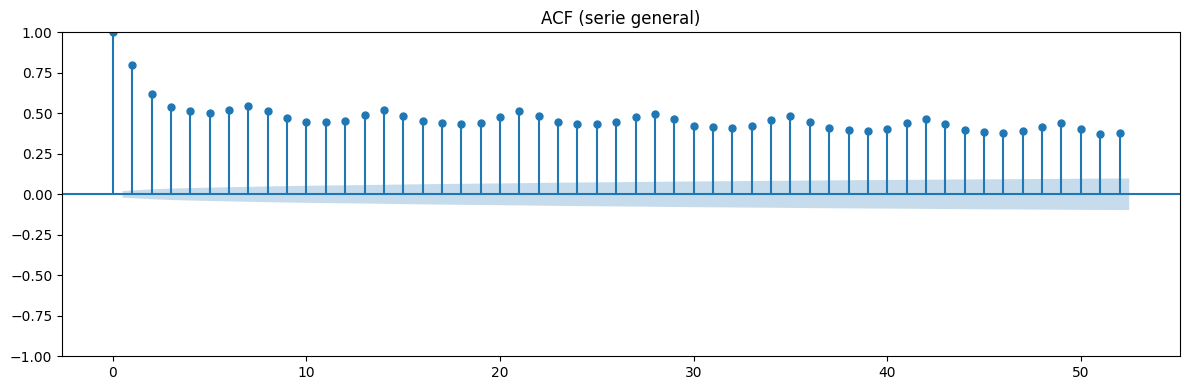

In [11]:
from statsmodels.graphics.tsaplots import plot_acf

fig, ax = plt.subplots(figsize=(12, 4))
plot_acf(series["general"].dropna(), lags=52, ax=ax, color=colores["general"])
ax.set_title("ACF (serie general)")
plt.tight_layout()
plt.show()

Se observa una autocorrelación muy alta en el lag 1 (≈0,80) que cae de forma notable en el lag 2 (≈0,62) y luego se estabiliza en torno a 0,40-0,55 durante el resto de lags mostrados (hasta 40), sin apenas tendencia a decaer más. Todos los valores quedan claramente fuera de la banda de confianza (la zona sombreada en azul), lo que indica que la correlación es estadísticamente significativa en todos los lags analizados, no solo en los primeros días.

Esta caída inicial rápida seguida de una "meseta" persistente es típica de una serie con fuerte dependencia a corto plazo (el valor de hoy se parece mucho al de ayer y anteayer) combinada con una componente de más largo plazo que la ACF no logra aislar bien, porque al ser una medida acumulativa arrastra efectos indirectos: si el lag 1 está muy correlacionado consigo mismo en cadena, la ACF sigue viendo "algo" de relación incluso en lags donde no hay conexión directa. Es coherente con lo visto en la sección 6.1 (estacionalidad anual) y 6.4 (serie estacionaria en tendencia): parte de esa meseta puede deberse al ciclo anual.

Para separar qué parte de esa relación es directa y qué parte es efecto de arrastre, hace falta mirar la PACF, que es lo que se analiza a continuación.

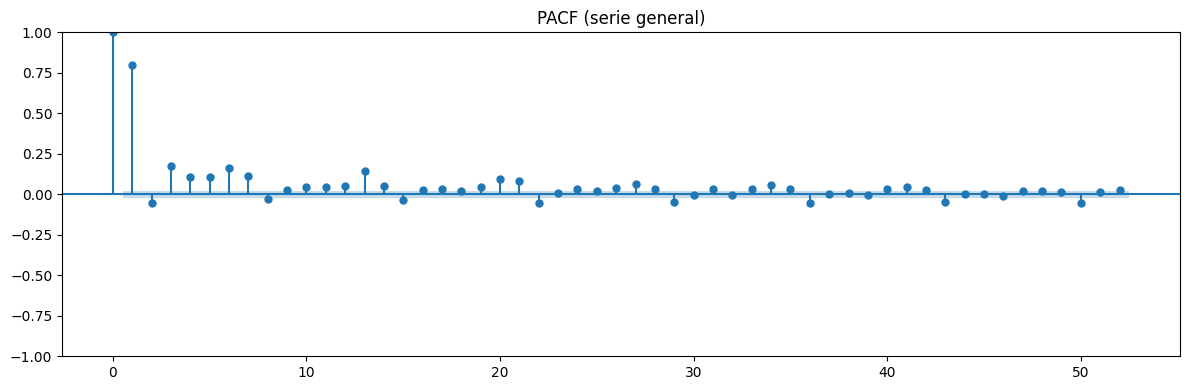

In [12]:
from statsmodels.graphics.tsaplots import plot_pacf

fig, ax = plt.subplots(figsize=(12, 4))
plot_pacf(series["general"].dropna(), lags=52, ax=ax, method="ywm", color=colores["general"])
ax.set_title("PACF (serie general)")
plt.tight_layout()
plt.show()

La PACF confirma lo que la ACF dejaba entrever: una vez descontados los efectos indirectos, la relación directa de la serie con su pasado se concentra casi por completo en el lag 1 (≈0,80). A partir de ahí los valores caen mucho y quedan, en su gran mayoría, dentro o muy cerca de la banda de confianza, lo que indica que los lags 2 en adelante aportan poca información adicional una vez que ya se conoce el valor de ayer.

Se aprecian algunos picos puntuales algo por encima del resto —en torno a los lags 3-7 y de nuevo cerca del lag 13 y 19-21— aunque de magnitud mucho menor (0,10-0,20) que el lag 1. Estos pequeños repuntes podrían estar recogiendo un resto de estructura semanal (recordando la estacionalidad semanal suave vista en 6.1) más que una relación fuerte y sistemática.

De cara al modelado (secciones 8.1 y 8.2), la gráfica sugiere usar como predictor principal el lag 1 (NO2 de ayer), complementado quizá con algún lag semanal (7) para capturar el patrón laborable/fin de semana, sin necesidad de incluir muchos más lags individuales, ya que su aportación marginal parece pequeña.

## 7. Evaluación: partición temporal y baselines

Antes de construir la partición temporal y los baselines, conviene revisar la presencia de valores nulos en las tres series. Como cada una se construye promediando las estaciones válidas de un grupo distinto (24 estaciones en general, 3 en verde, 9 en urbana), el riesgo de que un día quede sin dato no es el mismo en los tres casos: en la serie verde, con solo 3 estaciones, basta con que las tres fallen el mismo día para que ese día quede sin valor, mientras que en urbana, con 9 estaciones, es mucho menos probable que coincidan todas a la vez. De hecho, esto ya se intuía en el describe() de la sección 5, donde verde mostraba menos observaciones (9.277) que general y urbana (9.341 ambas).

Además de estos huecos, hay que distinguir un segundo tipo: fechas que directamente no aparecen en el índice de series, porque ningún dato llegó a agregarse ese día. Para detectar ambos tipos a la vez, conviene reindexar la serie a frecuencia diaria completa, de forma que cualquier fecha ausente del calendario quede como NaN explícito.

Esta comprobación es importante por dos motivos: primero, porque los baselines (especialmente el naive, que usa el valor del día anterior) y las métricas de error necesitan saber cómo tratar estos huecos para no arrastrar sesgos; segundo, porque el patrón de los nulos (su cantidad, la longitud de las rachas y si se concentran en algún periodo concreto, como los primeros años de la red de medición) condicionará si conviene imputarlos, dejarlos como están, o recortar el inicio de la serie antes de definir la partición train/val/test.

In [13]:
series_completa = series.asfreq("D")

resumen_nulos = pd.DataFrame({
    "Número de nulos": series_completa.isna().sum(),
    "Porcentaje de nulos": (series_completa.isna().mean() * 100).round(2),
    "Número total de valores": len(series_completa),
})
print(resumen_nulos)

         Número de nulos  Porcentaje de nulos  Número total de valores
general               33                 0.35                     9374
verde                 97                 1.03                     9374
urbana                33                 0.35                     9374


Los resultados confirman la hipótesis planteada: la serie verde es la que presenta más valores nulos (97 días, un 1,03% del total), frente a un 0,35% en general y urbana (33 días cada una, casualmente el mismo número exacto). Esto es coherente con el hecho de que verde se construye a partir de solo 3 estaciones, mientras que en urbana (9 estaciones) y general (24 estaciones) es mucho menos probable que coincidan todas a la vez.

Que general y urbana tengan exactamente el mismo número de nulos (33) resulta llamativo y probablemente no sea casualidad: es razonable pensar que ambos huecos correspondan a los mismos días, en los que probablemente falló la red de medición en su conjunto (por ejemplo, un problema de transmisión de datos o de mantenimiento general de las estaciones), afectando por igual a las estaciones urbanas y arrastrando también a la media general. Merece la pena comprobarlo antes de decidir la imputación:

In [14]:
nulos_general = series_completa[series_completa["general"].isna()].index
nulos_urbana = series_completa[series_completa["urbana"].isna()].index

print(f"Fechas nulas en 'general': {len(nulos_general)}")
print(f"Fechas nulas en 'urbana': {len(nulos_urbana)}")
print(f"Coinciden en: {len(nulos_general.intersection(nulos_urbana))} fechas")

Fechas nulas en 'general': 33
Fechas nulas en 'urbana': 33
Coinciden en: 33 fechas


Las 33 fechas nulas de general coinciden exactamente con las 33 de urbana, lo que confirma que no se trata de una coincidencia, sino de un fallo puntual y compartido en la red de medición esos días concretos. La serie verde, en cambio, acumula nulos adicionales propios (97 en total, frente a los 33 compartidos), coherente con su mayor sensibilidad al depender de solo 3 estaciones.

El siguiente paso es ver si esos nulos están aislados o forman rachas de varios días seguidos.

In [15]:
def racha_maxima_nulos(s):
    es_nulo = s.isna()
    grupos = (~es_nulo).cumsum()
    rachas = es_nulo.groupby(grupos).sum()
    return rachas.max()

for col in ["general", "verde", "urbana"]:
    print(f"{col}: racha máxima de nulos consecutivos = {racha_maxima_nulos(series_completa[col])} días")

general: racha máxima de nulos consecutivos = 31 días
verde: racha máxima de nulos consecutivos = 31 días
urbana: racha máxima de nulos consecutivos = 31 días


In [16]:
def localizar_racha_maxima(s):
    es_nulo = s.isna()
    grupos = (~es_nulo).cumsum()
    rachas = es_nulo.groupby(grupos).sum()
    grupo_max = rachas.idxmax()
    fechas_racha = s.index[grupos == grupo_max]
    fechas_nulas = fechas_racha[s.loc[fechas_racha].isna()]
    return fechas_nulas.min(), fechas_nulas.max(), len(fechas_nulas)

for col in ["general", "verde", "urbana"]:
    inicio, fin, n = localizar_racha_maxima(series_completa[col])
    print(f"{col}: racha máxima de {n} días, desde {inicio.date()} hasta {fin.date()}")

general: racha máxima de 31 días, desde 2024-12-01 hasta 2024-12-31
verde: racha máxima de 31 días, desde 2024-12-01 hasta 2024-12-31
urbana: racha máxima de 31 días, desde 2024-12-01 hasta 2024-12-31


La racha máxima de 31 días es idéntica en las tres series (2024-12-01 a 2024-12-31), lo que indica un fallo generalizado de toda la red de medición durante ese mes, y no un problema aislado de alguna estación o grupo concreto.

Con esto, descartamos la interpolación lineal para este tramo (rellenar 31 días con una línea recta ignoraría por completo la estacionalidad y podría distorsionar la evaluación justo en el periodo más crítico para el caso de uso de alerta temprana). En su lugar, se opta por:

*   Dejar este mes como NaN, excluyéndolo del cálculo de las métricas de baselines y modelos posteriores (mediante dropna() al evaluar), en vez de imputar valores artificiales en un periodo tan largo y sensible.
*   Para el resto de nulos, mucho más cortos y dispersos (la mayoría de 1-3 días sueltos), sí se aplica interpolación lineal acotada (limit=7), igual que ya se hizo en el análisis STL de la sección 6.3.

A continuación, aplicamos la interpolación elegida:






In [17]:
series_imputada = series_completa.copy()
for col in ["general", "verde", "urbana"]:
    series_imputada[col] = series_completa[col].interpolate(method="linear", limit=7)

print(series_imputada.isna().sum())

general    24
verde      24
urbana     24
dtype: int64


Tras la imputación quedan 24 nulos en cada serie, no 0. Esto se debe a que interpolate(limit=7) solo rellena hasta 7 días consecutivos avanzando desde el último valor válido; de la racha de 31 días de diciembre de 2024 identificada anteriormente, cubre los 7 primeros y deja los 24 restantes (2024-12-08 a 2024-12-31) como NaN, tal como se pretendía al decidir no imputar ese mes.

A continuación, realizamos la partición de los conjuntos de train y test.

In [18]:
FIN_TRAIN = pd.Timestamp("2024-12-31")

train = series_imputada[series_imputada.index <= FIN_TRAIN]
test = series_imputada[series_imputada.index > FIN_TRAIN]

print(f"Train: {train.index.min().date()} → {train.index.max().date()} ({len(train)} días)")
print(f"Test:  {test.index.min().date()} → {test.index.max().date()} ({len(test)} días)")

Train: 2001-01-01 → 2024-12-31 (8766 días)
Test:  2025-01-01 → 2026-08-31 (608 días)


Se construyen los dos baselines definidos en la metodología (sección 4): naive (predice el último valor conocido) y naive semanal (predice el valor del mismo día de la semana anterior). Sirven de listón mínimo: cualquier modelo de la sección 8 debe superarlos para justificar su uso.

Para funcionar con los tres horizontes (1 día, 1 semana, 1 mes), ambos se generalizan mediante desplazamientos (shift) sobre la serie, alineando cada fecha con el valor real a predecir (objetivo) y las dos predicciones (naive, naive_semanal).

In [19]:
HORIZONTES = {"1 día": 1, "1 semana": 7, "1 mes": 30}

def construir_baselines(s, h):
    objetivo = s.shift(-h)
    pred_naive = s
    k = int(np.ceil(h / 7))
    desplazamiento_semanal = 7 * k - h
    pred_naive_semanal = s.shift(desplazamiento_semanal)
    return pd.DataFrame({
        "objetivo": objetivo,
        "naive": pred_naive,
        "naive_semanal": pred_naive_semanal,
    })

Función para comparar el MAE y RMSE de los modelos frente a los baselines. Cada fila de las tablas de predicciones es una fecha de origen (el día desde el que se predice), y `objetivo` es el valor real `h` días después. El parámetro `modelos` permite añadir las columnas de los modelos de la sección 8.

In [20]:
def evaluar(df_pred, fecha_inicio, fecha_fin, modelos=("naive", "naive_semanal")):
    # Se evalúan los orígenes de (fecha_inicio, fecha_fin]. Solo se usan las filas en las que el objetivo
    # y TODOS los modelos tienen valor, para que la comparación sea siempre sobre las mismas fechas.
    columnas = ["objetivo", *modelos]
    sub = df_pred.loc[(df_pred.index > fecha_inicio) & (df_pred.index <= fecha_fin), columnas].dropna()
    resultados = {}
    for modelo in modelos:
        error = sub["objetivo"] - sub[modelo]
        resultados[modelo] = {
            "MAE": error.abs().mean(),
            "RMSE": np.sqrt((error ** 2).mean()),
            "n": len(sub),
        }
    return resultados

Ejecutamos los baselines sobre el test. Los modelos de la sección 8 se evaluarán con estas mismas funciones y sobre las mismas fechas, así que la comparación es directa.

In [21]:
from IPython.display import display

NOMBRES_SERIES = ["general", "verde", "urbana"]
FIN_DATOS = series_imputada.index.max()     # última fecha con dato


def metricas_test(tablas, modelos):
    """MAE y RMSE en test de cada modelo, para cada (serie, horizonte). Formato largo."""
    filas = []
    for (serie, horizonte), tabla in tablas.items():
        for modelo, m in evaluar(tabla, FIN_TRAIN, FIN_DATOS, modelos).items():
            filas.append({"serie": serie, "horizonte": horizonte, "modelo": modelo, **m})
    return pd.DataFrame(filas)


def a_formato_ancho(metricas, metrica, modelos):
    """Una fila por (serie, horizonte) y una columna por modelo, respetando el orden de HORIZONTES."""
    filas = pd.MultiIndex.from_product([NOMBRES_SERIES, list(HORIZONTES)], names=["serie", "horizonte"])
    ancho = metricas.pivot_table(index=["serie", "horizonte"], columns="modelo", values=metrica)
    return ancho.reindex(filas)[modelos]


# Baselines sobre todo el test: una tabla (objetivo + predicciones) por serie y horizonte
tablas_base = {
    (s, etiqueta): construir_baselines(series_imputada[s], h)
    for s in NOMBRES_SERIES
    for etiqueta, h in HORIZONTES.items()
}
metricas_base = metricas_test(tablas_base, ["naive", "naive_semanal"])

print("MAE en test (µg/m³)")
display(a_formato_ancho(metricas_base, "MAE", ["naive", "naive_semanal"]).round(2))
print("RMSE en test (µg/m³)")
display(a_formato_ancho(metricas_base, "RMSE", ["naive", "naive_semanal"]).round(2))

MAE en test (µg/m³)


modelo             naive  naive_semanal
serie   horizonte                      
general 1 día       6.09           9.40
        1 semana    9.40           9.40
        1 mes       9.86           9.77
verde   1 día       4.43           6.64
        1 semana    6.64           6.64
        1 mes       6.89           6.94
urbana  1 día       6.34           9.76
        1 semana    9.76           9.76
        1 mes      10.31          10.13

RMSE en test (µg/m³)


modelo             naive  naive_semanal
serie   horizonte                      
general 1 día       8.26          12.52
        1 semana   12.52          12.52
        1 mes      12.87          12.75
verde   1 día       6.21           9.11
        1 semana    9.11           9.11
        1 mes       9.23           9.22
urbana  1 día       8.56          12.84
        1 semana   12.84          12.84
        1 mes      13.35          13.17

## 8. Modelado

Cuatro bloques, de menor a mayor complejidad. Los modelos clásicos de 8.1 (AR, MA, ARMA, ARIMA, SARIMA y SARIMAX) se usan como referencia: los cuatro primeros no incorporan variables externas y SARIMAX incorpora solo el calendario. En 8.2 y 8.3 se incorpora calendario (día de la semana, festivo) sin apartado propio. En 8.4 se introducen exógenas meteorológicas y se compara cada modelo con y sin ellas.

### 8.1 Modelos clásicos

En este apartado probamos seis modelos clásicos de series temporales, en dos tandas: primero AR, MA, ARMA y ARIMA (8.1.1) y después SARIMA y SARIMAX (8.1.2). Cada tanda añade algo a la anterior: SARIMA incorpora la estacionalidad y SARIMAX, además, una variable externa (el calendario).

Se usan de dos formas: para observar cómo se comportan con los datos de NO2 y como una segunda referencia, algo más elaborada que los baselines de la sección 7, con la que comparar después los modelos de aprendizaje automático de 8.2 y 8.3. Todos se implementan con `statsmodels` y se evalúan igual que los baselines: mismas fechas, mismos horizontes, MAE y RMSE.

### 8.1.1 AR, MA, ARMA y ARIMA

La primera tanda son los cuatro modelos más básicos.

**Qué hace cada modelo**

- **AR (autorregresivo):** predice el valor de un día a partir de los valores de los *p* días anteriores.
- **MA (media móvil):** predice el valor de un día a partir de los errores que cometió el propio modelo en los *q* días anteriores. No hay que confundirlo con la media móvil de suavizado que usamos en el EDA.
- **ARMA:** junta las dos ideas anteriores: *p* valores pasados y *q* errores pasados.
- **ARIMA:** es un ARMA aplicado a la serie diferenciada (a cada valor se le resta el del día anterior) para quitar la tendencia. El orden *d* indica cuántas veces se diferencia; aquí probamos *d* = 1.

**Cómo los implementamos**

- Los cuatro se construyen con la clase `ARIMA` de `statsmodels`, que los cubre todos con el mismo código: AR es ARIMA(p, 0, 0), MA es ARIMA(0, 0, q), ARMA es ARIMA(p, 0, q) y ARIMA es ARIMA(p, 1, q).
- Los órdenes *p* y *q* se eligen con el criterio AIC sobre el train de la serie general, y se usan los mismos para las tres series.
- Una vez ajustados en train, los parámetros no se vuelven a tocar. Para cada día del test se aplica el modelo a los últimos 365 días conocidos y se predice a 1 día, 1 semana y 1 mes, igual que en los baselines.
- Se evalúan con MAE y RMSE sobre las mismas fechas que los baselines.

#### Elección del orden de cada modelo

Se prueban varios órdenes de cada modelo sobre el train de la serie general y se elige el de menor AIC (el AIC premia el buen ajuste y penaliza los modelos innecesariamente complejos). Se usa la serie general por ser representativa del patrón común, y el mismo orden se aplica después a las tres series. Las gráficas muestran la diferencia de AIC respecto al mejor orden (0 = el elegido).

Orden elegido por AIC (serie general, train):
  AR    -> ARIMA(7, 0, 0)   AIC = 67,436
  MA    -> ARIMA(0, 0, 7)   AIC = 68,288
  ARMA  -> ARIMA(2, 0, 3)   AIC = 67,334
  ARIMA -> ARIMA(1, 1, 3)   AIC = 67,347


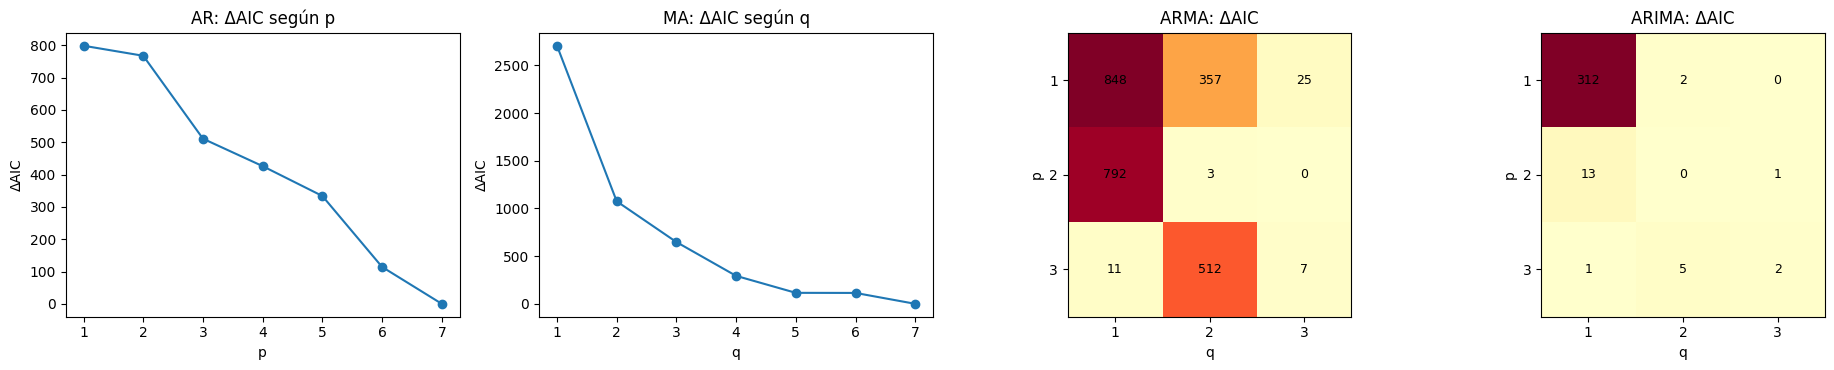

In [22]:
import time
import warnings
from itertools import product

from statsmodels.tsa.arima.model import ARIMA

# Serie de ajuste: train de la serie general, sin los últimos días de diciembre de 2024 (no tienen dato)
y_general = train["general"].dropna().to_numpy()

# Órdenes (p, d, q) que se prueban en cada modelo
rejillas = {
    "AR":    [(p, 0, 0) for p in range(1, 8)],
    "MA":    [(0, 0, q) for q in range(1, 8)],
    "ARMA":  [(p, 0, q) for p, q in product(range(1, 4), range(1, 4))],
    "ARIMA": [(p, 1, q) for p, q in product(range(1, 4), range(1, 4))],
}


def ajustar(y, orden):
    """Ajusta un ARIMA(orden) por máxima verosimilitud, sin mostrar los avisos de convergencia."""
    with warnings.catch_warnings():
        warnings.simplefilter("ignore")
        return ARIMA(y, order=orden).fit()


def aic_de(y, orden):
    """AIC del modelo (NaN si el ajuste falla numéricamente)."""
    try:
        return ajustar(y, orden).aic
    except (ValueError, np.linalg.LinAlgError):
        return np.nan


# AIC de cada orden y orden elegido (el de menor AIC) para cada modelo
aic = {modelo: {o: aic_de(y_general, o) for o in candidatos} for modelo, candidatos in rejillas.items()}
ordenes = {modelo: tuple(int(x) for x in pd.Series(valores).idxmin()) for modelo, valores in aic.items()}

print("Orden elegido por AIC (serie general, train):")
for modelo, o in ordenes.items():
    print(f"  {modelo:<5} -> ARIMA{o}   AIC = {aic[modelo][o]:,.0f}")


def a_matriz(valores):
    """Pasa {(p, d, q): AIC} a una tabla con p en las filas y q en las columnas."""
    m = pd.DataFrame(index=sorted({o[0] for o in valores}), columns=sorted({o[2] for o in valores}), dtype=float)
    for (p, _, q), v in valores.items():
        m.loc[p, q] = v
    return m


fig, axes = plt.subplots(1, 4, figsize=(19, 3.8))

# AR y MA: un solo parámetro (p en AR, q en MA)
for ax, modelo, parametro in zip(axes[:2], ["AR", "MA"], ["p", "q"]):
    s = pd.Series({o[0] + o[2]: v for o, v in aic[modelo].items()})
    (s - s.min()).plot(marker="o", ax=ax)
    ax.set_title(f"{modelo}: ΔAIC según {parametro}")
    ax.set_xlabel(parametro)
    ax.set_ylabel("ΔAIC")

# ARMA y ARIMA: mapa de calor con p en las filas y q en las columnas
for ax, modelo in zip(axes[2:], ["ARMA", "ARIMA"]):
    m = a_matriz(aic[modelo])
    m = m - m.min().min()
    ax.imshow(m.values, cmap="YlOrRd")
    ax.set_xticks(range(m.shape[1]), m.columns)
    ax.set_yticks(range(m.shape[0]), m.index)
    for i in range(m.shape[0]):
        for j in range(m.shape[1]):
            ax.text(j, i, f"{m.iloc[i, j]:.0f}", ha="center", va="center", fontsize=9)
    ax.set_title(f"{modelo}: ΔAIC")
    ax.set_xlabel("q")
    ax.set_ylabel("p")

plt.tight_layout()
plt.show()

#### Ajuste de los modelos

Con los órdenes elegidos, se ajusta cada modelo sobre el train de cada serie (12 modelos en total). La columna «nivel a largo plazo» es el valor hacia el que tiende la predicción cuando el horizonte es muy lejano (solo tiene sentido en los modelos sin diferenciar) y se compara con la media de todo el train y con la del último año.

In [23]:
# Ajuste de los 4 modelos (con el orden elegido) sobre el train de cada una de las 3 series
modelos = {}
for s in NOMBRES_SERIES:
    y = train[s].dropna().to_numpy()
    for modelo, orden in ordenes.items():
        modelos[(s, modelo)] = ajustar(y, orden)

# Resumen de los 12 modelos ajustados
filas = []
for (s, modelo), res in modelos.items():
    orden = ordenes[modelo]
    filas.append({
        "serie": s,
        "modelo": modelo,
        "orden": f"ARIMA{orden}",
        "AIC": res.aic,
        "nivel a largo plazo": res.forecast(365)[-1] if orden[1] == 0 else np.nan,
        "media del train": train[s].mean(),
        "media último año del train": train[s].dropna().iloc[-365:].mean(),
    })
display(pd.DataFrame(filas).round(1))

,serie,modelo,orden,AIC,nivel a largo plazo,media del train,media último año del train
0,general,AR,"ARIMA(7, 0, 0)",67436.0,41.4,41.4,23.6
1,general,MA,"ARIMA(0, 0, 7)",68287.8,41.4,41.4,23.6
2,general,ARMA,"ARIMA(2, 0, 3)",67334.4,40.8,41.4,23.6
3,general,ARIMA,"ARIMA(1, 1, 3)",67346.7,NaN,41.4,23.6
4,verde,AR,"ARIMA(7, 0, 0)",64813.5,25.2,25.2,16.0
5,verde,MA,"ARIMA(0, 0, 7)",65477.8,25.2,25.2,16.0
6,verde,ARMA,"ARIMA(2, 0, 3)",64676.2,25.2,25.2,16.0
7,verde,ARIMA,"ARIMA(1, 1, 3)",64679.0,NaN,25.2,16.0
8,urbana,AR,"ARIMA(7, 0, 0)",68948.6,47.3,47.3,26.4
9,urbana,MA,"ARIMA(0, 0, 7)",69795.2,47.3,47.3,26.4


**Qué es el AIC y cómo lo usamos**

El AIC es una nota que le ponemos a cada modelo: premia que se ajuste bien a los datos y castiga que sea más complicado de lo necesario (más parámetros). Cuanto más bajo, mejor. El castigo hace falta porque, si solo miráramos el ajuste, ganaría siempre el modelo con más parámetros, aunque solo estuviera copiando el ruido.

El valor del AIC por sí solo no dice nada (aquí son números de unos 67.000). Lo que importa es la diferencia entre modelos, y por eso las gráficas muestran el ΔAIC respecto al mejor: un 0 es el orden elegido. Además, solo se pueden comparar modelos ajustados con los mismos datos. Por eso comparamos órdenes dentro de cada modelo, y no ARMA con ARIMA, que trabaja con la serie diferenciada.

**Qué vemos**

- **AR y MA:** el AIC baja en cada paso y el mejor es el último que probamos (p = 7 y q = 7). No hemos encontrado un punto donde se estabilice, así que con más retardos podría seguir mejorando. Como estos modelos son solo una referencia, no ampliamos la búsqueda.
- **ARMA:** gana el (2, 3). Los órdenes (2, 2) y (3, 3) quedan a solo 3 y 7 unidades, es decir, casi empatan. Con p = 1 y q = 1 el ajuste es mucho peor (848 unidades).
- **ARIMA:** gana el (1, 1, 3), pero varios órdenes quedan a 0-2 unidades, así que en la práctica hay un empate. Nos quedamos con el de menor AIC por criterio.
- **Entre los modelos sin diferenciar** (mismos datos, comparables), el que mejor se ajusta al train es ARMA (67.334), seguido de AR (67.436) y MA (68.288). Un mejor ajuste en train no garantiza mejores predicciones en test: eso se comprueba más adelante, en los resultados.

#### Predicción sobre el test

Para cada día del test se aplica el modelo ya ajustado (sin reentrenar) a los últimos 365 días conocidos y se predice hasta 30 días vista, de donde se sacan los horizontes de 1 día, 1 semana y 1 mes. Este paso puede tardar unos minutos.

In [24]:
VENTANA = 365                       # días de historia que ve el modelo en cada predicción
H_MAX = max(HORIZONTES.values())    # se predice hasta 30 días y de ahí se sacan los tres horizontes


def predicciones_rolling(res, serie):
    """
    Para cada fecha de origen del test, aplica el modelo ya ajustado (parámetros fijos, sin reentrenar)
    a los últimos VENTANA días conocidos y predice los siguientes H_MAX días.
    Devuelve una tabla con una fila por origen y una columna por horizonte (1..H_MAX).
    """
    valores = serie.to_numpy()
    posiciones = np.flatnonzero(serie.index > FIN_TRAIN)            # orígenes: todos los días del test
    salida = np.full((len(posiciones), H_MAX), np.nan)
    for i, pos in enumerate(posiciones):
        ventana = valores[max(0, pos - VENTANA + 1): pos + 1]       # solo datos hasta el día de origen
        with warnings.catch_warnings():
            warnings.simplefilter("ignore")
            salida[i] = res.apply(ventana).forecast(H_MAX)
    return pd.DataFrame(salida, index=serie.index[posiciones], columns=range(1, H_MAX + 1))


# Una tabla por serie y horizonte: los baselines de la sección 7 + una columna por modelo clásico
tablas = {}
for s in NOMBRES_SERIES:
    inicio = time.time()
    pred = {modelo: predicciones_rolling(modelos[(s, modelo)], series_imputada[s]) for modelo in ordenes}
    for etiqueta, h in HORIZONTES.items():
        tabla = tablas_base[(s, etiqueta)].copy()
        for modelo in ordenes:
            tabla[modelo] = pred[modelo][h]          # se alinea por fecha de origen
        tablas[(s, etiqueta)] = tabla
    print(f"{s}: listo ({time.time() - inicio:.0f} s)")

general: listo (49 s)
verde: listo (48 s)
urbana: listo (49 s)


#### Resultados en test

MAE y RMSE de los modelos clásicos junto a los baselines, calculados sobre las mismas fechas.

Fechas de origen evaluadas por horizonte: {'1 día': 601, '1 semana': 601, '1 mes': 573}

MAE en test (µg/m³)


RMSE en test (µg/m³)


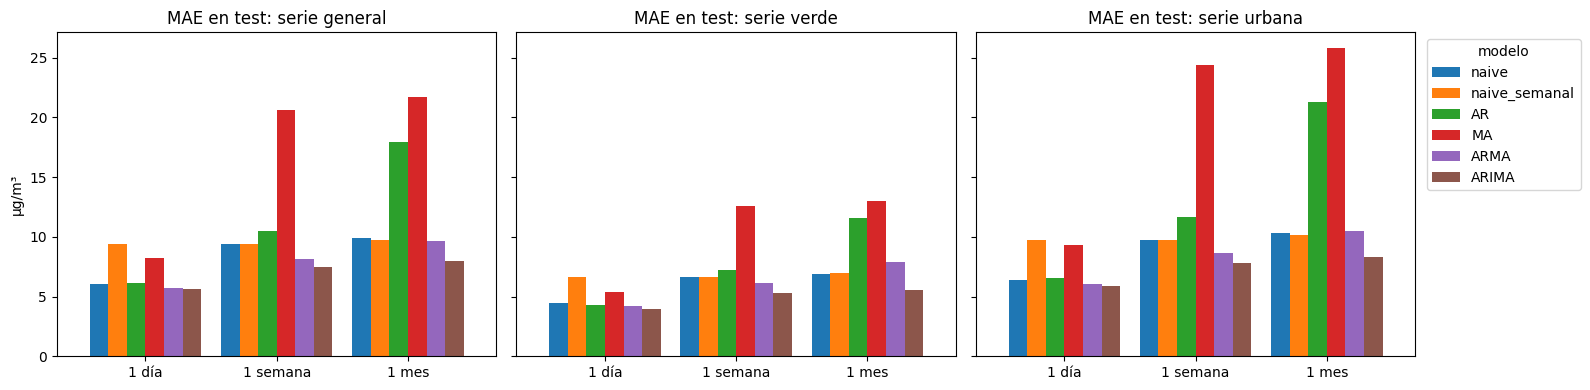

In [25]:
MODELOS = ["naive", "naive_semanal", "AR", "MA", "ARMA", "ARIMA"]
metricas = metricas_test(tablas, MODELOS)
mae = a_formato_ancho(metricas, "MAE", MODELOS)
rmse = a_formato_ancho(metricas, "RMSE", MODELOS)

n_fechas = metricas.groupby("horizonte")["n"].first().reindex(list(HORIZONTES)).to_dict()
print(f"Fechas de origen evaluadas por horizonte: {n_fechas}\n")

# Tablas (en verde, el menor error de cada fila)
print("MAE en test (µg/m³)")
display(mae.style.format("{:.2f}").highlight_min(axis=1, color="#b7e4c7"))
print("RMSE en test (µg/m³)")
display(rmse.style.format("{:.2f}").highlight_min(axis=1, color="#b7e4c7"))

# MAE por serie y horizonte
fig, axes = plt.subplots(1, 3, figsize=(16, 4), sharey=True)
for ax, s in zip(axes, NOMBRES_SERIES):
    mae.loc[s].plot(kind="bar", ax=ax, width=0.85, legend=(ax is axes[-1]))
    ax.set_title(f"MAE en test: serie {s}")
    ax.set_xlabel("")
    ax.tick_params(axis="x", rotation=0)
axes[0].set_ylabel("µg/m³")
axes[-1].legend(title="modelo", loc="upper left", bbox_to_anchor=(1.01, 1))
plt.tight_layout()
plt.show()

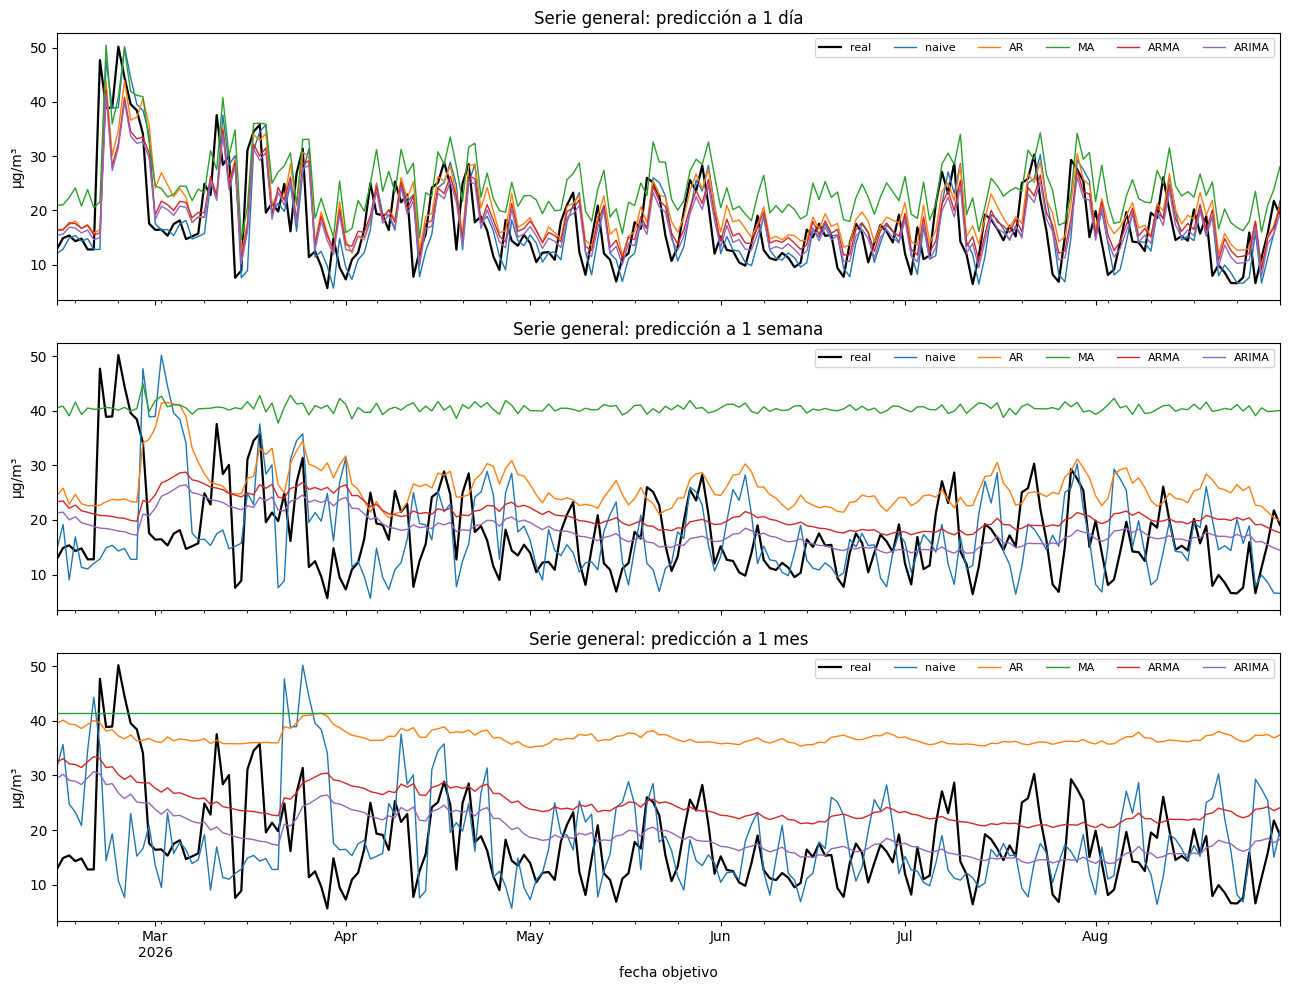

In [26]:
# Predicciones frente al valor real: serie general, últimos 200 días del test (una gráfica por horizonte)
fig, axes = plt.subplots(3, 1, figsize=(13, 10), sharex=True)
for ax, (etiqueta, h) in zip(axes, HORIZONTES.items()):
    t = tablas[("general", etiqueta)][["objetivo", "naive", "AR", "MA", "ARMA", "ARIMA"]].dropna()
    t.index = t.index + pd.Timedelta(days=h)          # se dibuja en la fecha objetivo, no en la de origen
    t = t.iloc[-200:]
    t["objetivo"].plot(ax=ax, color="black", linewidth=1.6, label="real")
    t.drop(columns="objetivo").plot(ax=ax, linewidth=1)
    ax.set_title(f"Serie general: predicción a {etiqueta}")
    ax.set_ylabel("µg/m³")
    ax.legend(ncol=6, fontsize=8, loc="upper right")
axes[-1].set_xlabel("fecha objetivo")
plt.tight_layout()
plt.show()

**Análisis de los resultados**

Comparamos cada modelo con el naive (predecir que mañana será igual que hoy). A 1 semana los dos baselines coinciden: el mismo día de la semana anterior al que queremos predecir es justo hoy.

- **ARIMA es el mejor en todo.** Gana en las tres series, en los tres horizontes y tanto en MAE como en RMSE. A 1 día la mejora sobre el naive es pequeña (en la serie general, de 6,09 a 5,60 de MAE, un 8 %), pero a 1 semana y a 1 mes ronda el 20 % (por ejemplo, de 9,86 a 7,94 a 1 mes en la serie general).
- **ARMA queda a medio camino.** Supera al naive a 1 día y a 1 semana. A 1 mes apenas lo iguala en la serie general (9,65 frente a 9,86) y lo empeora en las series verde y urbana.
- **AR y MA no mejoran a los baselines.** AR a 1 día queda casi igual que el naive, y a 1 semana y a 1 mes es claramente peor: su error sube con el horizonte (de 6,14 a 17,96 en la serie general). MA es el peor en todos los casos y a 1 mes predice una línea plana.
- **Por qué pasa esto.** En la tabla del ajuste, los modelos sin diferenciar tienden a largo plazo a unos 41 µg/m³, la media de todo el train. Pero el último año del train ronda los 24, y en el test el NO2 sigue por debajo de la media histórica. AR, MA y ARMA acaban tirando de las predicciones hacia un nivel que ya no es el actual, y cuanto más lejos predicen, más se nota. ARIMA, al diferenciar, no tiene una media a la que volver y parte del nivel reciente. Por eso conviene leer su ventaja con cuidado: en parte se debe a que se adapta al nivel bajo de 2025-26, no a que capte mejor el día a día.
- **Lo que ninguno recoge.** A 1 semana y a 1 mes, las predicciones son líneas suaves y la serie real oscila mucho de un día a otro, por el ciclo semanal. Ninguno de estos cuatro modelos tiene estacionalidad. Es lo que probamos en 8.1.2 con SARIMA y SARIMAX.

De momento nos quedamos con ARIMA como referencia clásica a batir.

### 8.1.2 SARIMA y SARIMAX

La segunda tanda añade a ARIMA lo que le faltaba: la estacionalidad. En el análisis exploratorio vimos un patrón semanal claro (de lunes a viernes el NO2 ronda los 40-43 µg/m³, el sábado unos 36 y el domingo unos 32) y las gráficas de 8.1.1 mostraban que ningún modelo lo recogía.

**Qué hace cada modelo**

- **SARIMA:** es un ARIMA con una parte estacional. Además de mirar los valores y errores de los días anteriores, mira los de hace 7, 14, 21... días, es decir, el mismo día de la semana en semanas pasadas. Se escribe SARIMA(p, d, q)(P, D, Q): la primera parte es el ARIMA de siempre y la segunda es lo mismo pero saltando de 7 en 7 días.
- **SARIMAX:** es un SARIMA al que se le añaden variables externas (la X). Aquí solo usamos el calendario (día de la semana y festivo), porque es lo único que conocemos con certeza para cualquier fecha futura. El día de la semana ya lo recoge en parte la estacionalidad de SARIMA, así que lo que más puede aportar el calendario son los festivos. Se valorarán otras variables exógenes diferentes en etapas posteriores del proyecto.

**Cómo los implementamos**

- Seguimos usando la clase `ARIMA` de `statsmodels`, que admite una parte estacional (`seasonal_order`) y variables externas (`exog`). SARIMA es ARIMA(p, d, q) con estacionalidad de periodo 7, y SARIMAX es lo mismo con el calendario como `exog`.
- Usamos periodo 7 (semanal). No probamos el periodo anual (365): con tantos días por ciclo, este tipo de modelo se vuelve inviable en tiempo y memoria. Por eso el ciclo anual, que es la estacionalidad más fuerte de la serie, sigue sin estar modelado de forma explícita aquí. Es una limitación que dejamos anotada y que sí abordan los modelos de 8.2 y 8.3.
- Partimos del orden (p, d, q) que ya salió mejor en ARIMA, y buscamos con el AIC solo el orden estacional (P, Q). Comparar por AIC solo tiene sentido con la misma diferenciación, así que *d* y *D* los fijamos nosotros y no los elige el AIC.
- El resto del procedimiento es igual que en 8.1.1: ajuste sobre el train de cada serie, parámetros congelados, ventana de 365 días, horizontes de 1 día, 1 semana y 1 mes, y evaluación con MAE y RMSE sobre las mismas fechas.

#### Elección del orden estacional

Para SARIMA fijamos la parte no estacional en el mejor ARIMA de 8.1.1, ARIMA(1, 1, 3), y probamos varios órdenes estacionales (P, Q) con periodo 7: de 0 a 2 valores estacionales pasados (P) y de 0 a 2 errores estacionales pasados (Q). El orden (0, 0) es el ARIMA de antes, así que sirve de punto de partida para ver cuánto mejora el ajuste al añadir estacionalidad. Se elige el de menor AIC sobre el train de la serie general, y se usa el mismo para las tres series, igual que en 8.1.1. El mapa de calor muestra la diferencia de AIC respecto al mejor (0 = el elegido).

Ajustados 9 modelos en 219 s

Orden elegido por AIC (serie general, train): SARIMA(1, 1, 3)(1, 0, 1, 7)   AIC = 66,343
Referencia, ARIMA(1, 1, 3) sin parte estacional:   AIC = 67,347


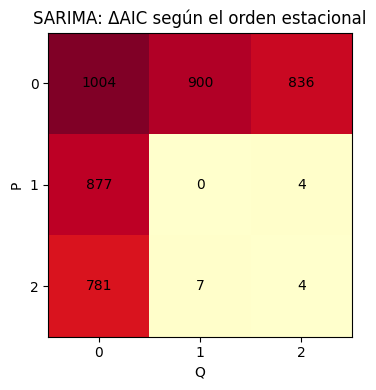

In [27]:
# Orden estacional de SARIMA: parte no estacional fija en el mejor ARIMA de 8.1.1, periodo semanal
S = 7
orden_base = ordenes["ARIMA"]                                   # (1, 1, 3)
candidatos_est = list(product(range(0, 3), range(0, 3)))        # (P, Q) entre 0 y 2 (D = 0)


def ajustar_sarima(y, orden, orden_est, exog=None):
    """Ajusta un SARIMA(orden)(P, 0, Q)_S por máxima verosimilitud, sin mostrar los avisos de convergencia."""
    P, Q = orden_est
    with warnings.catch_warnings():
        warnings.simplefilter("ignore")
        return ARIMA(y, exog=exog, order=orden, seasonal_order=(P, 0, Q, S)).fit()


def aic_sarima(y, orden, orden_est):
    """AIC del modelo (NaN si el ajuste falla numéricamente)."""
    try:
        return ajustar_sarima(y, orden, orden_est).aic
    except (ValueError, np.linalg.LinAlgError):
        return np.nan


# AIC de cada orden estacional sobre el train de la serie general (mismos datos que en 8.1.1)
inicio = time.time()
aic_est = {oe: aic_sarima(y_general, orden_base, oe) for oe in candidatos_est}
orden_est = min(aic_est, key=lambda k: aic_est[k])              # el de menor AIC
print(f"Ajustados {len(candidatos_est)} modelos en {time.time() - inicio:.0f} s\n")

print(f"Orden elegido por AIC (serie general, train): SARIMA{orden_base}{(orden_est[0], 0, orden_est[1], S)}"
      f"   AIC = {aic_est[orden_est]:,.0f}")
print(f"Referencia, ARIMA{orden_base} sin parte estacional:   AIC = {aic_est[(0, 0)]:,.0f}")

# Mapa de calor de ΔAIC: P en las filas, Q en las columnas
m = pd.DataFrame(index=range(3), columns=range(3), dtype=float)
for (P, Q), v in aic_est.items():
    m.loc[P, Q] = v
m = m - m.min().min()

fig, ax = plt.subplots(figsize=(5, 4))
ax.imshow(m.values, cmap="YlOrRd")
ax.set_xticks(range(3), m.columns)
ax.set_yticks(range(3), m.index)
for i in range(3):
    for j in range(3):
        ax.text(j, i, f"{m.iloc[i, j]:.0f}", ha="center", va="center", fontsize=10)
ax.set_title("SARIMA: ΔAIC según el orden estacional")
ax.set_xlabel("Q")
ax.set_ylabel("P")
plt.tight_layout()
plt.show()

**Qué vemos**

- **Añadir la parte estacional mejora mucho el ajuste.** El mejor SARIMA baja el AIC de 67.347 (el ARIMA sin estacionalidad) a 66.343, unas 1.000 unidades menos. En el mapa, la esquina (0, 0) es ese ARIMA y es la peor de todas. Esto confirma lo que vimos en el EDA: el ciclo semanal está ahí y merece la pena modelarlo.
- **Lo importante es el término autorregresivo estacional (P).** Con P = 0 el ΔAIC se queda entre 836 y 1.004 en las tres casillas, aunque subamos Q. Con P = 1 o 2 y Q ≥ 1 baja a unas pocas unidades.
- **Gana el SARIMA(1, 1, 3)(1, 0, 1)₇, pero hay un empate.** Los órdenes (1, 2), (2, 2) y (2, 1) quedan a solo 4-7 unidades, es decir, casi igual de buenos. Nos quedamos con el (1, 1) por dar el menor AIC y por ser el más sencillo de los cuatro. El ganador no está en el borde de la rejilla, así que ampliar la búsqueda más allá de 2 no parece necesario.

#### Ajuste de SARIMA

Con el orden elegido, se ajusta SARIMA sobre el train de cada serie (3 modelos). La tabla compara su AIC con el del ARIMA de 8.1.1 en la misma serie: como usan los mismos datos y la misma diferenciación, los dos AIC son comparables.

In [28]:
# Ajuste de SARIMA (con el orden elegido) sobre el train de cada una de las 3 series
inicio = time.time()
modelos_sarima = {}
for s in NOMBRES_SERIES:
    y = train[s].dropna().to_numpy()
    modelos_sarima[s] = ajustar_sarima(y, orden_base, orden_est)
print(f"Ajustados {len(modelos_sarima)} modelos en {time.time() - inicio:.0f} s")

# Resumen: AIC de SARIMA frente al del ARIMA de 8.1.1 (mismos datos y misma diferenciación)
filas = []
for s, res in modelos_sarima.items():
    aic_arima = modelos[(s, "ARIMA")].aic
    filas.append({
        "serie": s,
        "orden": f"SARIMA{orden_base}{(orden_est[0], 0, orden_est[1], S)}",
        "AIC SARIMA": res.aic,
        "AIC ARIMA (8.1.1)": aic_arima,
        "diferencia": res.aic - aic_arima,
    })
display(pd.DataFrame(filas).round(1))

Ajustados 3 modelos en 93 s


,serie,orden,AIC SARIMA,AIC ARIMA (8.1.1),diferencia
0,general,"SARIMA(1, 1, 3)(1, 0, 1, 7)",66342.5,67346.7,-1004.2
1,verde,"SARIMA(1, 1, 3)(1, 0, 1, 7)",64190.4,64679.0,-488.7
2,urbana,"SARIMA(1, 1, 3)(1, 0, 1, 7)",67785.1,68878.4,-1093.4


- **SARIMA mejora el ajuste en las tres series.** El AIC baja en todas respecto al ARIMA de 8.1.1: unas 1.000 unidades en la serie general (de 67.347 a 66.343), unas 490 en la verde y unas 1.090 en la urbana. Las diferencias son enormes frente a los empates de pocas unidades que veíamos al elegir órdenes, así que no dependen del orden concreto que se haya elegido.
- **El orden elegido con la serie general sirve para las tres.** Aunque solo lo buscamos en la general, la parte estacional mejora también el ajuste de la verde y la urbana. En la verde la mejora es aproximadamente la mitad que en las otras dos.

#### Predicción de SARIMA sobre el test

Igual que en 8.1.1: para cada día del test se aplica el modelo ya ajustado (sin reentrenar) a los últimos 365 días conocidos y se predice hasta 30 días vista, de donde se sacan los horizontes de 1 día, 1 semana y 1 mes. Usamos la misma función y las mismas ventanas, así que las predicciones de SARIMA se pueden comparar directamente con las de los otros modelos. Este paso es más lento que el de 8.1.1, porque SARIMA es un modelo más pesado.

In [29]:
# Predicciones de SARIMA sobre el test (misma función y mismas ventanas que en 8.1.1)
for s in NOMBRES_SERIES:
    inicio = time.time()
    pred = predicciones_rolling(modelos_sarima[s], series_imputada[s])
    for etiqueta, h in HORIZONTES.items():
        tablas[(s, etiqueta)]["SARIMA"] = pred[h]     # se alinea por fecha de origen
    print(f"{s}: listo ({time.time() - inicio:.0f} s)")

general: listo (15 s)
verde: listo (15 s)
urbana: listo (15 s)


#### Calendario como variable externa

SARIMAX necesita las variables externas para cada día, y para predecir hacia el futuro tienen que conocerse de antemano. El calendario cumple esto: sabemos qué día de la semana y qué festivos habrá en cualquier fecha futura. Construimos siete columnas: una por cada día de la semana salvo el lunes, que queda como referencia, y una que marca los festivos. Los festivos son los nacionales y los de la Comunidad de Madrid, más los dos propios de la ciudad (San Isidro y La Almudena). El calendario se extiende 30 días más allá del último dato, para poder predecir también los últimos días del test.

In [30]:
%pip install -q holidays
import datetime as dt
import holidays
from dateutil.easter import easter

# Festivos de Madrid. El paquete cubre desde 2008 (nacionales + Comunidad de Madrid)
festivos = holidays.Spain(subdiv="MD", years=range(2008, 2028))

# Antes de 2008 el paquete no da festivos: se ponen con reglas sencillas (fechas fijas + Semana Santa)
FIJOS = [(1, 1), (1, 6), (5, 1), (5, 2), (8, 15), (10, 12), (11, 1), (12, 6), (12, 8), (12, 25)]
for anio in range(2001, 2008):
    for mes, dia in FIJOS:
        festivos[dt.date(anio, mes, dia)] = "Festivo"
    festivos[easter(anio) - dt.timedelta(days=3)] = "Jueves Santo"
    festivos[easter(anio) - dt.timedelta(days=2)] = "Viernes Santo"

# Los dos festivos locales de la ciudad de Madrid, todos los años
for anio in range(2001, 2028):
    festivos[dt.date(anio, 5, 15)] = "San Isidro"
    almudena = dt.date(anio, 11, 9)
    if almudena.weekday() == 6:                        # si cae en domingo, se pasa al lunes
        almudena += dt.timedelta(days=1)
    festivos[almudena] = "La Almudena"

# Calendario diario, con 30 días de margen más allá del último dato (para los últimos orígenes del test)
fechas = pd.date_range(series_imputada.index.min(), FIN_DATOS + pd.Timedelta(days=H_MAX))
calendario = pd.get_dummies(pd.Series(fechas.dayofweek, index=fechas), prefix="dia", drop_first=True).astype(float)
calendario["festivo"] = [float(f.date() in festivos) for f in fechas]

# Comprobación: festivos de 2025 y nº de festivos por año
print("Festivos de 2025:")
for f, nombre in sorted(festivos.items()):
    if f.year == 2025:
        print(f"  {f}  {nombre}")
print("\nNº de festivos por año:", calendario.groupby(calendario.index.year)["festivo"].sum().astype(int).to_dict())
print(f"\nCalendario: {calendario.shape[0]} días x {calendario.shape[1]} columnas ({', '.join(calendario.columns)})")

Festivos de 2025:
  2025-01-01  New Year's Day
  2025-01-06  Epiphany
  2025-04-17  Maundy Thursday
  2025-04-18  Good Friday
  2025-05-01  Labor Day
  2025-05-02  Madrid Day
  2025-05-15  San Isidro
  2025-07-25  Saint James' Day
  2025-08-15  Assumption Day
  2025-11-01  All Saints' Day
  2025-11-10  La Almudena
  2025-12-06  Constitution Day
  2025-12-08  Immaculate Conception
  2025-12-25  Christmas Day

Nº de festivos por año: {2001: 14, 2002: 14, 2003: 14, 2004: 14, 2005: 14, 2006: 14, 2007: 14, 2008: 14, 2009: 14, 2010: 14, 2011: 14, 2012: 14, 2013: 14, 2014: 14, 2015: 13, 2016: 14, 2017: 14, 2018: 14, 2019: 14, 2020: 14, 2021: 14, 2022: 14, 2023: 14, 2024: 14, 2025: 14, 2026: 8}

Calendario: 9404 días x 7 columnas (dia_1, dia_2, dia_3, dia_4, dia_5, dia_6, festivo)


#### Ajuste de SARIMAX

SARIMAX es el SARIMA de antes, con el mismo orden, más las siete columnas del calendario. Se ajusta sobre el train de cada serie (3 modelos). La tabla compara su AIC con el de SARIMA en la misma serie: usan los mismos datos y la misma diferenciación, y el AIC ya castiga las siete variables extra, así que son comparables. Añadimos el efecto estimado de los festivos, que indica cuántos µg/m³ cambia el NO2 un día festivo respecto a uno laborable, con el mismo día de la semana.

In [31]:
# Ajuste de SARIMAX (mismo orden que SARIMA + calendario) sobre el train de cada una de las 3 series
inicio = time.time()
modelos_sarimax = {}
for s in NOMBRES_SERIES:
    y = train[s].dropna()                                    # sin los últimos días de diciembre de 2024 (no tienen dato)
    exog = calendario.loc[y.index].to_numpy()                # el calendario, alineado con las mismas fechas
    modelos_sarimax[s] = ajustar_sarima(y.to_numpy(), orden_base, orden_est, exog=exog)
print(f"Ajustados {len(modelos_sarimax)} modelos en {time.time() - inicio:.0f} s")

# Resumen: AIC de SARIMAX frente al de SARIMA, y efecto estimado de los festivos
i_festivo = list(calendario.columns).index("festivo")       # los coeficientes de las exógenas van los primeros
filas = []
for s, res in modelos_sarimax.items():
    aic_sarima_s = modelos_sarima[s].aic
    filas.append({
        "serie": s,
        "AIC SARIMAX": res.aic,
        "AIC SARIMA": aic_sarima_s,
        "diferencia": res.aic - aic_sarima_s,
        "efecto festivo (µg/m³)": res.params[i_festivo],
        "p-valor festivo": res.pvalues[i_festivo],
    })
display(pd.DataFrame(filas).round(3))

Ajustados 3 modelos en 223 s


,serie,AIC SARIMAX,AIC SARIMA,diferencia,efecto festivo (µg/m³),p-valor festivo
0,general,66070.562,66342.546,-271.984,-7.860,0.0
1,verde,64038.101,64190.361,-152.260,-5.468,0.0
2,urbana,67474.714,67785.055,-310.341,-9.582,0.0


- **Añadir el calendario mejora el ajuste en las tres series.** El AIC baja unas 270 unidades en la serie general, unas 150 en la verde y unas 310 en la urbana respecto a SARIMA. Y esto es después de que el AIC penalice las siete variables nuevas.
- **Los festivos bajan el NO2 en las tres series.** Un día festivo, con el mismo día de la semana, el NO2 es unos 7,9 µg/m³ menor en la serie general, 5,5 en la verde y 9,6 en la urbana. El p-valor es tan pequeño que la tabla lo redondea a 0. El orden entre series (más efecto en la urbana, menos en la verde) tiene sentido: las estaciones de tráfico son las que más notan que hay menos coches. Y la magnitud es parecida a la caída del domingo que vimos en el EDA.


#### Predicción de SARIMAX sobre el test

El procedimiento es el mismo que con SARIMA: para cada día del test se aplica el modelo ya ajustado (sin reentrenar) a los últimos 365 días conocidos y se predice hasta 30 días vista. La diferencia es que ahora, en cada predicción, el modelo recibe también el calendario de esos 365 días y el de los 30 días futuros. Es información que se conoce de antemano, así que no hay fuga de datos del futuro.

In [32]:
def predicciones_rolling_x(res, serie, cal):
    """
    Igual que predicciones_rolling, pero pasando también el calendario: el de la ventana conocida
    y el de los H_MAX días siguientes (que se sabe de antemano).
    """
    assert cal.index[0] == serie.index[0], "el calendario debe empezar el mismo día que la serie"
    valores = serie.to_numpy()
    cal = cal.to_numpy()
    posiciones = np.flatnonzero(serie.index > FIN_TRAIN)            # orígenes: todos los días del test
    salida = np.full((len(posiciones), H_MAX), np.nan)
    for i, pos in enumerate(posiciones):
        ini = max(0, pos - VENTANA + 1)
        ventana = valores[ini: pos + 1]                             # solo datos hasta el día de origen
        exog_ventana = cal[ini: pos + 1]                            # calendario de esa ventana
        exog_futuro = cal[pos + 1: pos + 1 + H_MAX]                 # calendario de los días a predecir
        with warnings.catch_warnings():
            warnings.simplefilter("ignore")
            salida[i] = res.apply(ventana, exog=exog_ventana).forecast(H_MAX, exog=exog_futuro)
    return pd.DataFrame(salida, index=serie.index[posiciones], columns=range(1, H_MAX + 1))


# Predicciones de SARIMAX sobre el test: se añade una columna a las tablas que ya tenemos
for s in NOMBRES_SERIES:
    inicio = time.time()
    pred = predicciones_rolling_x(modelos_sarimax[s], series_imputada[s], calendario)
    for etiqueta, h in HORIZONTES.items():
        tablas[(s, etiqueta)]["SARIMAX"] = pred[h]    # se alinea por fecha de origen
    print(f"{s}: listo ({time.time() - inicio:.0f} s)")

general: listo (48 s)
verde: listo (20 s)
urbana: listo (21 s)


#### Resultados de los seis modelos clásicos en test

MAE y RMSE de los seis modelos clásicos junto a los baselines, calculados sobre las mismas fechas. Los cuatro primeros modelos son los de 8.1.1, y SARIMA y SARIMAX se añaden a la comparación.

Fechas de origen evaluadas por horizonte: {'1 día': 601, '1 semana': 601, '1 mes': 573}

MAE en test (µg/m³)


RMSE en test (µg/m³)


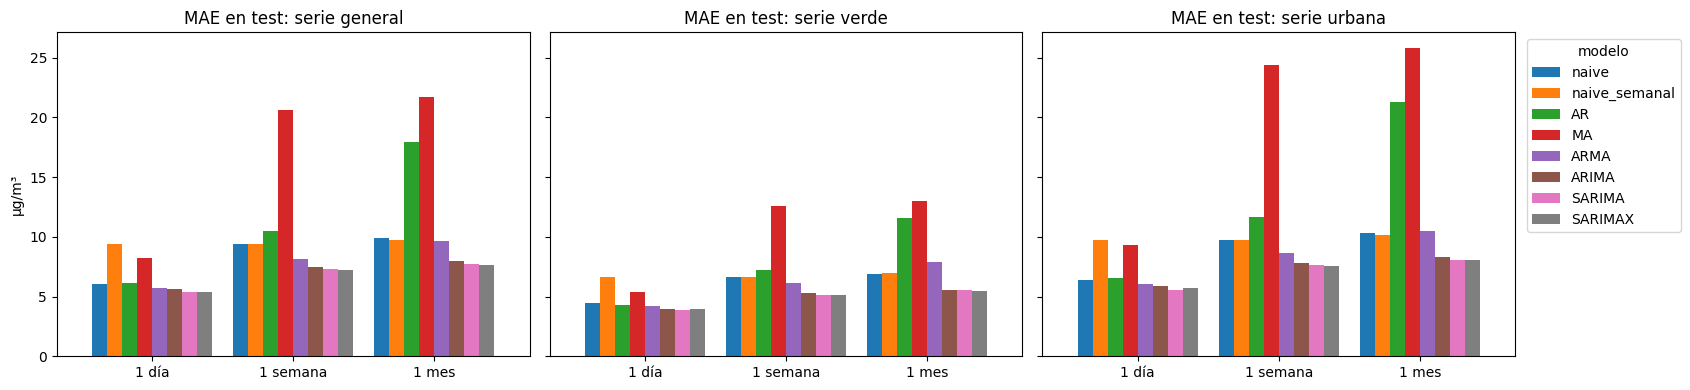

In [33]:
MODELOS_TODOS = ["naive", "naive_semanal", "AR", "MA", "ARMA", "ARIMA", "SARIMA", "SARIMAX"]
metricas_todos = metricas_test(tablas, MODELOS_TODOS)
mae_todos = a_formato_ancho(metricas_todos, "MAE", MODELOS_TODOS)
rmse_todos = a_formato_ancho(metricas_todos, "RMSE", MODELOS_TODOS)

n_fechas = metricas_todos.groupby("horizonte")["n"].first().reindex(list(HORIZONTES)).to_dict()
print(f"Fechas de origen evaluadas por horizonte: {n_fechas}\n")

# Tablas (en verde, el menor error de cada fila)
print("MAE en test (µg/m³)")
display(mae_todos.style.format("{:.2f}").highlight_min(axis=1, color="#b7e4c7"))
print("RMSE en test (µg/m³)")
display(rmse_todos.style.format("{:.2f}").highlight_min(axis=1, color="#b7e4c7"))

# MAE por serie y horizonte
fig, axes = plt.subplots(1, 3, figsize=(17, 4), sharey=True)
for ax, s in zip(axes, NOMBRES_SERIES):
    mae_todos.loc[s].plot(kind="bar", ax=ax, width=0.85, legend=(ax is axes[-1]))
    ax.set_title(f"MAE en test: serie {s}")
    ax.set_xlabel("")
    ax.tick_params(axis="x", rotation=0)
axes[0].set_ylabel("µg/m³")
axes[-1].legend(title="modelo", loc="upper left", bbox_to_anchor=(1.01, 1))
plt.tight_layout()
plt.show()

**Análisis de los resultados**

- **SARIMA mejora a ARIMA en todos los casos.** Baja el error en las tres series y en los tres horizontes, tanto en MAE como en RMSE. La mejora es real pero pequeña: entre un 2 % y un 5 % de MAE (por ejemplo, en la serie general, de 5,60 a 5,34 a 1 día y de 7,94 a 7,75 a 1 mes). Es mucho menos que la mejora que veíamos en el AIC, que mide solo el ajuste sobre el train. La estacionalidad semanal ayuda, pero no cambia el panorama.
- **SARIMAX y SARIMA quedan casi empatados.** A 1 semana y a 1 mes, SARIMAX es ligeramente mejor: gana en el RMSE de las tres series y en el MAE de casi todas (la excepción es 1 semana en la serie verde, donde queda igual). A 1 día ocurre lo contrario: SARIMA es igual o algo mejor en las tres series. Las diferencias son de una o dos décimas de µg/m³, y no hemos hecho ningún test estadístico, así que no las leemos como una ventaja clara. El calendario aporta poco al error global, seguramente porque en el test hay pocos días festivos entre semana (no lo hemos comprobado).
- **Frente al naive, la mejora es clara.** El mejor modelo de cada fila reduce el MAE en torno a un 12 % a 1 día y un 21-22 % a 1 mes, en las tres series. Y en el grupo de modelos clásicos, ARIMA, SARIMA y SARIMAX son claramente mejores que AR, MA y ARMA.
- **Los tres mejores comparten el mismo punto de partida.** Los tres diferencian la serie (d = 1), así que no vuelven a la media histórica como AR, MA y ARMA. Lo comentábamos en 8.1.1: parte de su ventaja viene de adaptarse al nivel bajo de 2025-26. Lo nuevo de SARIMA y SARIMAX es la parte semanal, y su aportación adicional es la pequeña que hemos visto.
- **Lo que sigue sin recogerse.** Ningún modelo de 8.1 modela el ciclo anual, que es la estacionalidad más fuerte de la serie. Es una limitación de estos modelos, y de aquí en adelante la referencia clásica a batir es SARIMAX (o SARIMA, prácticamente igual).

### 8.2 Modelos de machine learning


#### 8.2.1 Ridge

**Ridge** es una regresión lineal con una penalización sobre el tamaño de los coeficientes (`alpha`): cuanto mayor es `alpha`, más se encogen los coeficientes y menos riesgo hay de sobreajustar.

Se usa como modelo **recursivo** (`ForecasterRecursive`): un único modelo aprende a predecir el día siguiente a partir de sus *lags* (los valores de los días anteriores). Para llegar más lejos, cada predicción se reutiliza como lag del paso siguiente, hasta 30 días. De esa predicción de 30 días se sacan los horizontes de 1 día, 1 semana y 1 mes, igual que en 8.1.

**Validación**: Los hiperparámetros se eligen con backtesting dentro del train (12 ventanas de 30 días, es decir, los 360 días finales del train: de mediados de diciembre de 2023 al 7 de diciembre de 2024), sin tocar el test.

**Con y sin diferenciación**: En 8.1 vimos que AR, MA y ARMA acababan volviendo a la media histórica (unos 41 µg/m³) mientras que el nivel reciente ronda los 24, y que ARIMA se libraba de ello al diferenciar. Un Ridge sobre lags sin diferenciar tiene el mismo riesgo, así que probamos también la versión con `differentiation=1`.

**Variantes que se comparan**

| Modelo | Qué es |
|---|---|
| `Ridge_base` | 7 lags y `alpha` por defecto, sin optimizar |
| `Ridge` | lags y `alpha` optimizados por backtesting |
| `Ridge_cal` | lo anterior + calendario (día de la semana, festivo) y ciclo anual (seno y coseno) |
| `Ridge_dif` | optimizado, con diferenciación |
| `Ridge_dif_cal` | optimizado, con diferenciación + calendario |

#### Preparación de los datos

Series de entrenamiento sin nulos (`dropna()`) y variables exógenas. Las exógenas son el calendario de 8.1.2 (que ya se conoce para cualquier fecha futura) más el ciclo anual como seno y coseno del día del año, que es la estacionalidad que los modelos clásicos no recogían.

In [34]:
%pip install -q "skforecast>=0.25,<0.26"

import time
import warnings

from sklearn.linear_model import Ridge
from sklearn.metrics import mean_absolute_error, mean_squared_error

from skforecast.recursive import ForecasterRecursive
from skforecast.model_selection import TimeSeriesFold, backtesting_forecaster, grid_search_forecaster


def rmse(y_true, y_pred):
    """RMSE, para poder usarlo también dentro de backtesting_forecaster."""
    return np.sqrt(mean_squared_error(y_true, y_pred))


# Series de entrenamiento: dropna() quita los NaN de diciembre de 2024, como en 8.1. Están todos al final del
# train, así que queda un tramo diario continuo. asfreq("D") devuelve la frecuencia diaria que necesita
# skforecast (y dejaría un NaN si hubiera algún hueco, que la comprobación siguiente detectaría).
y_train_ml = {s: train[s].dropna().asfreq("D") for s in NOMBRES_SERIES}
for s, y in y_train_ml.items():
    assert y.notna().all(), f"{s}: hay huecos dentro del train"
    print(f"{s}: {y.index[0].date()} → {y.index[-1].date()} ({len(y)} días)")

# Exógenas: calendario de 8.1.2 (día de la semana y festivo) + ciclo anual (seno y coseno del día del año)
exog_ml = calendario.copy()
dia_anio = exog_ml.index.dayofyear
exog_ml["sin_anual"] = np.sin(2 * np.pi * dia_anio / 365.25)
exog_ml["cos_anual"] = np.cos(2 * np.pi * dia_anio / 365.25)
exog_ml = exog_ml.asfreq("D")

# Exógenas alineadas con las fechas de entrenamiento de cada serie
X_train_ml = {s: exog_ml.loc[y.index].asfreq("D") for s, y in y_train_ml.items()}
print(f"\nExógenas: {list(exog_ml.columns)}")

   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 529.7/529.7 kB 11.0 MB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 442.4/442.4 kB 22.3 MB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 268.7/268.7 kB 14.9 MB/s eta 0:00:00
general: 2001-01-01 → 2024-12-07 (8742 días)
verde: 2001-01-01 → 2024-12-07 (8742 días)
urbana: 2001-01-01 → 2024-12-07 (8742 días)

Exógenas: ['dia_1', 'dia_2', 'dia_3', 'dia_4', 'dia_5', 'dia_6', 'festivo', 'sin_anual', 'cos_anual']


#### Modelo base y backtesting

El modelo base usa 7 lags (una semana) y el `alpha` por defecto de Ridge. El backtesting simula 12 predicciones históricas de 30 días sobre el final del train: el modelo se entrena con lo anterior a la primera ventana y después predice cada ventana partiendo de la historia real que había en su origen. Con `refit=False` no se reentrena entre ventanas, igual que haremos en el test. El error que se muestra es el promedio de todas las ventanas.

In [35]:
N_BACKTEST = 12      # 12 ventanas de 30 días = 360 días, casi un ciclo anual completo
LAGS_BASE = 7        # una semana de historia


def crear_cv(y, dif=None):
    return TimeSeriesFold(steps=H_MAX, initial_train_size=len(y) - N_BACKTEST * H_MAX,
                          refit=False, differentiation=dif)


modelos_ml = {}      # (serie, modelo) -> forecaster ya ajustado sobre todo el train
filas = []
for s, y in y_train_ml.items():
    f = ForecasterRecursive(estimator=Ridge(), lags=LAGS_BASE)
    metrica, _ = backtesting_forecaster(
        forecaster=f, y=y, cv=crear_cv(y),
        metric=["mean_absolute_error", rmse], verbose=False, show_progress=False,
    )
    f.fit(y=y)                                   # el backtesting deja el modelo ajustado solo con el tramo inicial
    modelos_ml[(s, "Ridge_base")] = f
    filas.append({
        "serie": s, "modelo": "Ridge_base", "lags": LAGS_BASE, "alpha": 1.0,
        "MAE backtesting": metrica["mean_absolute_error"].iloc[0],
        "RMSE backtesting": metrica["rmse"].iloc[0],
    })

print("Backtesting del modelo base (µg/m³)")
display(pd.DataFrame(filas).round(2))

Backtesting del modelo base (µg/m³)


,serie,modelo,lags,alpha,MAE backtesting,RMSE backtesting
0,general,Ridge_base,7,1.0,13.99,16.23
1,verde,Ridge_base,7,1.0,9.14,10.67
2,urbana,Ridge_base,7,1.0,15.88,18.34


#### Optimización de lags y `alpha`

Se busca, con el MAE de backtesting, la mejor combinación de número de lags y `alpha`, para cada una de las cuatro variantes y **en cada serie por separado** (a diferencia de 8.1, donde el orden se elegía con la serie general: aquí Ridge es barato de ajustar).

- **Lags:** de 7 a 35 días.
- **`alpha`:** de 0,1 a 10.000. Es más amplia que la rejilla de clase porque aquí hay unas 8.700 observaciones y las variables tienen escalas muy distintas (µg/m³ frente a 0/1 y seno/coseno).
- Si el mejor `alpha` o el mejor número de lags cae en el borde de la rejilla, habría que ampliarla.

In [36]:
LAGS_GRID = [7, 14, 21, 28, 35]
PARAM_GRID = {"alpha": [0.1, 1, 10, 100, 1000, 10000]}

VARIANTES = {
    "Ridge":         dict(exog=False, dif=None),
    "Ridge_cal":     dict(exog=True,  dif=None),
    "Ridge_dif":     dict(exog=False, dif=1),
    "Ridge_dif_cal": dict(exog=True,  dif=1),
}

resultados_grid = {}
filas = []
inicio = time.time()
for s, y in y_train_ml.items():
    for nombre, cfg in VARIANTES.items():
        f = ForecasterRecursive(estimator=Ridge(), lags=LAGS_GRID[0], differentiation=cfg["dif"])
        res = grid_search_forecaster(
            forecaster=f, y=y, cv=crear_cv(y, cfg["dif"]),
            param_grid=PARAM_GRID, lags_grid=LAGS_GRID,
            exog=X_train_ml[s] if cfg["exog"] else None,
            metric="mean_absolute_error", return_best=True, verbose=False, show_progress=False,
        )
        resultados_grid[(s, nombre)] = res
        modelos_ml[(s, nombre)] = f              # con return_best=True queda ajustado con la mejor configuración
        mejor = res.iloc[0]
        filas.append({
            "serie": s, "modelo": nombre,
            "lags": int(np.max(mejor["lags"])), "alpha": mejor["alpha"],
            "MAE backtesting": mejor["mean_absolute_error"],
        })
    print(f"{s}: listo ({time.time() - inicio:.0f} s)")

resumen_opt = pd.DataFrame(filas)
print("\nMejor configuración de cada modelo según el MAE de backtesting (µg/m³)")
display(resumen_opt.round(2))

general: listo (13 s)
verde: listo (26 s)
urbana: listo (37 s)

Mejor configuración de cada modelo según el MAE de backtesting (µg/m³)


,serie,modelo,lags,alpha,MAE backtesting
0,general,Ridge,35,10000.0,9.16
1,general,Ridge_cal,35,1000.0,8.72
2,general,Ridge_dif,28,0.1,8.48
3,general,Ridge_dif_cal,35,1000.0,8.04
4,verde,Ridge,35,10000.0,6.48
5,verde,Ridge_cal,35,1000.0,6.05
6,verde,Ridge_dif,35,0.1,6.15
7,verde,Ridge_dif_cal,35,1000.0,5.91
8,urbana,Ridge,35,10000.0,10.09
9,urbana,Ridge_cal,35,1000.0,9.70


In [37]:
# Mapa de MAE de backtesting según lags y alpha (ejemplo: serie general, Ridge sin exógenas ni diferenciación)
r = resultados_grid[("general", "Ridge")].copy()
r["n_lags"] = r["lags"].apply(len)
tabla_resultados = r.pivot(index="n_lags", columns="alpha", values="mean_absolute_error")
tabla_resultados.index.name = "Número de lags"
tabla_resultados.columns.name = "Alpha (Ridge)"

display(
    tabla_resultados.style
    .format("{:.3f}")
    .background_gradient(cmap="RdYlGn_r", axis=None)
    .highlight_min(axis=None, props="font-weight: bold; border: 3px solid #222;")
    .set_caption("MAE de backtesting, serie general — menor es mejor")
)

Alpha (Ridge),0.100000,1.000000,10.000000,100.000000,1000.000000,10000.000000
Número de lags,,,,,,
7,13.987,13.987,13.987,13.987,13.989,14.004
14,11.139,11.139,11.139,11.139,11.139,11.142
21,9.740,9.740,9.740,9.740,9.741,9.742
28,9.285,9.285,9.285,9.285,9.284,9.283
35,9.164,9.164,9.164,9.164,9.163,9.162


- **El número de lags es lo que más influye.** En la serie general, pasar de 7 a 35 lags baja el MAE de backtesting de 13,99 a 9,16, más de un tercio menos. La mejora se va apagando: de 14 a 21 lags baja 1,40, de 21 a 28 baja 0,46 y de 28 a 35 solo 0,12. Con 7 lags, que es el modelo base, el error es el más alto de toda la rejilla.
- **`alpha` apenas cambia el resultado.** Para un mismo número de lags, el MAE varía en milésimas al pasar de `alpha` = 0,1 a 1.000, así que con unas 8.700 observaciones Ridge se comporta casi como una regresión lineal sin penalizar. Que `Ridge` elija `alpha` = 10.000 es prácticamente un empate, no una señal de que haga falta mucha regularización.
- **El calendario y la diferenciación mejoran el ajuste y se suman.** En la serie general el MAE pasa de 9,16 (`Ridge`) a 8,72 con calendario, 8,48 con diferenciación y 8,04 con ambas cosas, un 12 % menos en total. En la urbana la mejora total es parecida (de 10,09 a 8,83, un 12 %) y en la verde algo menor (de 6,48 a 5,91, un 9 %). En general y urbana la diferenciación aporta más que el calendario; en la verde ocurre al revés (6,05 con calendario frente a 6,15 con diferenciación).

#### Predicción sobre el test

Igual que en 8.1: para cada día del test se aplica el modelo ya ajustado (sin reentrenar) a la historia reciente y se predice hasta 30 días vista, de donde se sacan los tres horizontes. La diferencia es que aquí la ventana la fija el número de lags del modelo (y un día más si diferencia) en lugar de 365 días. Los modelos con exógenas reciben además el calendario de los 30 días futuros, que se conoce de antemano, así que no hay fuga de datos del futuro.

Si la ventana de un origen contiene algún NaN (los de diciembre de 2024), ese origen se deja en NaN y `evaluar` lo descarta con `dropna()`.

In [38]:
def predicciones_rolling_ml(forecaster, serie, exog=None):
    if exog is not None:
        assert exog.index[0] == serie.index[0], "las exógenas deben empezar el mismo día que la serie"
    tam_ventana = forecaster.window_size                              # días de historia que necesita el modelo
    posiciones = np.flatnonzero(serie.index > FIN_TRAIN)              # orígenes: todos los días del test
    salida = np.full((len(posiciones), H_MAX), np.nan)
    for i, pos in enumerate(posiciones):
        ini = pos - tam_ventana + 1
        if ini < 0:
            continue
        ventana = serie.iloc[ini: pos + 1]                            # solo datos hasta el día de origen
        if ventana.isna().any():
            continue
        exog_futuro = None if exog is None else exog.iloc[pos + 1: pos + 1 + H_MAX]
        salida[i] = forecaster.predict(steps=H_MAX, last_window=ventana, exog=exog_futuro).to_numpy()
    return pd.DataFrame(salida, index=serie.index[posiciones], columns=range(1, H_MAX + 1))


NOMBRES_ML = ["Ridge_base", "Ridge", "Ridge_cal", "Ridge_dif", "Ridge_dif_cal"]

# Se añade una columna por modelo a las tablas que ya tenemos
with warnings.catch_warnings():
    warnings.simplefilter("ignore")
    for s in NOMBRES_SERIES:
        inicio = time.time()
        for nombre in NOMBRES_ML:
            usa_exog = VARIANTES.get(nombre, {}).get("exog", False)
            pred = predicciones_rolling_ml(modelos_ml[(s, nombre)], series_imputada[s], exog_ml if usa_exog else None)
            for etiqueta, h in HORIZONTES.items():
                tablas[(s, etiqueta)][nombre] = pred[h]               # se alinea por fecha de origen
        print(f"{s}: listo ({time.time() - inicio:.0f} s)")

general: listo (6 s)
verde: listo (11 s)
urbana: listo (7 s)


#### Resultados en test

MAE y RMSE de los modelos Ridge junto a los baselines y a SARIMA y SARIMAX (la referencia clásica a batir), sobre las mismas fechas. Al añadir los modelos de esta sección, las fechas comunes son menos que en 8.1 (los orígenes de enero de 2025 sin ventana completa se descartan), por lo que las cifras de los baselines y de SARIMA/SARIMAX cambian ligeramente. También se muestra cuánto cambia el MAE de cada Ridge respecto a SARIMAX.

Fechas de origen evaluadas por horizonte (comunes a todos los modelos): {'1 día': 572, '1 semana': 566, '1 mes': 543}

MAE en test (µg/m³)


RMSE en test (µg/m³)


Variación del MAE respecto a SARIMAX (%, positivo = mejor que SARIMAX)


modelo             Ridge_base  Ridge  Ridge_cal  Ridge_dif  Ridge_dif_cal
serie   horizonte                                                        
general 1 día           -13.9   -4.3       -1.3       -1.4            0.5
        1 semana        -47.3  -13.6       -8.7       -2.6            0.4
        1 mes          -140.1  -27.0      -13.5       -0.9            6.4
verde   1 día           -10.6   -1.5        0.7        0.8            2.4
        1 semana        -44.6  -10.3       -5.3       -1.1            1.0
        1 mes          -117.4  -24.1       -8.8        0.4            3.4
urbana  1 día           -14.5   -3.3       -0.6       -0.1            1.9
        1 semana        -58.6  -16.2      -12.2       -2.1            0.8
        1 mes          -171.3  -33.6      -21.4        0.0            6.9

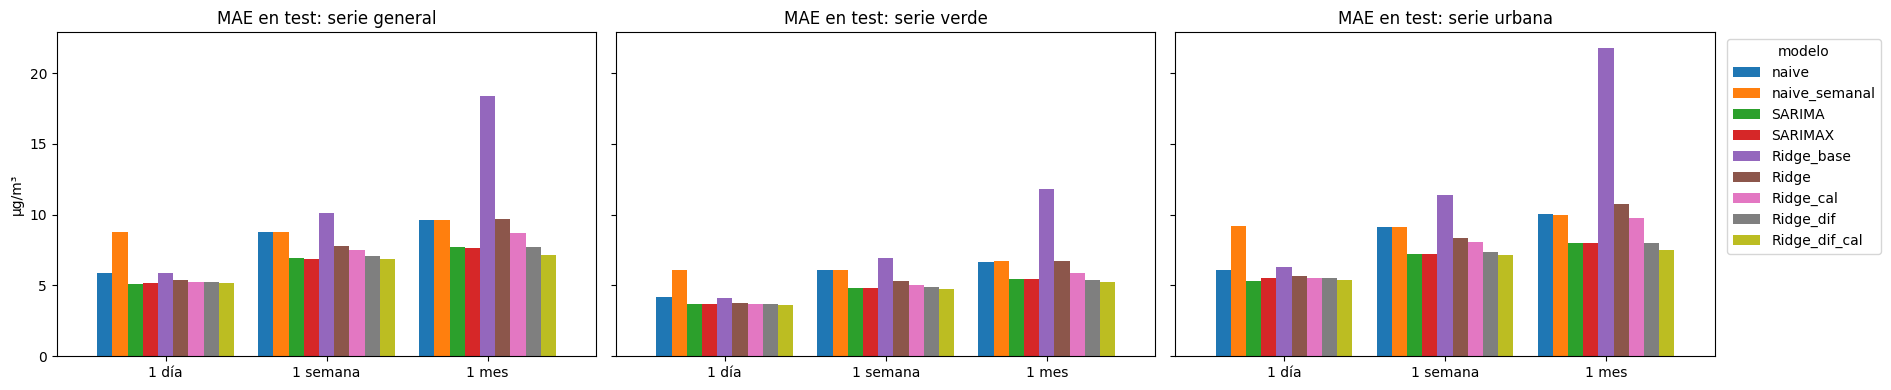

In [39]:
MODELOS_COMP = ["naive", "naive_semanal", "SARIMA", "SARIMAX"] + NOMBRES_ML
metricas_ml = metricas_test(tablas, MODELOS_COMP)
mae_ml = a_formato_ancho(metricas_ml, "MAE", MODELOS_COMP)
rmse_ml = a_formato_ancho(metricas_ml, "RMSE", MODELOS_COMP)

n_fechas = metricas_ml.groupby("horizonte")["n"].first().reindex(list(HORIZONTES)).to_dict()
print(f"Fechas de origen evaluadas por horizonte (comunes a todos los modelos): {n_fechas}\n")

# Tablas (en verde, el menor error de cada fila)
print("MAE en test (µg/m³)")
display(mae_ml.style.format("{:.2f}").highlight_min(axis=1, color="#b7e4c7"))
print("RMSE en test (µg/m³)")
display(rmse_ml.style.format("{:.2f}").highlight_min(axis=1, color="#b7e4c7"))

# Variación del MAE de cada Ridge respecto a SARIMAX
mejora = (1 - mae_ml[NOMBRES_ML].div(mae_ml["SARIMAX"], axis=0)) * 100
print("Variación del MAE respecto a SARIMAX (%, positivo = mejor que SARIMAX)")
display(mejora.round(1))

# MAE por serie y horizonte
fig, axes = plt.subplots(1, 3, figsize=(19, 4), sharey=True)
for ax, s in zip(axes, NOMBRES_SERIES):
    mae_ml.loc[s].plot(kind="bar", ax=ax, width=0.85, legend=(ax is axes[-1]))
    ax.set_title(f"MAE en test: serie {s}")
    ax.set_xlabel("")
    ax.tick_params(axis="x", rotation=0)
axes[0].set_ylabel("µg/m³")
axes[-1].legend(title="modelo", loc="upper left", bbox_to_anchor=(1.01, 1))
plt.tight_layout()
plt.show()

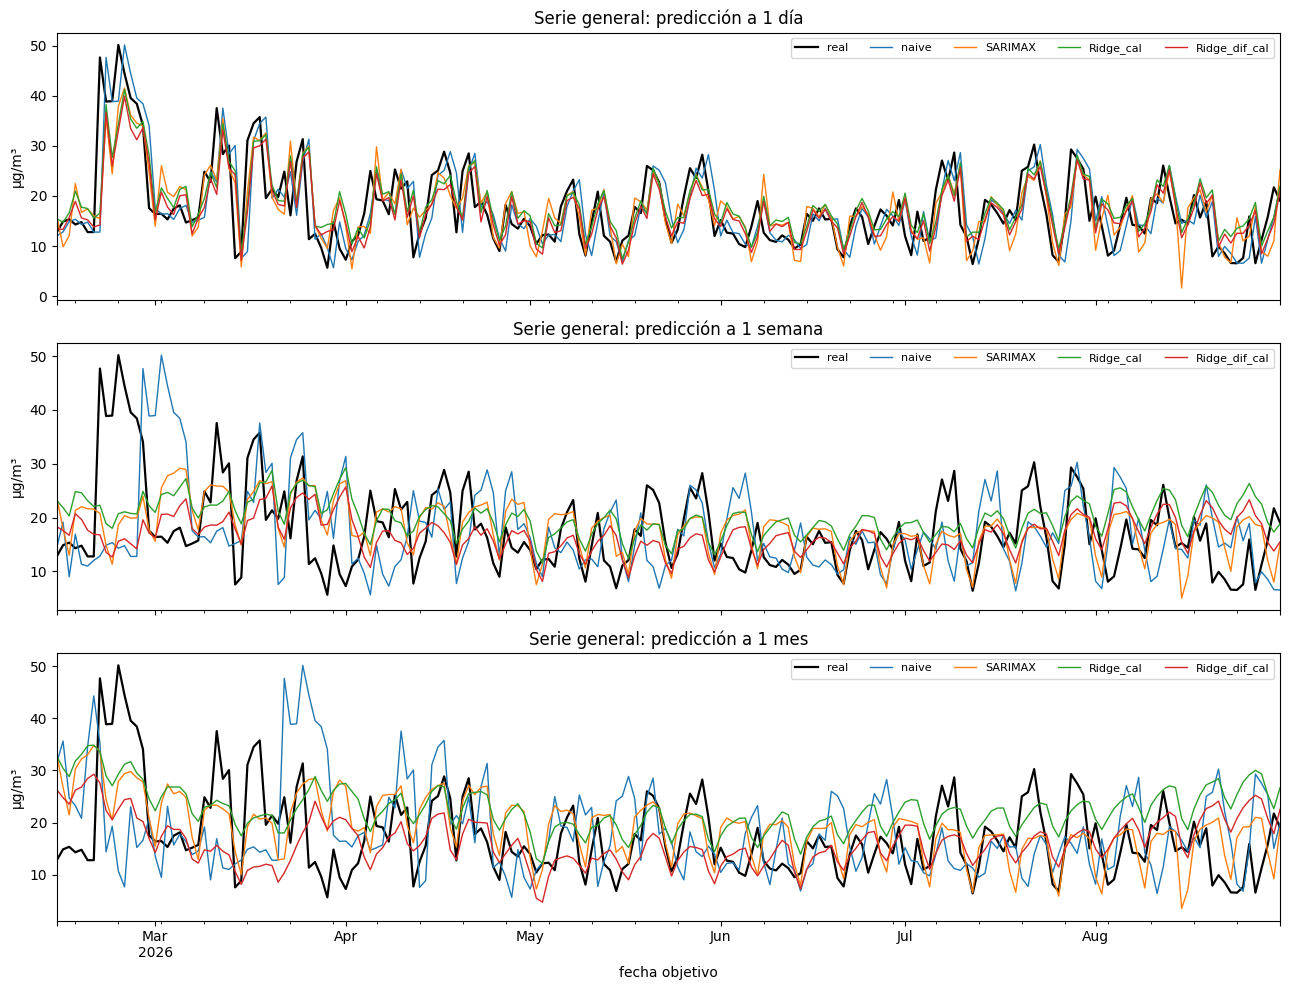

In [40]:
# Predicciones frente al valor real: serie general, últimos 200 días del test (una gráfica por horizonte)
MOSTRAR = ["naive", "SARIMAX", "Ridge_cal", "Ridge_dif_cal"]     # cambiar por los modelos que interese comparar

fig, axes = plt.subplots(3, 1, figsize=(13, 10), sharex=True)
for ax, (etiqueta, h) in zip(axes, HORIZONTES.items()):
    t = tablas[("general", etiqueta)][["objetivo", *MOSTRAR]].dropna()
    t.index = t.index + pd.Timedelta(days=h)          # se dibuja en la fecha objetivo, no en la de origen
    t = t.iloc[-200:]
    t["objetivo"].plot(ax=ax, color="black", linewidth=1.6, label="real")
    t.drop(columns="objetivo").plot(ax=ax, linewidth=1)
    ax.set_title(f"Serie general: predicción a {etiqueta}")
    ax.set_ylabel("µg/m³")
    ax.legend(ncol=5, fontsize=8, loc="upper right")
axes[-1].set_xlabel("fecha objetivo")
plt.tight_layout()
plt.show()

**Análisis de los resultados**

- **`Ridge_dif_cal` (diferenciación + calendario) es el mejor Ridge en las tres series y en los tres horizontes.** Es también el mejor de todos los modelos en 7 de los 9 casos en MAE (en general y urbana a 1 día gana SARIMA, por 0,04 y 0,07 µg/m³) y en 6 de 9 en RMSE. Frente al naive reduce el MAE un 11-13 % a 1 día, en torno a un 22 % a 1 semana y un 21-25 % a 1 mes, una mejora del mismo orden que la de los modelos clásicos en 8.1.
- **Frente a SARIMA y SARIMAX la ventaja es pequeña y solo se nota a 1 mes.** A 1 mes mejora el MAE de SARIMAX un 6,4 % en la serie general (7,17 frente a 7,66), un 3,4 % en la verde y un 6,9 % en la urbana. A 1 semana la mejora no llega al 1 % y a 1 día SARIMA sigue siendo algo mejor en la general (5,12 frente a 5,16) y en la urbana (5,35 frente a 5,42); solo en la verde `Ridge_dif_cal` queda por delante (3,63 frente a 3,66). No hemos hecho ningún test estadístico, así que diferencias de uno o dos puntos porcentuales no se leen como una ventaja clara.
- **Diferenciar es lo que más pesa.** Sin diferenciar, Ridge no mejora al naive a 1 mes (9,72 frente a 9,60 en la general, 6,74 frente a 6,65 en la verde y 10,73 frente a 10,03 en la urbana). Al diferenciar (`Ridge` → `Ridge_dif`), el MAE a 1 mes baja un 20 % en la general y en la verde y un 25 % en la urbana, mientras que a 1 día la mejora es solo del 2-3 %.
- **`Ridge_base` (7 lags, sin diferenciar) se dispara con el horizonte.** Pasa de un MAE de 5,91 a 1 día a 18,39 a 1 mes en la general, un error similar al del AR de 8.1 (17,96), que también usaba 7 lags. Encaja con lo que ya vimos en 8.1: los modelos sin diferenciar tienden a volver a la media histórica en lugar de partir del nivel reciente. No lo hemos comprobado mirando las predicciones directamente, pero el error crece mucho más con el horizonte en los modelos sin diferenciar que en los diferenciados (en la general, `Ridge_base` se multiplica por 3,1 y `Ridge_dif` por 1,5).
- **El backtesting acierta con la mejor variante.** `Ridge_dif_cal` es la mejor tanto en el backtesting como en el test.
- **Conclusión.** `Ridge_dif_cal` pasa a ser la referencia de machine learning a batir en 8.3 y 8.4, junto a SARIMA/SARIMAX como referencia clásica: mejora a los clásicos con claridad a 1 mes y los iguala a 1 día y 1 semana.

#### 8.2.2 Random Forest

**Random Forest** es un conjunto (*ensemble*) de árboles de decisión: cada árbol se entrena con una muestra distinta de los datos y con un subconjunto distinto de variables en cada división, y la predicción final es la media de todos los árboles. A diferencia de Ridge, puede capturar relaciones no lineales entre los lags y el calendario, sin que tengamos que especificarlas nosotros.

Lo implementamos igual que en el cuaderno de aplicación del profesor (Sesión II, embalses): mismo tipo de modelo (`RandomForestRegressor` con `n_estimators=300`, `random_state` fijo y `n_jobs=-1` para usar todos los núcleos), como `ForecasterRecursive` de skforecast, y buscando también la profundidad máxima del árbol (`max_depth`) como hiperparámetro, además de los lags.

Se usa como modelo **recursivo**, igual que Ridge: un único modelo predice el día siguiente a partir de sus lags, y cada predicción se reutiliza como lag del paso siguiente hasta llegar a 30 días.

**Validación:** los hiperparámetros se eligen con el mismo backtesting de 8.2.1 (12 ventanas de 30 días sobre el train), sin tocar el test.

**Con y sin diferenciación:** por el mismo motivo que en Ridge, un Random Forest sobre lags sin diferenciar puede quedarse anclado en el nivel medio del train. Además, un árbol de decisión tiene un problema añadido: no puede extrapolar fuera del rango de valores que vio en el entrenamiento, así que si el nivel de NO2 sigue bajando, un modelo sin diferenciar tiene aún más motivos para quedarse corto. Por eso probamos también aquí la versión con `differentiation=1`.

**Variantes que se comparan**

| Modelo | Qué es |
|---|---|
| `RF_base` | 7 lags, hiperparámetros del profesor (`n_estimators=300`, `max_depth=8`), sin optimizar |
| `RF` | lags y `max_depth` optimizados por backtesting |
| `RF_cal` | lo anterior + calendario (día de la semana, festivo) y ciclo anual (seno y coseno) |
| `RF_dif` | optimizado, con diferenciación |
| `RF_dif_cal` | optimizado, con diferenciación + calendario |

Reutilizamos las series y exógenas de entrenamiento (`y_train_ml`, `X_train_ml`, `exog_ml`) y las funciones (`rmse`, `crear_cv`, `predicciones_rolling_ml`, `metricas_test`, `a_formato_ancho`) ya definidas en 8.2.1.

#### Modelo base y backtesting

Igual que en 8.2.1: 7 lags e hiperparametros standar (`n_estimators=300`, `max_depth=8`).

In [41]:
from sklearn.ensemble import RandomForestRegressor

RNG = 123            # misma semilla que usa el profesor en su cuaderno, para que el resultado sea reproducible
LAGS_BASE_RF = 7      # una semana de historia, igual que Ridge_base en 8.2.1

filas = []
for s, y in y_train_ml.items():
    f = ForecasterRecursive(
        estimator=RandomForestRegressor(n_estimators=300, max_depth=8, random_state=RNG, n_jobs=-1),
        lags=LAGS_BASE_RF,
    )
    metrica, _ = backtesting_forecaster(
        forecaster=f, y=y, cv=crear_cv(y),
        metric=["mean_absolute_error", rmse], verbose=False, show_progress=False,
    )
    f.fit(y=y)                                   # el backtesting deja el modelo ajustado solo con el tramo inicial
    modelos_ml[(s, "RF_base")] = f
    filas.append({
        "serie": s, "modelo": "RF_base", "lags": LAGS_BASE_RF, "max_depth": 8,
        "MAE backtesting": metrica["mean_absolute_error"].iloc[0],
        "RMSE backtesting": metrica["rmse"].iloc[0],
    })

print("Backtesting del modelo base (µg/m³)")
display(pd.DataFrame(filas).round(2))

Backtesting del modelo base (µg/m³)


,serie,modelo,lags,max_depth,MAE backtesting,RMSE backtesting
0,general,RF_base,7,8,10.70,13.10
1,verde,RF_base,7,8,6.74,8.35
2,urbana,RF_base,7,8,12.75,15.62


#### Optimización de lags y `max_depth`

Igual que en 8.2.1, se busca con el MAE de backtesting la mejor combinación de hiperparámetros, para cada variante y en cada serie por separado.

- **Lags:** 7, 14 y 21 días (menos valores que en Ridge, porque aquí cada combinación es mucho más cara de entrenar).
- **`max_depth`:** 6, 10 y `None` (árboles sin límite de profundidad). El profesor usa `max_depth=8` sin optimizar; aquí sí lo buscamos, pero con una rejilla más pequeña que la de Ridge.
- **Durante la búsqueda usamos `n_estimators=100`** en vez de 300, para que cada combinación se entrene más rápido. Una vez elegida la mejor combinación de lags y `max_depth`, se reentrena ese modelo con los 300 árboles del profesor (celda siguiente), que es lo que realmente se evalúa después en el test.
- Si el mejor `max_depth` cae en 10 (el borde no-`None` de la rejilla), habría que ampliarla.

**Sigue siendo el paso más lento del notebook.** Con esta rejilla son 4 variantes × 3 series × 9 combinaciones = 108 entrenamientos (antes eran 360), así que debería bajar bastante el tiempo, pero puede seguir tardando varios minutos.

In [42]:
LAGS_GRID_RF = [7, 14, 21]
PARAM_GRID_RF = {"max_depth": [6, 10, None]}
N_ESTIMATORS_BUSQUEDA = 100   # menos árboles solo para la búsqueda, más rápido
N_ESTIMATORS_FINAL = 300

VARIANTES_RF = {
    "RF":         dict(exog=False, dif=None),
    "RF_cal":     dict(exog=True,  dif=None),
    "RF_dif":     dict(exog=False, dif=1),
    "RF_dif_cal": dict(exog=True,  dif=1),
}

resultados_grid_rf = {}
filas = []
inicio = time.time()
for s, y in y_train_ml.items():
    for nombre, cfg in VARIANTES_RF.items():
        f = ForecasterRecursive(
            estimator=RandomForestRegressor(n_estimators=N_ESTIMATORS_BUSQUEDA, random_state=RNG, n_jobs=-1),
            lags=LAGS_GRID_RF[0], differentiation=cfg["dif"],
        )
        res = grid_search_forecaster(
            forecaster=f, y=y, cv=crear_cv(y, cfg["dif"]),
            param_grid=PARAM_GRID_RF, lags_grid=LAGS_GRID_RF,
            exog=X_train_ml[s] if cfg["exog"] else None,
            metric="mean_absolute_error", return_best=True, verbose=False, show_progress=False,
        )
        resultados_grid_rf[(s, nombre)] = res
        mejor = res.iloc[0]

        # Reentrenamos con los 300 árboles del profesor, ya con lags y max_depth fijados
        lags_elegidos = int(np.max(mejor["lags"]))
        md = mejor["max_depth"]
        md = None if pd.isna(md) else int(md)
        f_final = ForecasterRecursive(
            estimator=RandomForestRegressor(n_estimators=N_ESTIMATORS_FINAL, max_depth=md, random_state=RNG, n_jobs=-1),
            lags=lags_elegidos, differentiation=cfg["dif"],
        )
        f_final.fit(y=y, exog=X_train_ml[s] if cfg["exog"] else None)
        modelos_ml[(s, nombre)] = f_final

        filas.append({
            "serie": s, "modelo": nombre,
            "lags": lags_elegidos, "max_depth": md,
            "MAE backtesting (búsqueda, 100 árboles)": mejor["mean_absolute_error"],
        })
    print(f"{s}: listo ({time.time() - inicio:.0f} s)")

resumen_opt_rf = pd.DataFrame(filas)
resumen_opt_rf["max_depth"] = resumen_opt_rf["max_depth"].astype("Int64")   # para que salga 4 y <NA>, no 4.0 y NaN
print("\nMejor configuración de cada modelo según el MAE de backtesting (µg/m³)")
display(resumen_opt_rf.round(2))

general: listo (668 s)
verde: listo (1175 s)
urbana: listo (1907 s)

Mejor configuración de cada modelo según el MAE de backtesting (µg/m³)


,serie,modelo,lags,max_depth,"MAE backtesting (búsqueda, 100 árboles)"
0,general,RF,21,10,8.73
1,general,RF_cal,21,<NA>,8.26
2,general,RF_dif,14,<NA>,12.50
3,general,RF_dif_cal,7,6,11.34
4,verde,RF,21,<NA>,6.19
5,verde,RF_cal,14,<NA>,5.74
6,verde,RF_dif,7,<NA>,7.92
7,verde,RF_dif_cal,14,<NA>,7.71
8,urbana,RF,21,10,9.34
9,urbana,RF_cal,21,<NA>,9.27


In [43]:
# Mapa de MAE de backtesting según lags y max_depth (ejemplo: serie general, RF sin exógenas ni diferenciación)
r = resultados_grid_rf[("general", "RF")].copy()
r["max_depth_str"] = r["max_depth"].apply(lambda v: "None" if pd.isna(v) else str(int(v)))
r["n_lags"] = r["lags"].apply(len)
tabla_resultados_rf = r.pivot(index="n_lags", columns="max_depth_str", values="mean_absolute_error")
tabla_resultados_rf.index.name = "Número de lags"
tabla_resultados_rf.columns.name = "max_depth"

display(
    tabla_resultados_rf.style
    .format("{:.3f}")
    .background_gradient(cmap="RdYlGn_r", axis=None)
    .highlight_min(axis=None, props="font-weight: bold; border: 3px solid #222;")
    .set_caption("MAE de backtesting, serie general — menor es mejor")
)

max_depth,10,6,None
Número de lags,,,
7,10.503,11.844,11.542
14,9.082,9.587,9.019
21,8.726,9.106,9.000


#### Predicción sobre el test

Igual que en 8.2.1: para cada día del test se aplica el modelo ya ajustado (sin reentrenar) a la historia reciente, y se predice hasta 30 días vista con la misma función `predicciones_rolling_ml` de 8.2.1 (no hace falta reescribirla, ya sabe usar cualquier `forecaster` de skforecast).

In [44]:
NOMBRES_RF = ["RF_base", "RF", "RF_cal", "RF_dif", "RF_dif_cal"]

with warnings.catch_warnings():
    warnings.simplefilter("ignore")
    for s in NOMBRES_SERIES:
        inicio = time.time()
        for nombre in NOMBRES_RF:
            usa_exog = VARIANTES_RF.get(nombre, {}).get("exog", False)
            pred = predicciones_rolling_ml(modelos_ml[(s, nombre)], series_imputada[s], exog_ml if usa_exog else None)
            for etiqueta, h in HORIZONTES.items():
                tablas[(s, etiqueta)][nombre] = pred[h]               # se alinea por fecha de origen
        print(f"{s}: listo ({time.time() - inicio:.0f} s)")

general: listo (272 s)
verde: listo (298 s)
urbana: listo (277 s)


#### Resultados en test

MAE y RMSE de los modelos Random Forest junto a los baselines, SARIMAX (referencia clásica) y `Ridge_dif_cal` (referencia de machine learning hasta ahora), sobre las mismas fechas.

Fechas de origen evaluadas por horizonte (comunes a todos los modelos): {'1 día': 572, '1 semana': 566, '1 mes': 543}

MAE en test (µg/m³)


RMSE en test (µg/m³)


Variación del MAE respecto a Ridge_dif_cal (%, positivo = mejor que Ridge_dif_cal)


modelo             RF_base    RF  RF_cal  RF_dif  RF_dif_cal
serie   horizonte                                           
general 1 día        -12.3  -8.1    -6.5    -8.5       -11.1
        1 semana     -27.0  -9.5    -9.1   -22.9       -33.9
        1 mes        -88.4 -19.2   -18.5  -159.2      -156.5
verde   1 día        -12.8  -6.2    -6.0   -11.3        -4.9
        1 semana     -29.4  -7.3    -9.3   -22.1       -17.5
        1 mes        -21.1  -3.5    -2.8  -123.4      -131.2
urbana  1 día        -11.9  -8.0    -6.1   -10.1        -7.6
        1 semana     -31.9 -12.2   -13.8   -29.9       -30.8
        1 mes        -84.4 -29.0   -27.3  -161.4      -185.7

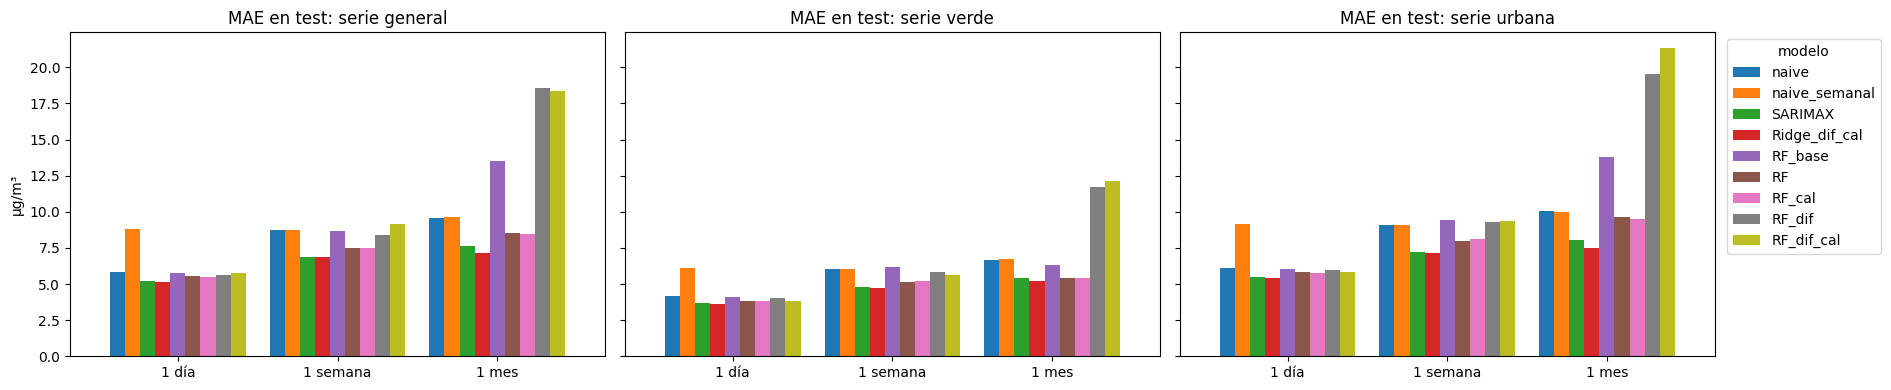

In [45]:
MODELOS_COMP_RF = ["naive", "naive_semanal", "SARIMAX", "Ridge_dif_cal"] + NOMBRES_RF
metricas_rf = metricas_test(tablas, MODELOS_COMP_RF)
mae_rf = a_formato_ancho(metricas_rf, "MAE", MODELOS_COMP_RF)
rmse_rf = a_formato_ancho(metricas_rf, "RMSE", MODELOS_COMP_RF)

n_fechas = metricas_rf.groupby("horizonte")["n"].first().reindex(list(HORIZONTES)).to_dict()
print(f"Fechas de origen evaluadas por horizonte (comunes a todos los modelos): {n_fechas}\n")

# Tablas (en verde, el menor error de cada fila)
print("MAE en test (µg/m³)")
display(mae_rf.style.format("{:.2f}").highlight_min(axis=1, color="#b7e4c7"))
print("RMSE en test (µg/m³)")
display(rmse_rf.style.format("{:.2f}").highlight_min(axis=1, color="#b7e4c7"))

# Variación del MAE de cada RF respecto a Ridge_dif_cal
mejora_rf = (1 - mae_rf[NOMBRES_RF].div(mae_rf["Ridge_dif_cal"], axis=0)) * 100
print("Variación del MAE respecto a Ridge_dif_cal (%, positivo = mejor que Ridge_dif_cal)")
display(mejora_rf.round(1))

# MAE por serie y horizonte
fig, axes = plt.subplots(1, 3, figsize=(19, 4), sharey=True)
for ax, s in zip(axes, NOMBRES_SERIES):
    mae_rf.loc[s].plot(kind="bar", ax=ax, width=0.85, legend=(ax is axes[-1]))
    ax.set_title(f"MAE en test: serie {s}")
    ax.set_xlabel("")
    ax.tick_params(axis="x", rotation=0)
axes[0].set_ylabel("µg/m³")
axes[-1].legend(title="modelo", loc="upper left", bbox_to_anchor=(1.01, 1))
plt.tight_layout()
plt.show()

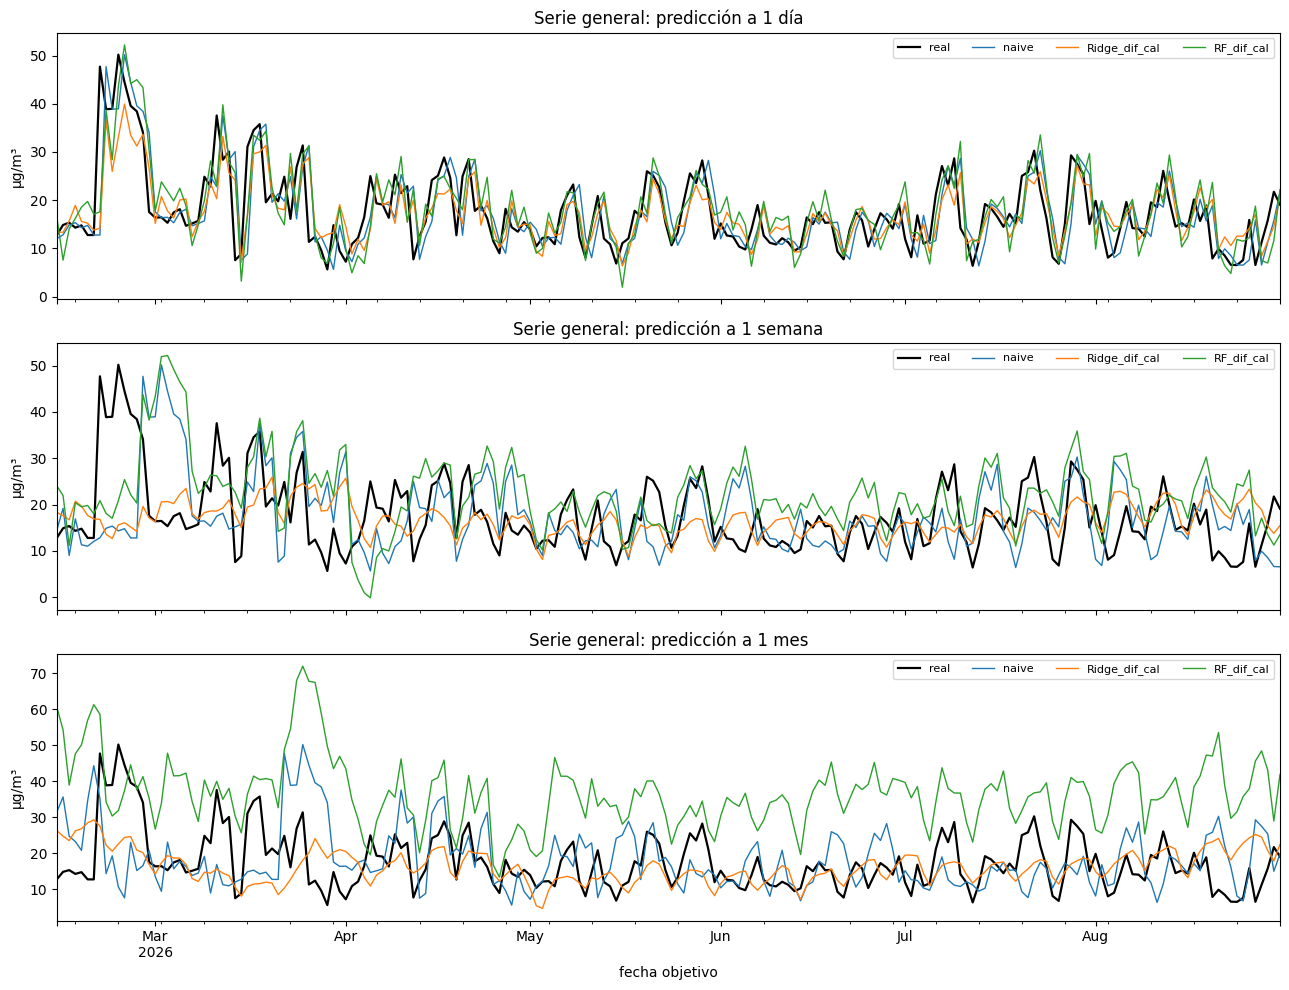

In [46]:
# Predicciones frente al valor real: serie general, últimos 200 días del test (una gráfica por horizonte)
MOSTRAR_RF = ["naive", "Ridge_dif_cal", "RF_dif_cal"]     # cambiar por los modelos que interese comparar

fig, axes = plt.subplots(3, 1, figsize=(13, 10), sharex=True)
for ax, (etiqueta, h) in zip(axes, HORIZONTES.items()):
    t = tablas[("general", etiqueta)][["objetivo", *MOSTRAR_RF]].dropna()
    t.index = t.index + pd.Timedelta(days=h)          # se dibuja en la fecha objetivo, no en la de origen
    t = t.iloc[-200:]
    t["objetivo"].plot(ax=ax, color="black", linewidth=1.6, label="real")
    t.drop(columns="objetivo").plot(ax=ax, linewidth=1)
    ax.set_title(f"Serie general: predicción a {etiqueta}")
    ax.set_ylabel("µg/m³")
    ax.legend(ncol=4, fontsize=8, loc="upper right")
axes[-1].set_xlabel("fecha objetivo")
plt.tight_layout()
plt.show()

**Análisis de los resultados**

- **El backtesting acierta con la mejor variante, y a 1 mes diferenciar es lo peor.** El backtesting (dentro del train) señalaba `RF_cal` como la mejor combinación en las tres series. En el test, `RF_cal` o `RF` ganan en casi todos los casos (la única excepción es la serie verde a 1 día, donde `RF_dif_cal` queda por delante por 0,05), y a 1 mes `RF_dif` y `RF_dif_cal` son, con diferencia, los peores de los cinco, incluso por detrás del naive.
- **El problema no es Random Forest en general, es diferenciar + predecir muchos pasos con un árbol.** `RF` y `RF_cal` (sin diferenciar) se comportan razonablemente en los tres horizontes: mejoran al naive siempre y a 1 mes se acercan a `Ridge_dif_cal` (8,49-8,54 frente a 7,17 en la serie general). En cambio, `RF_dif` y `RF_dif_cal` están bien a 1 día (apenas peor que RF) pero se disparan a 1 mes: en la serie general pasan de un MAE de 5,60-5,73 a 1 día a 18,38-18,58 a 1 mes, muy por encima incluso del naive (9,60). Lo mismo ocurre en la verde y en la urbana.
- **Por qué pasa esto.** Con `differentiation=1` el modelo no predice el valor de NO2, sino cuánto cambia de un día a otro, y luego esos cambios se van sumando para reconstruir el nivel. Un árbol de decisión, a diferencia de una regresión lineal, no puede salir del rango de valores que vio en el entrenamiento: en cada hoja predice la media de lo que vio, y esa media para el cambio diario no tiene por qué ser exactamente cero. A 1 día ese pequeño sesgo apenas se nota, pero al predecir recursivamente hasta 30 días, el sesgo de cada paso se va acumulando y el error crece con el horizonte en vez de mantenerse.
- **Es justo lo contrario de lo que pasaba con Ridge.** Allí diferenciar ayudaba en todos los horizontes (de 9,72 a unos 7,8 de MAE a 1 mes en la serie general). Con Random Forest, diferenciar ayuda a corto plazo y perjudica mucho a largo plazo: el motivo no es el mismo problema de fondo (quedarse anclado en la media histórica, como AR o `Ridge_base`), sino un sesgo que se va acumulando paso a paso solo en los modelos que diferencian.
- **El calendario aporta poco, en cualquiera de los dos grupos.** `RF_cal` mejora muy poco a `RF` (por ejemplo, 8,49 frente a 8,54 a 1 mes), y `RF_dif_cal` prácticamente iguala a `RF_dif`. Es un patrón parecido al que vimos con SARIMA y SARIMAX en 8.1.2.
- **Conclusión.** `Ridge_dif_cal` se mantiene como la referencia de machine learning a batir: en el test es mejor que el mejor Random Forest en casi todos los casos, y además es mucho más barato de entrenar. De Random Forest nos quedamos con la lección de que diferenciar no es una buena idea para este modelo con un horizonte de 30 días, aunque sí lo sea para Ridge.

### 8.3 Modelos complejos



Una **LSTM** (*Long Short-Term Memory*) es una red neuronal recurrente: en lugar de recibir los lags como columnas independientes, como Ridge o Random Forest, lee la ventana de los últimos días como una **secuencia** y va guardando una memoria interna de lo que ha visto. La diferencia no es que la LSTM «use el pasado» y los otros no (todos lo usan), sino cómo se representa y se aprende la estructura temporal.

**Cómo la implementamos:**

- `create_and_compile_model()` de skforecast construye la red (capa `LSTM` + capa densa + salida).
- `ForecasterRnn` la envuelve para entrenarla y predecir. Escala la serie con `MinMaxScaler` y se entrena con `EarlyStopping` (si la pérdida de validación deja de mejorar durante 4 épocas, se para y se recuperan los mejores pesos).
- Keras 3 con backend PyTorch, y la misma semilla (`RNG = 123`).

**Predicción directa, no recursiva.** La red se crea con `steps=30` y devuelve de golpe los 30 días siguientes. Los horizontes de 1 día, 1 semana y 1 mes se sacan de ese mismo vector (posiciones 1, 7 y 30), igual que antes. No hay errores que se acumulen al reutilizar predicciones como lags, que era lo que hundía a `RF_dif` a 1 mes en 8.2.2.

**Variantes que se comparan:**

| Modelo | Qué es |
|---|---|
| `LSTM` | solo la serie |
| `LSTM_cal` | + calendario (día de la semana, festivo) y ciclo anual (seno y coseno) |
| `LSTM_dif` | con diferenciación |
| `LSTM_dif_cal` | con diferenciación + calendario |

**Calendario.** Se pasa como variable exógena (`exog`) de `ForecasterRnn`: la red recibe las 9 columnas de `exog_ml` de los 30 días que va a predecir, que se conocen de antemano, así que no hay fuga de datos del futuro. Es el mismo calendario que en Ridge y Random Forest.

**Diferenciación.** `ForecasterRnn` no incorpora el parámetro `differentiation` de `ForecasterRecursive`, así que la hacemos a mano: la red se entrena con el **cambio diario** (`y_t − y_{t−1}`) y, para predecir, se suman los 30 cambios previstos al último valor real conocido (suma acumulada) y se reconstruye el nivel. Con predicción directa el sesgo no se acumula paso a paso como en el árbol recursivo, pero habrá que comprobarlo en el test.

**Validación.** Los hiperparámetros se eligen con un backtesting equivalente al de 8.2: las mismas 12 ventanas de 30 días sobre el final del train, `refit=False` (la red se entrena una vez con lo anterior a la primera ventana y se usa en las 12), sin tocar el test. Lo hacemos con una función propia en vez de `backtesting_forecaster_multiseries`, porque en las variantes diferenciadas esa función mediría el error de los *cambios diarios*, no el del nivel de NO2, y no sería comparable con el resto de modelos. Aquí el error se mide siempre sobre el nivel, en µg/m³.

In [47]:
# %pip install -q keras torch    # descomentar solo si hace falta (en Colab suelen venir instalados)

# Keras 3 puede usar PyTorch como backend.
# Esta variable debe definirse ANTES de importar keras (si ya se importó, reiniciar el entorno).
import os
os.environ["KERAS_BACKEND"] = "torch"

import keras
from keras.callbacks import EarlyStopping
from sklearn.preprocessing import MinMaxScaler

from skforecast.deep_learning import ForecasterRnn
from skforecast.deep_learning.utils import create_and_compile_model

# Sin barras de progreso de Keras (se harán miles de predicciones en el test)
try:
    keras.config.disable_interactive_logging()
except AttributeError:
    pass

EPOCHS = 30
BATCH_SIZE = 256
DENSE_UNITS = 16

VARIANTES_LSTM = {
    "LSTM":         dict(exog=False, dif=False),
    "LSTM_cal":     dict(exog=True,  dif=False),
    "LSTM_dif":     dict(exog=False, dif=True),
    "LSTM_dif_cal": dict(exog=True,  dif=True),
}
NOMBRES_LSTM = list(VARIANTES_LSTM)


def objetivo_red(y, dif):
    """Serie que aprende la red: el nivel o, con diferenciación, el cambio diario y_t - y_{t-1}.
    En el segundo caso se pierde el primer día (iloc[1:] conserva la frecuencia diaria)."""
    return y.diff().iloc[1:] if dif else y


def exog_alineada(indice):
    """Exógenas (calendario + ciclo anual) de exog_ml para el mismo tramo de fechas."""
    return exog_ml.loc[indice[0]:indice[-1]].asfreq("D")


def crear_forecaster_lstm(s, objetivo, lags, unidades, exog=None):
    """Crea (sin entrenar) la LSTM de la serie `s` como ForecasterRnn."""
    keras.backend.clear_session()
    keras.utils.set_random_seed(RNG)                  # misma inicialización en cada ajuste
    modelo = create_and_compile_model(
        series=objetivo.to_frame(name=s),
        lags=lags,
        steps=H_MAX,                                  # la red devuelve los 30 días de golpe
        levels=[s],
        exog=exog,                                    # None en las variantes sin calendario
        recurrent_layer="LSTM",
        recurrent_units=unidades,
        dense_units=DENSE_UNITS,
        model_name=f"LSTM_{s}",
    )
    return ForecasterRnn(
        estimator=modelo,
        levels=[s],
        lags=lags,
        transformer_series=MinMaxScaler(),
        fit_kwargs={
            "epochs": EPOCHS,
            "batch_size": BATCH_SIZE,
            "validation_split": 0.15,                 # último 15 % de las muestras, solo para el early stopping
            "callbacks": [EarlyStopping(monitor="val_loss", patience=3, restore_best_weights=True)],
            "verbose": 0,
        },
    )


def predecir_lstm(forecaster, serie, posiciones, dif, exog=None):
    """
    Predicción del NIVEL de NO2 a H_MAX días desde cada origen de `posiciones` (posiciones dentro de `serie`).
    Con dif=True la red predice cambios diarios: se reconstruye el nivel como el último valor real del origen
    más la suma acumulada de los cambios previstos. Los orígenes cuya ventana contiene algún NaN quedan en NaN.
    """
    s = serie.name
    objetivo = serie.diff() if dif else serie          # lo que ve la red (misma frecuencia diaria que serie)
    tam_ventana = forecaster.window_size               # = lags de la red
    salida = np.full((len(posiciones), H_MAX), np.nan)
    for i, pos in enumerate(posiciones):
        ini = pos - tam_ventana + 1
        if ini < (1 if dif else 0):                    # con diferenciación el primer día no tiene cambio
            continue
        ventana = objetivo.iloc[ini: pos + 1]          # solo datos hasta el día de origen
        if ventana.isna().any():
            continue
        exog_futuro = None
        if exog is not None:                           # calendario de los H_MAX días a predecir (se conoce de antemano)
            fecha = serie.index[pos]
            exog_futuro = exog.loc[fecha + pd.Timedelta(days=1): fecha + pd.Timedelta(days=H_MAX)]
            assert len(exog_futuro) == H_MAX, "el calendario no cubre los H_MAX días siguientes al origen"
        pred = forecaster.predict(steps=H_MAX, last_window=ventana.to_frame(name=s), exog=exog_futuro)
        pred = pred["pred"].to_numpy()                 # los 30 pasos, en orden
        salida[i] = serie.iloc[pos] + np.cumsum(pred) if dif else pred
    return salida


def backtesting_lstm(s, y, cfg, lags, unidades):
    """
    Backtesting como el de 8.2: la red se entrena con lo anterior a las N_BACKTEST ventanas finales del train y,
    sin reentrenar (refit=False), se predicen las N_BACKTEST ventanas de H_MAX días. El error se mide sobre el
    nivel (µg/m³), también en las variantes diferenciadas. Devuelve (MAE, RMSE) de todas las ventanas.
    """
    n = len(y)
    n0 = n - N_BACKTEST * H_MAX                                      # tamaño del tramo inicial de entrenamiento
    objetivo = objetivo_red(y, cfg["dif"])
    obj_ini = objetivo.iloc[: n0 - (1 if cfg["dif"] else 0)]         # llega hasta el día y[n0 - 1]
    exog_ini = exog_alineada(obj_ini.index) if cfg["exog"] else None
    f = crear_forecaster_lstm(s, obj_ini, lags, unidades, exog_ini)
    f.fit(series=obj_ini.to_frame(name=s), exog=exog_ini)

    posiciones = [n0 - 1 + H_MAX * k for k in range(N_BACKTEST)]    # último día conocido de cada ventana
    pred = predecir_lstm(f, y, posiciones, cfg["dif"], exog_ml if cfg["exog"] else None)
    real = np.array([y.iloc[p + 1: p + 1 + H_MAX].to_numpy() for p in posiciones])
    error = real - pred
    return np.nanmean(np.abs(error)), np.sqrt(np.nanmean(error ** 2))

#### Backtesting y elección de lags y unidades

Para cada serie y cada una de las 4 variantes se entrena una red por cada combinación de la rejilla con el train anterior a las 12 ventanas, y se mide el MAE medio de esas 12 ventanas de 30 días. Después se elige la mejor combinación y se **vuelve a crear la red desde cero** y se entrena con todo el train (no se sigue entrenando la del backtesting, que ya ha visto parte de las ventanas de validación).

In [48]:
LAGS_GRID_LSTM = [30]
UNIDADES_GRID_LSTM = [32]          # ampliable, p. ej. [16, 32]; cada valor extra multiplica el tiempo

modelos_lstm = {}                  # (serie, modelo) -> ForecasterRnn ya entrenado con todo el train
resultados_grid_lstm = {}          # (serie, modelo) -> tabla con el MAE de backtesting de cada combinación
inicio = time.time()
for s, y in y_train_ml.items():
    for nombre, cfg in VARIANTES_LSTM.items():
        filas = []
        for lags, unidades in product(LAGS_GRID_LSTM, UNIDADES_GRID_LSTM):
            mae_bt, rmse_bt = backtesting_lstm(s, y, cfg, lags, unidades)
            filas.append({"serie": s, "modelo": nombre, "lags": lags, "unidades": unidades,
                          "MAE backtesting": mae_bt, "RMSE backtesting": rmse_bt})
        res = pd.DataFrame(filas).sort_values("MAE backtesting").reset_index(drop=True)
        resultados_grid_lstm[(s, nombre)] = res

        # Modelo final: red nueva con la mejor combinación, entrenada con todo el train
        mejor = res.iloc[0]
        objetivo = objetivo_red(y, cfg["dif"])
        exog_final = exog_alineada(objetivo.index) if cfg["exog"] else None
        f_final = crear_forecaster_lstm(s, objetivo, int(mejor["lags"]), int(mejor["unidades"]), exog_final)
        f_final.fit(series=objetivo.to_frame(name=s), exog=exog_final)
        modelos_lstm[(s, nombre)] = f_final
    print(f"{s}: listo ({time.time() - inicio:.0f} s)")

# Mejor configuración de cada modelo (primera fila de cada tabla, ordenada por MAE de backtesting)
resumen_opt_lstm = pd.concat([r.iloc[[0]] for r in resultados_grid_lstm.values()], ignore_index=True)
print("\nMejor configuración de cada modelo según el MAE de backtesting (µg/m³)")
display(resumen_opt_lstm.round(2))

keras version: 3.13.2
Using backend: torch
torch version: 2.11.0+cpu



/usr/local/lib/python3.13/dist-packages/keras/src/saving/saving_lib.py:797: UserWarning: Skipping variable loading for optimizer 'adam', because it has 16 variables whereas the saved optimizer has 2 variables. 
  saveable.load_own_variables(weights_store.get(inner_path))


Using 'torch' backend with device: cpu
keras version: 3.13.2
Using backend: torch
torch version: 2.11.0+cpu

Using 'torch' backend with device: cpu


/usr/local/lib/python3.13/dist-packages/keras/src/saving/saving_lib.py:797: UserWarning: Skipping variable loading for optimizer 'adam', because it has 16 variables whereas the saved optimizer has 2 variables. 
  saveable.load_own_variables(weights_store.get(inner_path))


keras version: 3.13.2
Using backend: torch
torch version: 2.11.0+cpu

Using 'torch' backend with device: cpu


/usr/local/lib/python3.13/dist-packages/keras/src/saving/saving_lib.py:797: UserWarning: Skipping variable loading for optimizer 'adam', because it has 16 variables whereas the saved optimizer has 2 variables. 
  saveable.load_own_variables(weights_store.get(inner_path))


... (40 outputs left out)

keras version: 3.13.2
Using backend: torch
torch version: 2.11.0+cpu

Using 'torch' backend with device: cpu


/usr/local/lib/python3.13/dist-packages/keras/src/saving/saving_lib.py:797: UserWarning: Skipping variable loading for optimizer 'adam', because it has 16 variables whereas the saved optimizer has 2 variables. 
  saveable.load_own_variables(weights_store.get(inner_path))


urbana: listo (1886 s)

Mejor configuración de cada modelo según el MAE de backtesting (µg/m³)


,serie,modelo,lags,unidades,MAE backtesting,RMSE backtesting
0,general,LSTM,30,32,9.85,12.05
1,general,LSTM_cal,30,32,8.63,10.87
2,general,LSTM_dif,30,32,12.49,16.95
3,general,LSTM_dif_cal,30,32,12.14,15.37
4,verde,LSTM,30,32,6.67,8.45
5,verde,LSTM_cal,30,32,6.14,7.92
6,verde,LSTM_dif,30,32,9.66,13.44
7,verde,LSTM_dif_cal,30,32,9.51,11.69
8,urbana,LSTM,30,32,10.73,13.08
9,urbana,LSTM_cal,30,32,9.69,12.03


Curvas de entrenamiento de la LSTM final con diferenciación y calendario de la serie general: la pérdida de entrenamiento no basta por sí sola, interesa ver también la de validación para comprobar que el *early stopping* ha parado antes de sobreajustar.

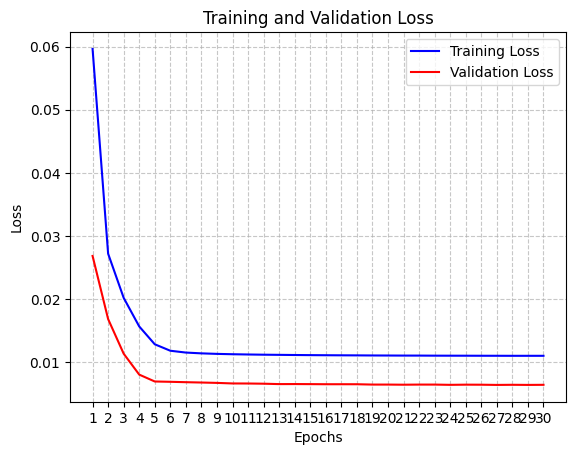

In [49]:
modelos_lstm[("general", "LSTM_dif_cal")].plot_history()
plt.show()

#### Predicción sobre el test

Igual que en 8.1 y 8.2: para cada día del test se aplica la red ya entrenada (sin reentrenar) a la ventana de historia reciente y se predicen los 30 días siguientes, de donde se sacan los tres horizontes. Es la misma función `predecir_lstm` del backtesting, así que en validación y test el procedimiento es idéntico. Si la ventana de un origen contiene algún NaN (los de diciembre de 2024), ese origen se deja en NaN y `evaluar` lo descarta, como en 8.2.

In [50]:
with warnings.catch_warnings():
    warnings.simplefilter("ignore")
    for s in NOMBRES_SERIES:
        inicio = time.time()
        serie = series_imputada[s]
        posiciones = np.flatnonzero(serie.index > FIN_TRAIN)          # orígenes: todos los días del test
        for nombre, cfg in VARIANTES_LSTM.items():
            pred = pd.DataFrame(
                predecir_lstm(modelos_lstm[(s, nombre)], serie, posiciones, cfg["dif"], exog_ml if cfg["exog"] else None),
                index=serie.index[posiciones], columns=range(1, H_MAX + 1),
            )
            for etiqueta, h in HORIZONTES.items():
                tablas[(s, etiqueta)][nombre] = pred[h]               # se alinea por fecha de origen
        print(f"{s}: listo ({time.time() - inicio:.0f} s)")

general: listo (167 s)
verde: listo (164 s)
urbana: listo (167 s)


#### Resultados en test

MAE y RMSE de las cuatro LSTM junto a los baselines, SARIMAX (referencia clásica) y los cuatro Ridge (referencia de machine learning), sobre las mismas fechas. Cada LSTM tiene un Ridge **equivalente** (`LSTM` ↔ `Ridge`, `LSTM_cal` ↔ `Ridge_cal`, `LSTM_dif` ↔ `Ridge_dif`, `LSTM_dif_cal` ↔ `Ridge_dif_cal`), y por eso se muestra la variación del MAE de cada LSTM respecto a su pareja y respecto a SARIMAX. Como en 8.2, al añadir modelos con ventana de historia propia las fechas comunes pueden ser algo menos, y las cifras de los baselines cambian ligeramente respecto a las tablas anteriores.

Fechas de origen evaluadas por horizonte (comunes a todos los modelos): {'1 día': 572, '1 semana': 566, '1 mes': 543}

MAE en test (µg/m³)


RMSE en test (µg/m³)


Variación del MAE de cada LSTM respecto a su Ridge equivalente (%, positivo = la LSTM es mejor)


LSTM  LSTM_cal  LSTM_dif  LSTM_dif_cal
serie   horizonte                                        
general 1 día     -45.9     -41.2     -12.5         -16.7
        1 semana   -8.0      -3.3     -24.4         -38.0
        1 mes      14.3       9.2     -58.4         -90.1
verde   1 día     -32.5     -50.0     -15.0         -16.1
        1 semana   -9.2     -12.8     -25.9         -51.3
        1 mes       8.8       1.4     -56.1        -138.4
urbana  1 día     -55.0     -51.0     -11.4         -19.0
        1 semana  -17.5      -7.7     -24.2         -42.7
        1 mes      13.0       8.6     -60.7        -125.0

Variación del MAE de cada LSTM respecto a SARIMAX (%, positivo = la LSTM es mejor)


LSTM  LSTM_cal  LSTM_dif  LSTM_dif_cal
serie   horizonte                                        
general 1 día     -52.1     -43.0     -14.1         -16.1
        1 semana  -22.6     -12.3     -27.6         -37.4
        1 mes      -8.8      -3.1     -59.9         -77.9
verde   1 día     -34.6     -48.8     -14.1         -13.4
        1 semana  -20.5     -18.8     -27.3         -49.8
        1 mes     -13.2      -7.2     -55.5        -130.3
urbana  1 día     -60.2     -52.0     -11.6         -16.7
        1 semana  -36.5     -20.9     -26.8         -41.6
        1 mes     -16.2     -11.0     -60.6        -109.4

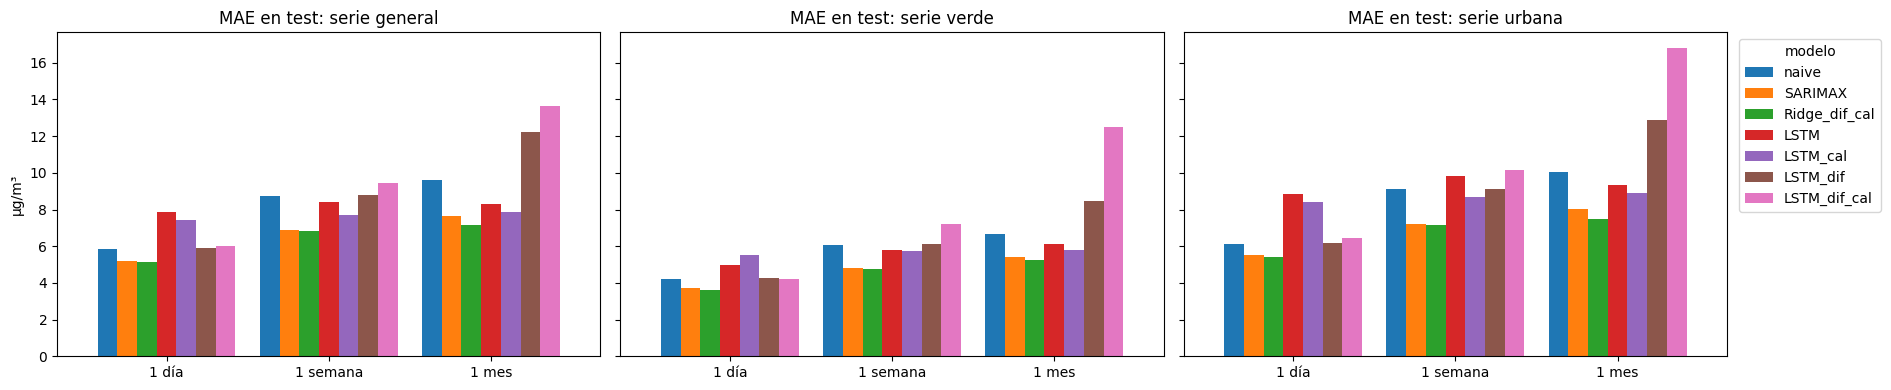

In [51]:
PAREJAS_RIDGE = {"LSTM": "Ridge", "LSTM_cal": "Ridge_cal", "LSTM_dif": "Ridge_dif", "LSTM_dif_cal": "Ridge_dif_cal"}
MODELOS_COMP_LSTM = ["naive", "naive_semanal", "SARIMAX", *PAREJAS_RIDGE.values(), *NOMBRES_LSTM]

metricas_lstm = metricas_test(tablas, MODELOS_COMP_LSTM)
mae_lstm = a_formato_ancho(metricas_lstm, "MAE", MODELOS_COMP_LSTM)
rmse_lstm = a_formato_ancho(metricas_lstm, "RMSE", MODELOS_COMP_LSTM)

n_fechas = metricas_lstm.groupby("horizonte")["n"].first().reindex(list(HORIZONTES)).to_dict()
print(f"Fechas de origen evaluadas por horizonte (comunes a todos los modelos): {n_fechas}\n")

# Tablas (en verde, el menor error de cada fila)
print("MAE en test (µg/m³)")
display(mae_lstm.style.format("{:.2f}").highlight_min(axis=1, color="#b7e4c7"))
print("RMSE en test (µg/m³)")
display(rmse_lstm.style.format("{:.2f}").highlight_min(axis=1, color="#b7e4c7"))

# Variación del MAE de cada LSTM respecto a su Ridge equivalente y respecto a SARIMAX
mejora_pareja = pd.DataFrame({l: (1 - mae_lstm[l] / mae_lstm[r]) * 100 for l, r in PAREJAS_RIDGE.items()})
mejora_sarimax = pd.DataFrame({l: (1 - mae_lstm[l] / mae_lstm["SARIMAX"]) * 100 for l in NOMBRES_LSTM})
print("Variación del MAE de cada LSTM respecto a su Ridge equivalente (%, positivo = la LSTM es mejor)")
display(mejora_pareja.round(1))
print("Variación del MAE de cada LSTM respecto a SARIMAX (%, positivo = la LSTM es mejor)")
display(mejora_sarimax.round(1))

# MAE por serie y horizonte (solo las referencias principales, para que se lea bien)
MOSTRAR_BARRAS = ["naive", "SARIMAX", "Ridge_dif_cal", *NOMBRES_LSTM]
fig, axes = plt.subplots(1, 3, figsize=(19, 4), sharey=True)
for ax, s in zip(axes, NOMBRES_SERIES):
    mae_lstm.loc[s, MOSTRAR_BARRAS].plot(kind="bar", ax=ax, width=0.85, legend=(ax is axes[-1]))
    ax.set_title(f"MAE en test: serie {s}")
    ax.set_xlabel("")
    ax.tick_params(axis="x", rotation=0)
axes[0].set_ylabel("µg/m³")
axes[-1].legend(title="modelo", loc="upper left", bbox_to_anchor=(1.01, 1))
plt.tight_layout()
plt.show()

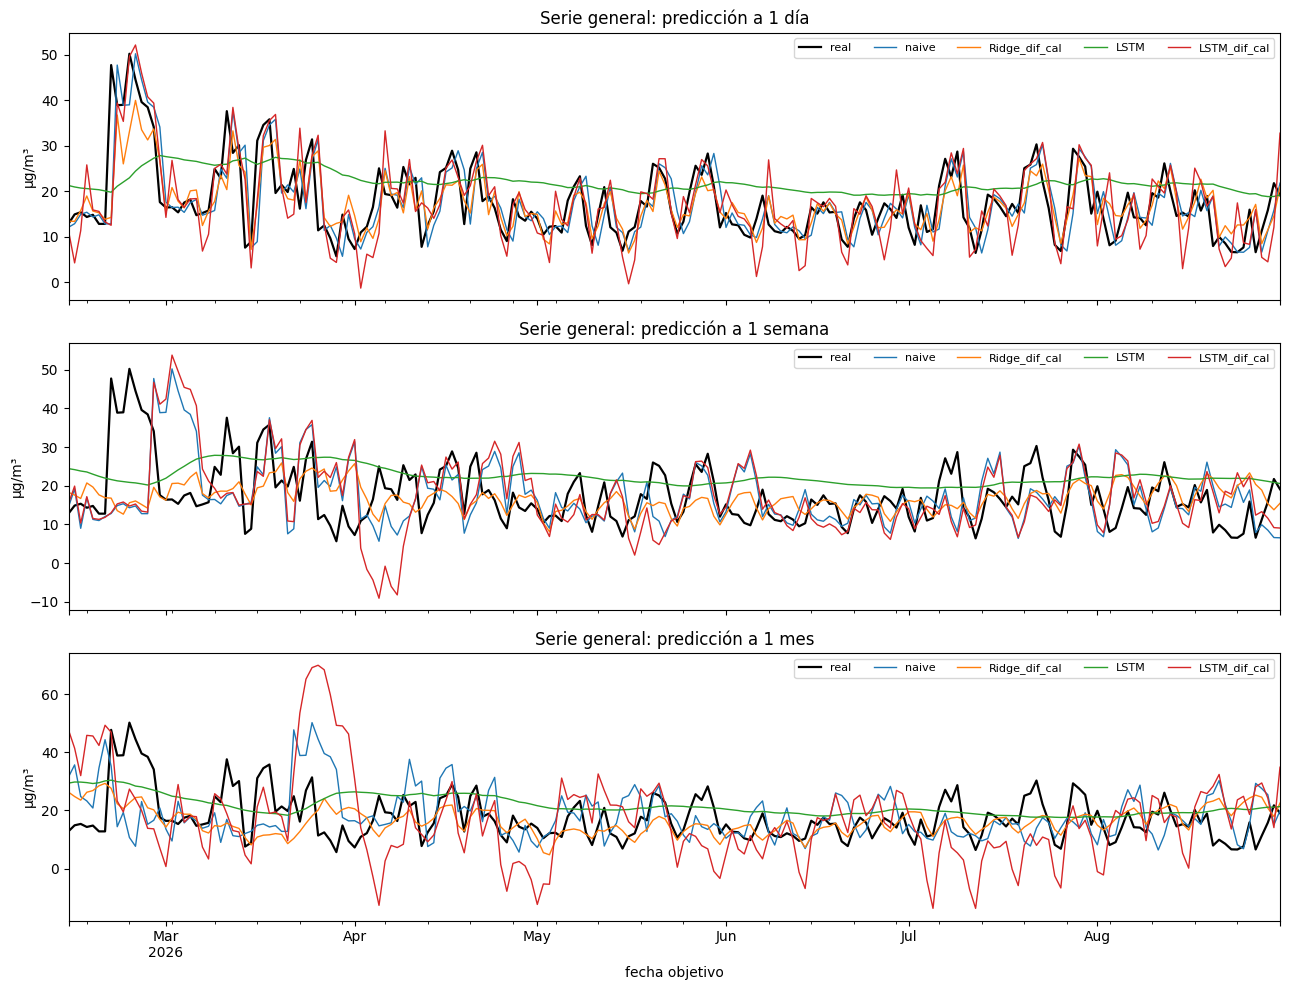

In [52]:
# Predicciones frente al valor real: serie general, últimos 200 días del test (una gráfica por horizonte)
MOSTRAR_LSTM = ["naive", "Ridge_dif_cal", "LSTM", "LSTM_dif_cal"]     # cambiar por los modelos que interese comparar

fig, axes = plt.subplots(3, 1, figsize=(13, 10), sharex=True)
for ax, (etiqueta, h) in zip(axes, HORIZONTES.items()):
    t = tablas[("general", etiqueta)][["objetivo", *MOSTRAR_LSTM]].dropna()
    t.index = t.index + pd.Timedelta(days=h)          # se dibuja en la fecha objetivo, no en la de origen
    t = t.iloc[-200:]
    t["objetivo"].plot(ax=ax, color="black", linewidth=1.6, label="real")
    t.drop(columns="objetivo").plot(ax=ax, linewidth=1)
    ax.set_title(f"Serie general: predicción a {etiqueta}")
    ax.set_ylabel("µg/m³")
    ax.legend(ncol=5, fontsize=8, loc="upper right")
axes[-1].set_xlabel("fecha objetivo")
plt.tight_layout()
plt.show()

**Análisis de los resultados**

- **Ninguna LSTM mejora a SARIMAX ni a `Ridge_dif_cal`.** `Ridge_dif_cal` tiene el menor MAE en los 9 casos. La mejor LSTM es `LSTM_cal` a 1 mes, que queda un 3 % (general), un 7 % (verde) y un 11 % (urbana) por detrás de SARIMAX.
- **A 1 día, ninguna LSTM mejora al naive.** Las sin diferenciar son mucho peores (hasta un 45 % más de MAE) y las diferenciadas quedan prácticamente igual.
- **A 1 semana y a 1 mes, `LSTM_cal` sí mejora al naive en las tres series.** A 1 mes reduce el MAE entre un 11 % y un 18 %, y supera a `Ridge` y `Ridge_cal` (`Ridge` ni siquiera mejora al naive). Aun así, no alcanza a `Ridge_dif`, `Ridge_dif_cal` ni SARIMAX.
- **Diferenciar perjudica a la LSTM, al revés que a Ridge.** A 1 mes, el MAE de `LSTM_dif` es entre un 37 % y un 47 % mayor que el de `LSTM`, y `LSTM_dif_cal` pasa de 6,02 a 1 día a 13,62 a 1 mes en la serie general. Una posible causa es que el error de cada cambio diario se acumula al reconstruir el nivel, pero no lo hemos comprobado.
- **El calendario ayuda a la LSTM sin diferenciar** (`LSTM` → `LSTM_cal`: entre un 1 % y un 11 % menos de MAE a 1 semana y un 5 % a 1 mes), **pero no a la diferenciada.**
- **Conclusión.** La LSTM no aporta valor frente a modelos más sencillos: `Ridge_dif_cal` es mejor y mucho más barato de entrenar, y sigue siendo la referencia de machine learning a batir. Cada red es un único entrenamiento con semilla fija y una rejilla mínima, así que las diferencias pequeñas no se leen como ventaja clara.

### 8.4 Variables exógenas: lluvia y viento

Hasta ahora, la única variable externa que hemos usado es el calendario (8.1.2, 8.2), que se conoce con certeza para cualquier fecha futura. Aquí añadimos lluvia y viento, que no se conocen con la misma certeza: solo usamos su valor de **ayer** (retardo de 1 día), nunca el de hoy ni el de mañana, para no meter información del futuro. Por el mismo motivo, esto solo se aplica al horizonte de **1 día**: a 1 semana o 1 mes vista ya no tendría sentido suponer que conocemos la lluvia o el viento de ayer como si fuera representativa de lo que hará dentro de una semana.

Descartamos el tráfico como variable exógena: el dato diario por sensor solo cubre desde julio de 2013 (nos faltaría casi la mitad del train), y el dato que cubre casi todo el periodo (desde 2004-2005) es mensual, no diario, así que no sirve como un retardo de 1 día comparable al de la lluvia o el viento.

#### Obtención de datos (AEMET)

Conseguimos los datos desde la AEMET, con la estación Madrid-Retiro (indicativo 3195), céntrica y con datos diarios desde 1920, lo que cubre sin problema todo nuestro rango (2001-2026). Nos quedamos con dos variables: `prec` (precipitación diaria, mm) y `velmedia` (velocidad media del viento, m/s).


In [53]:
RUTA_PRECIPITACION = CARPETA_DATOS / "retiro_precipitacion_sol_2001_2026.csv"
RUTA_VIENTO = CARPETA_DATOS / "retiro_viento_2001_2026.csv"

precipitacion = pd.read_csv(RUTA_PRECIPITACION, sep=None, engine="python")[["fecha", "precipitacion_lm2"]]
precipitacion["fecha"] = pd.to_datetime(precipitacion["fecha"], format="%Y-%m-%d")

# Viento: el CSV trae cabeceras repetidas ("FECHA...") mezcladas con los datos; se filtran antes de convertir la fecha
viento_bruto = pd.read_csv(RUTA_VIENTO, sep=None, engine="python")
es_fecha_valida = viento_bruto["fecha"].astype(str).str.match(r"^\d{2}-\d{2}-\d{4}$")
print(f"Viento: {len(viento_bruto)} filas leídas, {(~es_fecha_valida).sum()} descartadas (cabeceras repetidas u otro ruido)")

viento = viento_bruto[es_fecha_valida][["fecha", "velocidad_media"]].copy()
viento["fecha"] = pd.to_datetime(viento["fecha"], format="%d-%m-%Y")

# Una sola tabla, con el día como índice
meteo = precipitacion.merge(viento, on="fecha", how="outer").set_index("fecha").sort_index().asfreq("D")
# Fuerza ambas columnas a número (cualquier valor no numérico que quedara se convierte en NaN y se interpola igual)
meteo = meteo.apply(pd.to_numeric, errors="coerce").interpolate(limit=2)
print(f"Huecos tras interpolar: precipitación {meteo['precipitacion_lm2'].isna().sum()}, viento {meteo['velocidad_media'].isna().sum()}")

print(f"\nRango: {meteo.index.min().date()} -> {meteo.index.max().date()} ({len(meteo)} días)")
print(f"Huecos: precipitación {meteo['precipitacion_lm2'].isna().sum()}, viento {meteo['velocidad_media'].isna().sum()}")
print(f"\nDías con velocidad media en 0 (sobre los días con dato): {(meteo['velocidad_media'] == 0).sum()} de {meteo['velocidad_media'].notna().sum()}")
print("Fracción de días en 0, por año (NaN no cuenta como 0):")
print(meteo.assign(cero=lambda d: d["velocidad_media"] == 0).where(meteo["velocidad_media"].notna()).groupby(meteo.index.year)["cero"].mean().round(2).to_string())

meteo.tail()

Viento: 9373 filas leídas, 2 descartadas (cabeceras repetidas u otro ruido)
Huecos tras interpolar: precipitación 0, viento 0

Rango: 2001-01-01 -> 2026-08-31 (9374 días)
Huecos: precipitación 0, viento 0

Días con velocidad media en 0 (sobre los días con dato): 1038 de 9374
Fracción de días en 0, por año (NaN no cuenta como 0):
fecha
2001    0.00
2002    0.24
2003    0.51
2004    0.01
2005    0.00
2006    0.04
2007    0.20
2008    0.05
2009    0.00
2010    0.01
2011    0.01
2012    0.01
2013    0.01
2014    0.01
2015    0.01
2016    0.02
2017    0.03
2018    0.06
2019    0.00
2020    0.36
2021    1.00
2022    0.27
2023    0.00
2024    0.01
2025    0.01
2026    0.00


,precipitacion_lm2,velocidad_media
fecha,,
2026-08-27,0.0,14.04
2026-08-28,0.0,6.12
2026-08-29,0.0,6.12
2026-08-30,0.0,11.16
2026-08-31,0.0,6.84


In [54]:
# ¿Son las mismas 3 fechas sin dato en las dos variables?
huecos_prec = meteo[meteo["precipitacion_lm2"].isna()].index
huecos_viento = meteo[meteo["velocidad_media"].isna()].index
print("Huecos precipitación:", list(huecos_prec.strftime("%Y-%m-%d")))
print("Huecos viento:       ", list(huecos_viento.strftime("%Y-%m-%d")))

Huecos precipitación: []
Huecos viento:        []


#### Preparación: retardo y alineación

Se añaden `precipitacion_lm2` y `velocidad_media`, retardadas 1 día (el valor de ayer, no el de hoy), al calendario ya construido en 8.1.2. Al ser un retardo de 1 día, solo se puede calcular hasta el último día con dato real (31-08-2026); no se extiende 30 días hacia el futuro como el calendario, porque no conocemos la lluvia o el viento de mañana. Por eso esta tabla solo sirve para el horizonte de 1 día, tal como se decidió.

In [55]:
# Lluvia y viento de "ayer": se desplaza la tabla un día hacia delante
clima_ayer = meteo.shift(1).rename(columns={
    "precipitacion_lm2": "lluvia_ayer",
    "velocidad_media": "viento_ayer",
})

# Se une al calendario ya construido en 8.1.2 (dia_1..dia_6, festivo), solo en las fechas donde hay clima de ayer
exog_dia1 = calendario.join(clima_ayer, how="inner").dropna()

print(f"Exógenas para horizonte 1 día: {exog_dia1.shape[0]} fechas, columnas: {list(exog_dia1.columns)}")
print(f"Rango: {exog_dia1.index.min().date()} -> {exog_dia1.index.max().date()}")
exog_dia1.tail()

Exógenas para horizonte 1 día: 9373 fechas, columnas: ['dia_1', 'dia_2', 'dia_3', 'dia_4', 'dia_5', 'dia_6', 'festivo', 'lluvia_ayer', 'viento_ayer']
Rango: 2001-01-02 -> 2026-08-31


,dia_1,dia_2,dia_3,dia_4,dia_5,dia_6,festivo,lluvia_ayer,viento_ayer
2026-08-27,0.0,0.0,1.0,0.0,0.0,0.0,0.0,2.8,11.88
2026-08-28,0.0,0.0,0.0,1.0,0.0,0.0,0.0,0.0,14.04
2026-08-29,0.0,0.0,0.0,0.0,1.0,0.0,0.0,0.0,6.12
2026-08-30,0.0,0.0,0.0,0.0,0.0,1.0,0.0,0.0,6.12
2026-08-31,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,11.16


#### Comparación con y sin exógenas

Se comparan SARIMAX, `Ridge_dif_cal`, `RF_dif_cal` y `LSTM_dif_cal` con una versión nueva de cada uno que añade lluvia y viento (retardados 1 día) al calendario que ya tenían. Como el retardo de 1 día solo se conoce con certeza un día hacia delante, esta comparación se queda en el horizonte de 1 día: no tiene sentido fingir que sabemos la lluvia o el viento de dentro de una semana o un mes.

Los cuatro modelos con meteo reutilizan los hiperparámetros ya elegidos para su versión con calendario (`lags`, `alpha`, `max_depth`, unidades): aquí no se vuelve a optimizar nada, solo se reentrena cada uno con `exog_dia1` en vez de `calendario` o `exog_ml`, y se compara.

In [56]:
# Los 3 días sueltos sin dato se interpolan (igual que con la serie de NO2), para no romper la frecuencia diaria
meteo = meteo.interpolate(limit=2)
print(f"Huecos tras interpolar: precipitación {meteo['precipitacion_lm2'].isna().sum()}, viento {meteo['velocidad_media'].isna().sum()}")

# Lluvia y viento de "ayer": se desplaza la tabla un día hacia delante
clima_ayer = meteo.shift(1).rename(columns={
    "precipitacion_lm2": "lluvia_ayer",
    "velocidad_media": "viento_ayer",
})

# Se une al calendario ya construido en 8.1.2 (dia_1..dia_6, festivo), solo en las fechas donde hay clima de ayer
exog_dia1 = calendario.join(clima_ayer, how="inner").dropna()

print(f"Exógenas para horizonte 1 día: {exog_dia1.shape[0]} fechas, columnas: {list(exog_dia1.columns)}")
print(f"Rango: {exog_dia1.index.min().date()} -> {exog_dia1.index.max().date()}")


def alinear_con_meteo(y):
    """Recorta la serie a las fechas con exógeno disponible y fija freq='D'."""
    exog = exog_dia1.reindex(y.index).dropna()
    return y.loc[exog.index].asfreq("D"), exog.asfreq("D")


# --- Ridge y RF con meteo: mismos lags/alpha/max_depth ya elegidos para *_dif_cal ---
modelos_ml_meteo = {}
inicio = time.time()
for s in NOMBRES_SERIES:
    y_ajustada, exog_train = alinear_con_meteo(y_train_ml[s])

    fila_ridge = resumen_opt[(resumen_opt["serie"] == s) & (resumen_opt["modelo"] == "Ridge_dif_cal")].iloc[0]
    f_ridge = ForecasterRecursive(estimator=Ridge(alpha=fila_ridge["alpha"]), lags=int(fila_ridge["lags"]), differentiation=1)
    f_ridge.fit(y=y_ajustada, exog=exog_train)
    modelos_ml_meteo[(s, "Ridge_dif_cal_meteo")] = f_ridge

    fila_rf = resumen_opt_rf[(resumen_opt_rf["serie"] == s) & (resumen_opt_rf["modelo"] == "RF_dif_cal")].iloc[0]
    md = None if pd.isna(fila_rf["max_depth"]) else int(fila_rf["max_depth"])
    f_rf = ForecasterRecursive(
        estimator=RandomForestRegressor(n_estimators=N_ESTIMATORS_FINAL, max_depth=md, random_state=RNG, n_jobs=-1),
        lags=int(fila_rf["lags"]), differentiation=1,
    )
    f_rf.fit(y=y_ajustada, exog=exog_train)
    modelos_ml_meteo[(s, "RF_dif_cal_meteo")] = f_rf
print(f"Ridge y RF con meteo: listos ({time.time() - inicio:.0f} s)")


# --- SARIMAX con meteo: mismo orden que SARIMAX de 8.1.2, con calendario + lluvia + viento ---
modelos_sarimax_meteo = {}
inicio = time.time()
for s in NOMBRES_SERIES:
    y, exog_train = alinear_con_meteo(train[s].dropna())
    modelos_sarimax_meteo[s] = ajustar_sarima(y.to_numpy(), orden_base, orden_est, exog=exog_train.to_numpy())
print(f"SARIMAX con meteo: listos ({time.time() - inicio:.0f} s)")


# --- LSTM con meteo: variante LSTM_dif_cal, mismos lags/unidades ya elegidos ---
modelos_lstm_meteo = {}
inicio = time.time()
for s, y in y_train_ml.items():
    objetivo, exog_train = alinear_con_meteo(objetivo_red(y, dif=True))
    f = crear_forecaster_lstm(s, objetivo, LAGS_GRID_LSTM[0], UNIDADES_GRID_LSTM[0], exog_train)
    f.fit(series=objetivo.to_frame(name=s), exog=exog_train)
    modelos_lstm_meteo[s] = f
print(f"LSTM con meteo: listas ({time.time() - inicio:.0f} s)")

Huecos tras interpolar: precipitación 0, viento 0
Exógenas para horizonte 1 día: 9373 fechas, columnas: ['dia_1', 'dia_2', 'dia_3', 'dia_4', 'dia_5', 'dia_6', 'festivo', 'lluvia_ayer', 'viento_ayer']
Rango: 2001-01-02 -> 2026-08-31
Ridge y RF con meteo: listos (134 s)
SARIMAX con meteo: listos (240 s)
keras version: 3.13.2
Using backend: torch
torch version: 2.11.0+cpu

Using 'torch' backend with device: cpu


/usr/local/lib/python3.13/dist-packages/keras/src/saving/saving_lib.py:797: UserWarning: Skipping variable loading for optimizer 'adam', because it has 16 variables whereas the saved optimizer has 2 variables. 
  saveable.load_own_variables(weights_store.get(inner_path))


keras version: 3.13.2
Using backend: torch
torch version: 2.11.0+cpu

Using 'torch' backend with device: cpu


/usr/local/lib/python3.13/dist-packages/keras/src/saving/saving_lib.py:797: UserWarning: Skipping variable loading for optimizer 'adam', because it has 16 variables whereas the saved optimizer has 2 variables. 
  saveable.load_own_variables(weights_store.get(inner_path))


keras version: 3.13.2
Using backend: torch
torch version: 2.11.0+cpu

Using 'torch' backend with device: cpu


/usr/local/lib/python3.13/dist-packages/keras/src/saving/saving_lib.py:797: UserWarning: Skipping variable loading for optimizer 'adam', because it has 16 variables whereas the saved optimizer has 2 variables. 
  saveable.load_own_variables(weights_store.get(inner_path))


LSTM con meteo: listas (337 s)


#### Predicción sobre el test

Para cada modelo, en cada origen del test, se predice un único paso (mañana), usando el calendario de mañana (conocido) y la lluvia/viento de hoy (ya ocurrido, por eso "ayer" respecto a mañana). Al ser un solo paso, no hace falta la ventana de 30 días que usábamos para los demás horizontes: Ridge, RF y SARIMAX/LSTM usan cada uno su propia noción de "historia reciente" (el número de lags, o los últimos 365 días en SARIMAX).

In [57]:
def predicciones_dia1_ml(forecaster, serie):
    """Predicción a 1 día con Ridge/RF: usa exog_dia1 (calendario de mañana + clima de hoy)."""
    tam_ventana = forecaster.window_size
    posiciones = np.flatnonzero(serie.index > FIN_TRAIN)
    salida = np.full(len(posiciones), np.nan)
    for i, pos in enumerate(posiciones):
        ini = pos - tam_ventana + 1
        if ini < 0:
            continue
        ventana = serie.iloc[ini: pos + 1]
        fecha_objetivo = serie.index[pos] + pd.Timedelta(days=1)
        if ventana.isna().any() or fecha_objetivo not in exog_dia1.index:
            continue
        exog_manana = exog_dia1.loc[[fecha_objetivo]]
        salida[i] = forecaster.predict(steps=1, last_window=ventana, exog=exog_manana).iloc[0]
    return pd.Series(salida, index=serie.index[posiciones])


def predicciones_dia1_sarimax(res, serie, ventana=365):
    """Predicción a 1 día con SARIMAX: ventana fija de 365 días, igual que en 8.1.2."""
    posiciones = np.flatnonzero(serie.index > FIN_TRAIN)
    salida = np.full(len(posiciones), np.nan)
    for i, pos in enumerate(posiciones):
        ini = max(0, pos - ventana + 1)
        valores = serie.iloc[ini: pos + 1]
        fecha_objetivo = serie.index[pos] + pd.Timedelta(days=1)
        if valores.isna().any() or fecha_objetivo not in exog_dia1.index:
            continue
        exog_ventana = exog_dia1.reindex(valores.index)
        if exog_ventana.isna().any().any():
            continue
        exog_manana = exog_dia1.loc[[fecha_objetivo]].to_numpy()
        with warnings.catch_warnings():
            warnings.simplefilter("ignore")
            salida[i] = res.apply(valores.to_numpy(), exog=exog_ventana.to_numpy()).forecast(1, exog=exog_manana)[0]
    return pd.Series(salida, index=serie.index[posiciones])


def predicciones_dia1_lstm(forecaster, serie):
    """Predicción a 1 día con la LSTM (variante dif_cal): reconstruye sumando el cambio previsto, recortado a 0."""
    s = serie.name
    objetivo = serie.diff()
    tam_ventana = forecaster.window_size
    posiciones = np.flatnonzero(serie.index > FIN_TRAIN)
    salida = np.full(len(posiciones), np.nan)
    for i, pos in enumerate(posiciones):
        ini = pos - tam_ventana + 1
        if ini < 1:
            continue
        ventana = objetivo.iloc[ini: pos + 1]
        fecha_objetivo = serie.index[pos] + pd.Timedelta(days=1)
        if ventana.isna().any() or fecha_objetivo not in exog_dia1.index:
            continue
        exog_manana = exog_dia1.loc[[fecha_objetivo]]
        pred = forecaster.predict(steps=1, last_window=ventana.to_frame(name=s), exog=exog_manana)["pred"].to_numpy()
        salida[i] = serie.iloc[pos] + pred[0]
    return pd.Series(salida, index=serie.index[posiciones])


# Se añade una columna por modelo a la tabla de "1 día" que ya existe
for s in NOMBRES_SERIES:
    inicio = time.time()
    serie = series_imputada[s]

    tabla = tablas[(s, "1 día")]
    tabla["SARIMAX_meteo"]       = predicciones_dia1_sarimax(modelos_sarimax_meteo[s], serie)
    tabla["Ridge_dif_cal_meteo"] = predicciones_dia1_ml(modelos_ml_meteo[(s, "Ridge_dif_cal_meteo")], serie)
    tabla["RF_dif_cal_meteo"]    = predicciones_dia1_ml(modelos_ml_meteo[(s, "RF_dif_cal_meteo")], serie)
    tabla["LSTM_dif_cal_meteo"]  = predicciones_dia1_lstm(modelos_lstm_meteo[s], serie)

    print(f"{s}: listo ({time.time() - inicio:.0f} s)")

general: listo (60 s)
verde: listo (60 s)
urbana: listo (60 s)


#### Resultados en test

MAE y RMSE de cada modelo, con y sin lluvia/viento, sobre las mismas fechas, solo a horizonte 1 día (el único donde existen las versiones con meteo). Cada modelo con meteo se compara con su pareja sin meteo (`SARIMAX` ↔ `SARIMAX_meteo`, y lo mismo para Ridge, RF y la LSTM).

Fechas de origen evaluadas, por serie (horizonte 1 día): {'general': 243, 'urbana': 243, 'verde': 243}

MAE en test, horizonte 1 día (µg/m³)


modelo,naive,naive_semanal,SARIMAX,SARIMAX_meteo,Ridge_dif_cal,Ridge_dif_cal_meteo,RF_dif_cal,RF_dif_cal_meteo,LSTM_dif_cal,LSTM_dif_cal_meteo
serie,,,,,,,,,,
general,5.21,8.56,5.00,4.95,4.81,4.78,5.41,5.24,5.69,5.97
urbana,5.45,8.98,5.35,5.22,5.04,4.98,5.58,5.42,6.12,6.27
verde,3.53,5.72,3.43,3.40,3.25,3.23,3.43,3.24,3.85,4.02


RMSE en test, horizonte 1 día (µg/m³)


modelo,naive,naive_semanal,SARIMAX,SARIMAX_meteo,Ridge_dif_cal,Ridge_dif_cal_meteo,RF_dif_cal,RF_dif_cal_meteo,LSTM_dif_cal,LSTM_dif_cal_meteo
serie,,,,,,,,,,
general,7.17,11.33,6.68,6.59,6.52,6.42,7.21,6.97,7.71,7.84
urbana,7.40,11.73,7.03,6.88,6.72,6.62,7.35,7.13,8.20,8.22
verde,5.07,7.64,4.65,4.63,4.52,4.47,4.80,4.63,5.39,5.52


Variación del MAE al añadir lluvia/viento (%, positivo = mejora)


,SARIMAX_meteo,Ridge_dif_cal_meteo,RF_dif_cal_meteo,LSTM_dif_cal_meteo
serie,,,,
general,1.1,0.5,3.1,-4.9
urbana,2.4,1.1,2.8,-2.5
verde,0.7,0.5,5.6,-4.5


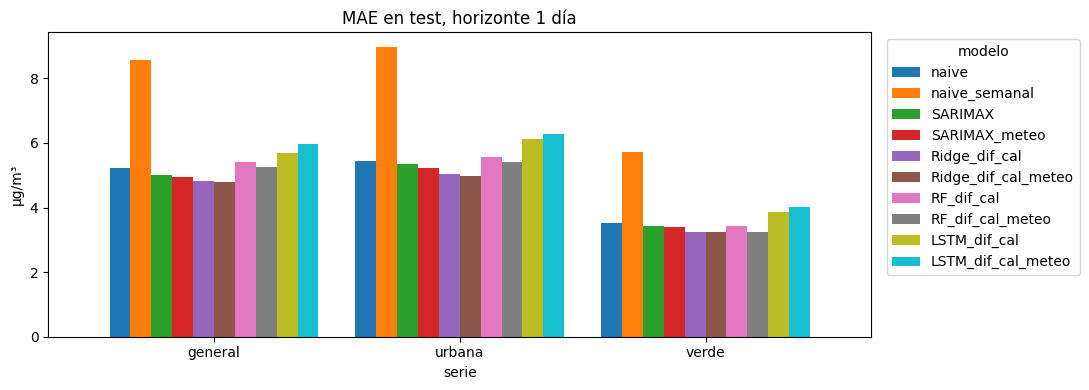

In [58]:
MODELOS_METEO = [
    "naive", "naive_semanal",
    "SARIMAX", "SARIMAX_meteo",
    "Ridge_dif_cal", "Ridge_dif_cal_meteo",
    "RF_dif_cal", "RF_dif_cal_meteo",
    "LSTM_dif_cal", "LSTM_dif_cal_meteo",
]

filas = []
for s in NOMBRES_SERIES:
    m = evaluar(tablas[(s, "1 día")], FIN_TRAIN, FIN_DATOS, MODELOS_METEO)
    for modelo, valores in m.items():
        filas.append({"serie": s, "modelo": modelo, **valores})
metricas_meteo = pd.DataFrame(filas)

mae_meteo = metricas_meteo.pivot(index="serie", columns="modelo", values="MAE")[MODELOS_METEO]
rmse_meteo = metricas_meteo.pivot(index="serie", columns="modelo", values="RMSE")[MODELOS_METEO]

n_fechas = metricas_meteo.groupby("serie")["n"].first().to_dict()
print(f"Fechas de origen evaluadas, por serie (horizonte 1 día): {n_fechas}\n")

print("MAE en test, horizonte 1 día (µg/m³)")
display(mae_meteo.style.format("{:.2f}").highlight_min(axis=1, color="#b7e4c7"))
print("RMSE en test, horizonte 1 día (µg/m³)")
display(rmse_meteo.style.format("{:.2f}").highlight_min(axis=1, color="#b7e4c7"))

# Variación del MAE de cada modelo "con meteo" respecto a su pareja "sin meteo"
PAREJAS_METEO = {
    "SARIMAX_meteo": "SARIMAX",
    "Ridge_dif_cal_meteo": "Ridge_dif_cal",
    "RF_dif_cal_meteo": "RF_dif_cal",
    "LSTM_dif_cal_meteo": "LSTM_dif_cal",
}
mejora_meteo = pd.DataFrame({m: (1 - mae_meteo[m] / mae_meteo[par]) * 100 for m, par in PAREJAS_METEO.items()})
print("Variación del MAE al añadir lluvia/viento (%, positivo = mejora)")
display(mejora_meteo.round(1))

# MAE por serie
fig, ax = plt.subplots(figsize=(11, 4))
mae_meteo.plot(kind="bar", ax=ax, width=0.85)
ax.set_title("MAE en test, horizonte 1 día")
ax.set_ylabel("µg/m³")
ax.tick_params(axis="x", rotation=0)
ax.legend(title="modelo", loc="upper left", bbox_to_anchor=(1.01, 1))
plt.tight_layout()
plt.show()

- **Lluvia y viento ayudan a SARIMAX, Ridge y Random Forest, aunque poco.** La mejora va del 0,5 % al 2,4 % en SARIMAX y Ridge, y es algo mayor en Random Forest (2,8 %-5,6 %), el que más partido le saca a la meteo de los cuatro.
- **A la LSTM le perjudica.** `LSTM_dif_cal_meteo` empeora a `LSTM_dif_cal` en las tres series (entre un 2,5 % y un 4,9 % más de MAE), el único de los cuatro modelos donde añadir variables no ayuda.
- **`Ridge_dif_cal_meteo` sigue siendo el mejor modelo de toda la comparación**, en las tres series, con o sin meteo. Con esto se confirma como referencia a batir, ahora también frente a variables meteorológicas.
- **La LSTM sigue siendo el modelo más débil**, incluso peor que el naive en general y urbana (5,69-6,12 frente a 5,21-5,45), algo que ya vimos en 8.3 y que aquí se repite y se agrava un poco con la meteo.
- Las diferencias son pequeñas (menos de un punto de MAE en la mayoría de los casos) y no se ha hecho ningún contraste estadístico, así que "ayuda" aquí significa una mejora consistente en dirección, no necesariamente grande.

## 9. Aplicación: alertas y comparación de zonas

Esta sección no compara más modelos entre sí: usa el mejor modelo de la sección 8 (junto al naive, como referencia) para responder a las preguntas de la sección 2 que seguían abiertas —no solo "qué tan bien predice", sino "para qué sirve". Se organiza en tres bloques: alerta a corto plazo (9.1), alerta a medio plazo (9.2) y comparación entre zonas verdes y urbanas (9.3).

### 9.1 Alerta a corto plazo

La pregunta es simple: si mañana va a ser un día de NO2 alto, ¿lo detecta el modelo a tiempo?

**Qué es "un día alto".** No existe un umbral oficial pensado para un día cualquiera de una serie diaria, pero hay dos referencias que se le acercan, y mostramos las dos:

- **50 µg/m³**: el límite diario que introduce la nueva Directiva (UE) 2024/2881, de obligado cumplimiento en 2030 (no superable más de 18 días al año). Es la primera vez que existe un límite diario para NO2 en la normativa europea; hasta ahora solo había límites horario y anual.
- **25 µg/m³**: la directriz diaria de la Organización Mundial de la Salud (2021), más estricta y sin carácter vinculante, pero la referencia sanitaria más citada.

Al ser umbrales oficiales y fijos, no hace falta calcularlos con el train, a diferencia de un percentil histórico: no hay riesgo de fuga de información del test.

**Cómo se mide el acierto.** Para cada serie, marcamos cada fecha del test como "alta" o no, según el valor real y según cada umbral, y comparamos esa marca con la que habría dado el mejor modelo de la sección 8 y con la que habría dado el naive: aciertos, falsos positivos, falsos negativos, y la tasa de detección (cuántos de los días altos reales se detectaron a tiempo). Que un modelo mejore al naive en MAE no garantiza que mejore en detectar estos episodios: es una pregunta distinta y conviene comprobarla aparte.


In [59]:
def matriz_alerta(objetivo, prediccion, umbral):
    real_alto = objetivo > umbral
    pred_alto = prediccion > umbral
    total_altos = real_alto.sum()
    return {
        "días/meses altos reales": total_altos,
        "aciertos": (real_alto & pred_alto).sum(),
        "falsos positivos": (~real_alto & pred_alto).sum(),
        "falsos negativos": (real_alto & ~pred_alto).sum(),
        "tasa de detección": (real_alto & pred_alto).sum() / total_altos if total_altos else np.nan,
    }

In [60]:
UMBRALES_DIA = {"UE 2030 (50)": 50, "OMS (25)": 25}
MODELO_9 = "Ridge_dif_cal"

filas = []
for s in NOMBRES_SERIES:
    t = tablas[(s, "1 día")][["objetivo", "naive", MODELO_9]].dropna()
    print(f"{s}: {len(t)} fechas evaluadas")
    for nombre_umbral, umbral in UMBRALES_DIA.items():
        for modelo in ["naive", MODELO_9]:
            filas.append({"serie": s, "umbral": nombre_umbral, "modelo": modelo,
                          **matriz_alerta(t["objetivo"], t[modelo], umbral)})

alerta_dia = pd.DataFrame(filas)
display(alerta_dia)
print("\nTasa de detección")
display(alerta_dia.pivot_table(index=["serie", "umbral"], columns="modelo", values="tasa de detección").round(2))

general: 572 fechas evaluadas
verde: 572 fechas evaluadas
urbana: 572 fechas evaluadas


,serie,umbral,modelo,días/meses altos reales,aciertos,falsos positivos,falsos negativos,tasa de detección
0,general,UE 2030 (50),naive,3,1,2,2,0.333333
1,general,UE 2030 (50),Ridge_dif_cal,3,0,0,3,0.000000
2,general,OMS (25),naive,144,89,56,55,0.618056
3,general,OMS (25),Ridge_dif_cal,144,89,46,55,0.618056
4,verde,UE 2030 (50),naive,0,0,0,0,NaN
5,verde,UE 2030 (50),Ridge_dif_cal,0,0,0,0,NaN
6,verde,OMS (25),naive,46,22,25,24,0.478261
7,verde,OMS (25),Ridge_dif_cal,46,23,9,23,0.500000
8,urbana,UE 2030 (50),naive,6,1,5,5,0.166667
9,urbana,UE 2030 (50),Ridge_dif_cal,6,0,0,6,0.000000



Tasa de detección


modelo                Ridge_dif_cal  naive
serie   umbral                            
general OMS (25)               0.62   0.62
        UE 2030 (50)           0.00   0.33
urbana  OMS (25)               0.67   0.66
        UE 2030 (50)           0.00   0.17
verde   OMS (25)               0.50   0.48

**Análisis de los resultados**

- **El umbral de la nueva directiva (50 µg/m³) casi no se da ya en el test.** Solo 3 días en la serie general, 6 en la urbana y ninguno en la verde, en año y medio de test. Con tan pocos casos, la tasa de detección no es fiable: fallar los 3 de la general no significa que el modelo sea malo, significa que casi no hay ya "días de 50" que detectar.
- **Con el umbral de la OMS (25 µg/m³), que sí tiene casos de sobra (144-171), Ridge y naive detectan casi lo mismo** (0,62 frente a 0,62 en general, 0,50 frente a 0,48 en verde, 0,67 frente a 0,66 en urbana): un MAE más bajo en general no se traduce aquí en detectar mejor los días altos en concreto.
- **Donde Ridge sí se nota es en los falsos positivos, no en la detección.** En las tres series da muchos menos falsos positivos que el naive (56→46 en general, 59→52 en urbana, y sobre todo 25→9 en verde), mientras acierta prácticamente lo mismo.
- **Conclusión:** el umbral de la OMS es el único con suficientes casos para decir algo con sentido, y ahí Ridge aporta sobre todo precisión, no una detección mucho mayor que el naive.

### 9.2 Alerta a medio plazo: ¿viene un mes alto?

En la sección 8, «1 mes» se definió como el valor de un día concreto, 30 días vista, para tratar los tres horizontes de forma homogénea. Los resultados dejaron clara su fragilidad: en 8.1.1 MA acaba prediciendo una línea casi plana a este horizonte; ni SARIMA ni SARIMAX mejoran de forma relevante a ARIMA (8.1.2); y en 8.2.2, `RF_dif` y `RF_dif_cal` se disparan muy por encima del naive, porque el error de cada paso se va acumulando a lo largo de 30 predicciones recursivas.

Esto confirma que acertar el día exacto tan lejos en el futuro es, además de difícil, poco útil: a nadie le interesa el NO2 de un día concreto dentro de un mes. Lo que sí es útil es anticipar si se acerca un **mes** de concentración alta, con margen para tomar medidas (por ejemplo, reforzar las restricciones de tráfico con antelación). Por eso, en esta sección, redefinimos «1 mes» como la **media de los 30 días siguientes** a cada origen, en vez del valor de un único día. Los horizontes de 1 día y 1 semana no cambian.

**Qué es "un mes alto".** No existe un umbral oficial pensado para una media de 30 días, así que usamos como referencia el límite anual de NO2, mostrando los dos vigentes:

- **40 µg/m³**: el límite anual que rige hoy (Directiva 2008/50/CE). Madrid lo cumplió por primera vez en 2022.
- **20 µg/m³**: el límite anual ya aprobado para 2030 (Directiva 2024/2881/UE), el doble de exigente. En 2024, 15 de las 24 estaciones de la red de Madrid todavía lo incumplían.

No es una comparación exacta —un límite pensado para la media de un año entero, aplicado a la media de un mes—, pero es la referencia disponible más cercana, y es habitual verla usada así en los boletines de calidad del aire.

**Cómo se mide el acierto.** Igual que en 9.1: marcamos cada origen del test como "mes alto" según si la media real de los 30 días siguientes supera cada umbral, y comparamos la marca del mejor modelo y la del naive contra la marca real. El naive de este bloque es la media de los últimos 30 días conocidos ("la tendencia no cambia"), no el valor de hoy: así se compara tendencia con tendencia.


In [61]:
UMBRALES_MES = {"límite anual vigente (40)": 40, "límite anual 2030 (20)": 20}

tablas_mes = {}
for s in NOMBRES_SERIES:
    serie = series_imputada[s]
    pred_30 = predicciones_rolling_ml(modelos_ml[(s, MODELO_9)], serie, exog_ml)
    pred_mes = pred_30.loc[:, 1:30].mean(axis=1)

    df = pd.DataFrame({
        "objetivo_mes": serie.rolling(30).mean().shift(-30),
        "naive_tendencial": serie.rolling(30).mean(),
        "Ridge_dif_cal_mes": pred_mes,
    })
    tablas_mes[s] = df.loc[df.index > FIN_TRAIN].dropna()
    print(f"{s}: {len(tablas_mes[s])} orígenes evaluables")

filas = []
for s in NOMBRES_SERIES:
    t = tablas_mes[s]
    for nombre_umbral, umbral in UMBRALES_MES.items():
        for modelo in ["naive_tendencial", "Ridge_dif_cal_mes"]:
            filas.append({"serie": s, "umbral": nombre_umbral, "modelo": modelo,
                          **matriz_alerta(t["objetivo_mes"], t[modelo], umbral)})

alerta_mes = pd.DataFrame(filas)
display(alerta_mes)
print("\nTasa de detección")
display(alerta_mes.pivot_table(index=["serie", "umbral"], columns="modelo", values="tasa de detección").round(2))

print("\nMAE de la media mensual (µg/m³)")
for s in NOMBRES_SERIES:
    t = tablas_mes[s]
    print(f"  {s}: naive_tendencial {(t['objetivo_mes'] - t['naive_tendencial']).abs().mean():.2f}, "
          f"Ridge_dif_cal {(t['objetivo_mes'] - t['Ridge_dif_cal_mes']).abs().mean():.2f}")

general: 543 orígenes evaluables
verde: 543 orígenes evaluables
urbana: 543 orígenes evaluables


,serie,umbral,modelo,días/meses altos reales,aciertos,falsos positivos,falsos negativos,tasa de detección
0,general,límite anual vigente (40),naive_tendencial,0,0,0,0,NaN
1,general,límite anual vigente (40),Ridge_dif_cal_mes,0,0,0,0,NaN
2,general,límite anual 2030 (20),naive_tendencial,207,164,73,43,0.792271
3,general,límite anual 2030 (20),Ridge_dif_cal_mes,207,173,46,34,0.835749
4,verde,límite anual vigente (40),naive_tendencial,0,0,0,0,NaN
5,verde,límite anual vigente (40),Ridge_dif_cal_mes,0,0,0,0,NaN
6,verde,límite anual 2030 (20),naive_tendencial,46,17,59,29,0.369565
7,verde,límite anual 2030 (20),Ridge_dif_cal_mes,46,25,32,21,0.543478
8,urbana,límite anual vigente (40),naive_tendencial,0,0,0,0,NaN
9,urbana,límite anual vigente (40),Ridge_dif_cal_mes,0,0,0,0,NaN



Tasa de detección


,modelo,Ridge_dif_cal_mes,naive_tendencial
serie,umbral,,
general,límite anual 2030 (20),0.84,0.79
urbana,límite anual 2030 (20),0.76,0.76
verde,límite anual 2030 (20),0.54,0.37



MAE de la media mensual (µg/m³)
  general: naive_tendencial 3.82, Ridge_dif_cal 3.02
  verde: naive_tendencial 2.79, Ridge_dif_cal 2.28
  urbana: naive_tendencial 4.01, Ridge_dif_cal 3.25


**Análisis de los resultados**

- **El límite anual vigente (40 µg/m³) ya no se incumple nunca en el test.** Las tres series dan 0 "meses altos": Madrid cumple de sobra el límite de hoy, así que como pregunta de alerta ha dejado de tener sentido. Coincide con lo visto en 9.3: la media anual de la serie urbana ya está por debajo de 40 desde 2020.
- **Con el límite de 2030 (20 µg/m³) sí hay señal, y `Ridge_dif_cal` mejora de verdad al naive.** La detección sube en general (0,79→0,84) y sobre todo en verde (0,37→0,54), y se queda igual en urbana (0,76→0,76). El MAE de la media mensual baja alrededor de un 20 % en las tres.
- **Es el resultado más sólido de los tres bloques de la sección 9.** Al contrario que en el umbral diario, promediar 30 días sí deja ver una diferencia clara entre modelo y naive, justo lo que se esperaba al redefinir este horizonte como media mensual.
- **Lectura práctica:** con el límite ya aprobado para 2030, Madrid sigue incumpliéndolo buena parte del tiempo, y el modelo ayuda a anticiparlo con un mes de margen mejor que asumir que la tendencia no cambia.

### 9.3 Zonas verdes frente a zonas urbanas

Comparamos el grupo "verde" (estaciones suburbanas, junto a grandes parques) y el grupo "urbana" (estaciones de tráfico), sin afirmar causalidad: hay más factores de por medio (meteorología, tráfico) que una comparación de dos grupos no puede aislar por sí sola.

**Frente al límite legal.** Comparamos la media anual de cada grupo con los dos límites de 9.2 (40 y 20 µg/m³), y contamos cuántos "días altos" y "meses altos" (9.1 y 9.2) tiene cada grupo al año.

**El confinamiento de 2020 como experimento natural.** Si la diferencia entre el grupo urbano y el verde se estrecha justo cuando cae el tráfico (marzo-junio de 2020, ya visto en el EDA de 6.2) y luego vuelve a abrirse, es evidencia de que lo que marca la diferencia es la exposición al tráfico, y no "que haya árboles" por sí mismo. Es el argumento más defendible de los que barajamos, porque no depende de afirmar causalidad directamente.

**Evolución de la diferencia a lo largo de los años**, por ejemplo desde Madrid Central (2018). Aquí 2020 complica la lectura por el confinamiento; habría que decidir cómo tratarlo (excluirlo del año a año, o marcarlo aparte).


Media anual por grupo (µg/m³)


,verde,urbana
fecha,,
2001,36.3,60.9
2002,37.5,59.9
2003,35.7,55.6
2004,35.7,59.5
2005,33.3,64.6
2006,28.8,60.2
2007,34.9,58.5
2008,27.8,52.9
2009,32.2,51.3



Años que incumplen 40: verde 0, urbana 19
Años que incumplen 20: verde 16, urbana 25

Días y meses altos al año, por grupo


,días >50 (verde),días >50 (urbana),meses >40 (verde),meses >40 (urbana)
fecha,,,,
2001,77,242,4,12
2002,92,270,4,12
2003,64,221,3,12
2004,73,235,4,12
2005,59,262,2,12
2006,58,240,2,12
2007,78,226,4,11
2008,50,175,3,12
2009,56,174,2,12


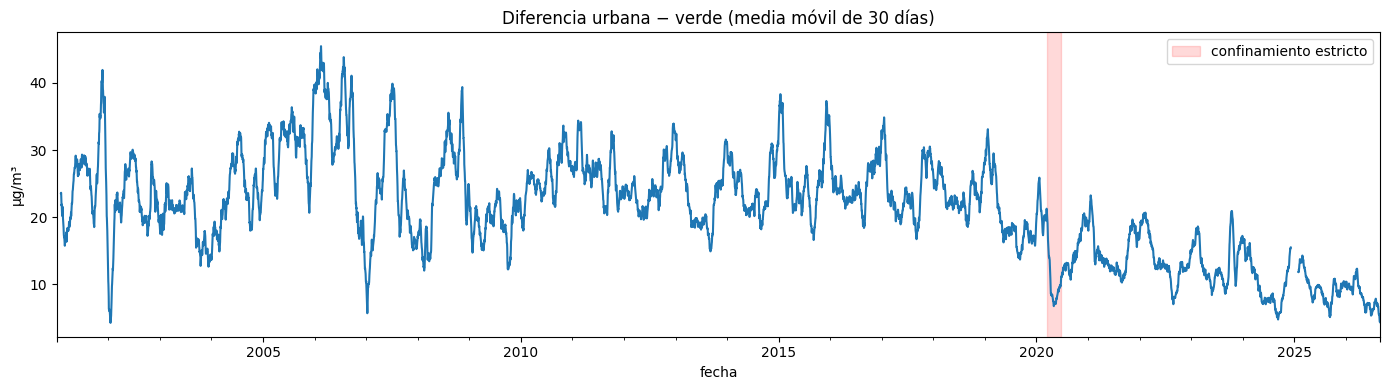

Diferencia urbana-verde: 2019 19.8 | confinamiento 8.7 | resto 2020 17.1


In [62]:
media_anual = series_imputada[["verde", "urbana"]].resample("YE").mean()
media_anual.index = media_anual.index.year
print("Media anual por grupo (µg/m³)")
display(media_anual.round(1))
print(f"\nAños que incumplen 40: verde {(media_anual['verde'] > 40).sum()}, urbana {(media_anual['urbana'] > 40).sum()}")
print(f"Años que incumplen 20: verde {(media_anual['verde'] > 20).sum()}, urbana {(media_anual['urbana'] > 20).sum()}")

media_mensual = series_imputada[["verde", "urbana"]].resample("ME").mean()
conteos = pd.DataFrame({
    "días >50 (verde)":   (series_imputada["verde"] > 50).groupby(series_imputada.index.year).sum(),
    "días >50 (urbana)":  (series_imputada["urbana"] > 50).groupby(series_imputada.index.year).sum(),
    "meses >40 (verde)":  (media_mensual["verde"] > 40).groupby(media_mensual.index.year).sum(),
    "meses >40 (urbana)": (media_mensual["urbana"] > 40).groupby(media_mensual.index.year).sum(),
})
print("\nDías y meses altos al año, por grupo")
display(conteos)

diferencia = (series_imputada["urbana"] - series_imputada["verde"]).rolling(30).mean()
fig, ax = plt.subplots(figsize=(14, 4))
diferencia.plot(ax=ax)
ax.axvspan(pd.Timestamp("2020-03-14"), pd.Timestamp("2020-06-21"), color="red", alpha=0.15, label="confinamiento estricto")
ax.set_title("Diferencia urbana − verde (media móvil de 30 días)")
ax.set_ylabel("µg/m³")
ax.legend()
plt.tight_layout()
plt.show()

d_2019 = (series_imputada.loc["2019", "urbana"] - series_imputada.loc["2019", "verde"]).mean()
d_confinamiento = (series_imputada.loc["2020-03-14":"2020-06-21", "urbana"] - series_imputada.loc["2020-03-14":"2020-06-21", "verde"]).mean()
resto_2020 = pd.concat([series_imputada.loc["2020-01-01":"2020-03-13"], series_imputada.loc["2020-06-22":"2020-12-31"]])
d_resto_2020 = (resto_2020["urbana"] - resto_2020["verde"]).mean()
print(f"Diferencia urbana-verde: 2019 {d_2019:.1f} | confinamiento {d_confinamiento:.1f} | resto 2020 {d_resto_2020:.1f}")

**Análisis de los resultados**

- **La brecha entre verde y urbana es enorme y constante.** En 2025, la media anual es 14,8 µg/m³ en verde frente a 24,3 en urbana: la urbana casi dobla a la verde, un patrón que se repite los 26 años de la serie.
- **Frente a los límites legales, el contraste es claro.** Con el límite vigente (40), verde no lo ha incumplido nunca y urbana lo incumplió 19 de 26 años. Con el de 2030 (20), ya incumple también la verde (16 años), pero la urbana casi siempre (25 de 26).
- **La caída es real y está bien documentada.** Los días por encima de 50 en la serie urbana pasan de 242 en 2001 a 1 en 2026; los meses por encima de 40, de 12 de 12 a 0.
- **El confinamiento de 2020 es el resultado más fuerte de todo el bloque.** La diferencia media urbana-verde era de 19,8 µg/m³ en 2019; durante el confinamiento estricto bajó a 8,7, menos de la mitad; y en el resto de 2020 volvió a 17,1. Es justo el argumento que buscábamos: la diferencia se estrecha cuando cae el tráfico y se recupera en cuanto vuelve, lo que apunta al tráfico como factor, sin necesidad de afirmar causalidad directamente.

## 10. Resultados y conclusiones

### 10.1 ¿Qué modelo predice mejor?

MAE en test de la serie general, con el mejor modelo de cada familia, sobre las mismas fechas (µg/m³):

| Modelo | 1 día | 1 semana | 1 mes |
|---|---|---|---|
| naive | 5,87 | 8,75 | 9,60 |
| SARIMAX | 5,19 | 6,88 | 7,66 |
| `Ridge_dif_cal` | **5,16** | **6,85** | **7,17** |
| `RF_cal` | 5,49 | 7,48 | 8,49 |
| `LSTM_cal` | 7,42 | 7,72 | 7,89 |

- **`Ridge_dif_cal` es el modelo más fiable del proyecto.** Es el mejor en 7 de las 9 combinaciones de serie y horizonte.
- **Cuanto más lejos se predice, más se nota modelar.** Frente al naive, `Ridge_dif_cal` reduce el MAE un 12 % a 1 día, un 22 % a 1 semana y un 25 % a 1 mes. Mañana se parece mucho a hoy, así que a 1 día hay poco margen para mejorar a la persistencia.
- **Lo que de verdad ayuda es poco y sencillo: diferenciar y añadir el calendario.** Diferenciar evita que los modelos vuelvan a la media histórica, muy por encima de los niveles actuales. El calendario recoge el efecto del fin de semana. Ningún modelo ha necesitado nada más sofisticado para ser el mejor.
- **La misma técnica no sirve igual a todos los modelos.** Diferenciar es clave en ARIMA y en Ridge, pero hunde a Random Forest y a la LSTM a 1 mes (18,58 en `RF_dif` y 13,62 en `LSTM_dif_cal`). En ambos casos se predicen cambios diarios y el nivel se reconstruye sumándolos, así que los errores se acumulan.
- **Más complejidad no ha compensado.** Ni Random Forest ni la LSTM superan a una regresión lineal con buenas variables. Además, la búsqueda de Ridge en las tres series tarda menos de un minuto, frente a algo más de media hora la de la LSTM con una sola configuración.

### 10.2 Respuesta a los objetivos

- **Indicadores.** Las tres series (general, verde y urbana) resumen bien el comportamiento de la ciudad y se parecen mucho entre sí: bajan a la vez y comparten los mismos ciclos, lo que apunta a factores comunes a todo Madrid.
- **Patrones.** El NO2 ha bajado de forma sostenida desde 2001, es claramente más alto en invierno y baja el fin de semana. Además, depende mucho del día anterior (autocorrelación de 0,80 en el retardo 1), lo que explica que el naive sea tan difícil de batir a 1 día.
- **Aviso a 1 día.** Con el umbral de la OMS (25 µg/m³), `Ridge_dif_cal` detecta los mismos días altos que el naive (62 %), pero con menos falsas alarmas (de 56 a 46). El umbral de 50 µg/m³ ya casi no se supera (3 días en la serie general en todo el test), así que no se puede evaluar bien.
- **Aviso a medio plazo.** Redefinir el horizonte mensual como la media de los 30 días siguientes fue un acierto: es más útil en la práctica y es donde el modelo más aporta. Con el límite de 2030 (20 µg/m³), la detección sube del 79 % al 84 % y el error de la media mensual baja en torno a un 20 %. El límite vigente de 40 µg/m³ no se supera en ningún momento del test.
- **Zonas verdes frente a urbanas.** La serie urbana es entre 1,6 y 2,4 veces la verde todos los años. Durante el confinamiento de 2020, la diferencia entre ambas cayó de 19,8 a 8,7 µg/m³ y volvió a 17,1 después, lo que apunta al tráfico como lo que más las separa. Frente al límite de 2030, la serie verde lo supera en 16 de los 26 años, y la urbana en 25.
- **Meteorología.** La lluvia y el viento del día anterior apenas mejoran la predicción a 1 día (del 0,5 % al 2,4 % en SARIMAX y Ridge, hasta un 5,6 % en Random Forest), probablemente porque su efecto ya está recogido en el NO2 de ese mismo día, y a la LSTM le perjudican.

### 10.3 Limitaciones

- **El test es un periodo de niveles bajos.** En 2025-2026 hay muy pocos episodios altos, lo que limita la evaluación de las alertas, sobre todo con los umbrales de 50 y 40 µg/m³.
- **El hueco de diciembre de 2024 reduce las fechas evaluables.** Obliga a descartar los primeros orígenes del test, y en la comparación con meteorología deja solo 243 días, todos de 2026.
- **Las series son medias de varias estaciones**, así que pueden ocultar episodios locales en estaciones concretas.

### 10.4 Idea final

El resultado más útil del proyecto no es un modelo complejo, sino la combinación de un modelo sencillo con las variables adecuadas y una evaluación honesta: partición temporal, backtesting y comparación siempre frente a un naive y sobre las mismas fechas. Con eso, `Ridge_dif_cal` mejora a la persistencia en torno a un 25 % a 1 mes, anticipa periodos de contaminación alta con un mes de margen y da menos falsas alarmas que la regla más simple.